# Deteksi Misinformasi Berbahasa Indonesia Menggunakan Temporal Graph Neural Network (TGNN) pada Twitter/X

Notebook ini berisi seluruh tahapan eksperimen penelitian, mulai dari persiapan data mentah hingga pelatihan dan evaluasi tiga model pembanding: MLP (tanpa graf), Static GCN (graf tanpa komponen temporal), dan Temporal GNN (graf dengan komponen temporal). Setiap section disusun agar dapat dijalankan secara berurutan dari atas ke bawah tanpa bergantung pada state yang tertimpa oleh cell lain.

Definisi arsitektur penelitian yang digunakan sepanjang notebook ini adalah sebagai berikut. Node merepresentasikan satu tweet. Edge merepresentasikan kemiripan semantik antar tweet, dihitung dari cosine similarity embedding IndoBERT. Fitur node berupa embedding IndoBERT yang dibekukan (frozen, tidak di-fine-tune). Informasi temporal berupa waktu unggah tweet, yang diperoleh dari dekode Twitter Snowflake ID.


In [1]:
import sys
import torch
import transformers
import huggingface_hub

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
HuggingFace Hub: 1.33.0
CUDA available: True


## Section 1 — Persiapan Data

Section ini melakukan pemuatan dataset mentah, penyaringan label, ekstraksi timestamp asli dari Twitter Snowflake ID, pembersihan teks, dan penghapusan data duplikat. Seluruh proses pada section ini merupakan tahap fondasi yang menghasilkan dataframe bersih (`df`) yang menjadi masukan bagi seluruh tahap selanjutnya.

In [2]:
import glob, os

_candidates = glob.glob('/kaggle/input/**/*.csv', recursive=True)
_matches = [p for p in _candidates if ('hoax' in p.lower() or 'umpo' in p.lower())]

if _matches:
    DATA_PATH = _matches[0]
    print(f"Dataset ditemukan otomatis: {DATA_PATH}")
elif _candidates:
    DATA_PATH = _candidates[0]
    print(f"Tidak ada nama yang cocok persis, memakai CSV pertama yang ditemukan: {DATA_PATH}")
else:
    DATA_PATH = None
    print("Tidak ada CSV ditemukan di /kaggle/input/. Pastikan dataset sudah ditambahkan lewat 'Add Input'.")

assert DATA_PATH is not None, "DATA_PATH belum terisi -- set manual path csv-nya di sel ini."

import pandas as pd
dataset = pd.read_csv(DATA_PATH)
dataset.head()

Dataset ditemukan otomatis: /kaggle/input/datasets/tiararf/datasetx/datasetUMPOHoax (2).csv


,topik,keyword,tweet,gambar,url,label
0,Air Garam,Air garam sumber energi,Mahasiswa ITS buat pembangkit listrik dari kol...,NaN,https://twitter.com/Klik_iT_indo/status/370802...,hoax
1,Air Garam,Air garam sumber energi,Lampu Dengan Sumber Energi Air Garam Ini Berpo...,NaN,https://twitter.com/Robin_nugraha/status/62854...,hoax
2,Air Garam,Air garam sumber energi,#didUknow Lampu LED yang menggunakan air dan g...,NaN,https://twitter.com/SerbaTauID/status/24731045...,hoax
3,Air Garam,Air garam sumber energi,#tekno Lampu Dengan Sumber Energi Air Garam In...,NaN,https://twitter.com/elrafa_agba/status/6285494...,hoax
4,Air Garam,Air garam sumber energi,"Green House,lampu darurat dg sumber energi gar...",NaN,https://twitter.com/HisenseID/status/761396317...,hoax


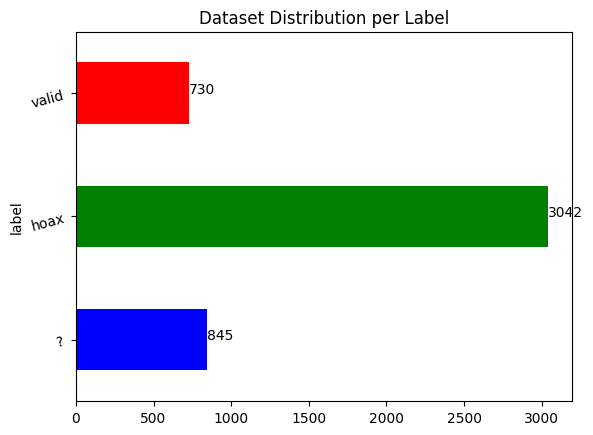

In [3]:
import matplotlib.pyplot as plt

d = dataset.groupby(['label'])['label'].count()
d.plot.barh(rot=15, title="Dataset Distribution per Label", color=['b', 'g', 'r'])
for index, value in enumerate(d):
    plt.text(value, index, str(value))
plt.show(block=True);

In [4]:
df = dataset[dataset['label'].isin(['hoax', 'valid'])].copy()
print(f"Sisa data setelah buang label '?': {len(df)}")
print(df['label'].value_counts())

Sisa data setelah buang label '?': 3772
label
hoax     3042
valid     730
Name: count, dtype: int64


In [5]:
import re
from datetime import datetime, timezone

TWITTER_EPOCH_MS = 1288834974657
MIN_VALID_SNOWFLAKE_ID = 2_90000_00000_00000  # ~2011, batas aman awal Snowflake asli

df = dataset[dataset['label'].isin(['hoax', 'valid'])].copy()

def extract_tweet_id(url):
    if pd.isna(url):
        return None
    m = re.search(r'status(?:es)?/(\d+)', str(url))
    return int(m.group(1)) if m else None

def snowflake_to_datetime(tweet_id):
    if tweet_id is None or pd.isna(tweet_id) or tweet_id < MIN_VALID_SNOWFLAKE_ID:
        return pd.NaT
    ts_ms = (int(tweet_id) >> 22) + TWITTER_EPOCH_MS
    return datetime.fromtimestamp(ts_ms / 1000, tz=timezone.utc)

df['tweet_id'] = df['url'].apply(extract_tweet_id)
df['waktu_posting'] = df['tweet_id'].apply(snowflake_to_datetime)

n_before = len(df)
df = df.dropna(subset=['waktu_posting']).reset_index(drop=True)
print(f"Baris dengan timestamp asli & valid: {len(df)} / {n_before} ({len(df)/n_before*100:.1f}%)")

Baris dengan timestamp asli & valid: 3679 / 3772 (97.5%)


In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['tweet'] = df['tweet'].fillna('').apply(clean_text)
n_before = len(df)
df = df[df['tweet'].str.strip() != ''].reset_index(drop=True)
print(f"Baris terbuang karena tweet kosong: {n_before - len(df)}")

Baris terbuang karena tweet kosong: 18


In [7]:
dupes = df.duplicated(subset='tweet').sum()
print(f"Tweet duplikat ditemukan: {dupes}")

n_before = len(df)
df = df.drop_duplicates(subset='tweet').reset_index(drop=True)
print(f"Baris terbuang karena duplikat: {n_before - len(df)}")

Tweet duplikat ditemukan: 134
Baris terbuang karena duplikat: 134


### [TAMBAHAN] Pemeriksaan Near-Duplicate Berbasis Teks

Duplikat eksak (teks identik persis) sudah dibuang di atas. Namun, ditemukan sejumlah pasangan tweet yang teksnya **hampir identik** saat dicek belakangan lewat kemiripan embedding IndoBERT. Supaya pembersihan ini tetap terjadi di tahap awal sebelum `node_id`, split, dan embedding dibuat, near-duplicate di sini dideteksi memakai kemiripan **TF-IDF character n-gram**.

Untuk tiap pasangan near-duplicate (similarity > 0.95), tweet yang **lebih baru** (waktu posting lebih akhir) dibuang, tweet yang **lebih lama** dipertahankan.

**Catatan:** langkah ini HANYA untuk mencari tweet yang teksnya mirip lalu membuang salah satunya. Fitur yang benar-benar dipakai untuk melatih model klasifikasi (MLP, Static GCN, TGNN) tetap 100% berasal dari IndoBERT yang dihasilkan terpisah di Section 5–6.

In [8]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as _cos_sim

_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=1)
_tfidf = _vectorizer.fit_transform(df['tweet'].tolist())
_sim = _cos_sim(_tfidf)
np.fill_diagonal(_sim, 0)

_iu = np.triu_indices_from(_sim, k=1)
_near_dup_mask = _sim[_iu] > 0.95
_pairs = np.array(list(zip(_iu[0][_near_dup_mask], _iu[1][_near_dup_mask])))

print(f"Jumlah pasangan near-duplicate (TF-IDF char n-gram similarity > 0.95): {len(_pairs)}")

_to_drop = set()
for a, b in _pairs:
    if df.loc[a, 'waktu_posting'] <= df.loc[b, 'waktu_posting']:
        _to_drop.add(b)
    else:
        _to_drop.add(a)

print(f"Jumlah baris yang akan dibuang (versi tweet yang lebih baru dari pasangan near-dup): {len(_to_drop)}")
if len(_pairs) > 0:
    print("\nContoh 5 pasangan pertama:")
    for a, b in _pairs[:5]:
        print(f" - [{a}] {df.loc[a,'tweet'][:60]!r}  <->  [{b}] {df.loc[b,'tweet'][:60]!r}")

n_before_neardup = len(df)
df = df.drop(index=list(_to_drop)).reset_index(drop=True)
print(f"\n✅ Baris terbuang karena near-duplicate: {n_before_neardup - len(df)}")
print(f"Sisa data: {len(df)}")

Jumlah pasangan near-duplicate (TF-IDF char n-gram similarity > 0.95): 55
Jumlah baris yang akan dibuang (versi tweet yang lebih baru dari pasangan near-dup): 48

Contoh 5 pasangan pertama:
 - [49] 'geger induk kambing melahirkan makhluk setengah babi setenga'  <->  [53] 'induk kambing melahirkan makhluk setengah babi setengah manu'
 - [143] 'ceker dan sayap ayam bisa menyebabkan kanker untuk wanita ca'  <->  [1870] 'ceker sayap ayam bisa menyebabkan kanker untuk wanita cari i'
 - [166] 'bareskrim ringkus penjual kripik jamur bernarkoba penyidik d'  <->  [167] 'bareskrim ringkus penjual kripik jamur bernarkoba penyidik d'
 - [173] 'biaya tilang terbaru di indonesia kapolri baru mantab sebaga'  <->  [1134] 'biaya tilang terbaru di indonesia kapolri baru mantap 1 tida'
 - [175] 'biaya tilang terbaru di indonesia kapolri baru mantab 1 tida'  <->  [176] 'biaya tilang terbaru di indonesia kapolri baru mantap 1 tida'

✅ Baris terbuang karena near-duplicate: 48
Sisa data: 3479


In [9]:
df['label'] = df['label'].map({'valid': 0, 'hoax': 1}).astype(int)
df = df.drop(columns=[c for c in ['gambar','url','keyword','topik','tweet_id'] if c in df.columns])
df = df.sort_values('waktu_posting').reset_index(drop=True)

print(f"\n✅ Dataset final: {df.shape}")
print(df['label'].value_counts())
print(f"Rentang waktu: {df['waktu_posting'].min()} s/d {df['waktu_posting'].max()}")
df.head()


✅ Dataset final: (3479, 3)
label
1    2798
0     681
Name: count, dtype: int64
Rentang waktu: 2010-11-15 00:10:02.355000+00:00 s/d 2021-09-10 14:28:22.545000+00:00


,tweet,label,waktu_posting
0,memelototin payudara prmpuan slama 10 menit dp...,1,2010-11-15 00:10:02.355000+00:00
1,ajinomoto ada babi dalam mangkok merah pembunu...,1,2010-11-17 12:16:49.509000+00:00
2,wuakakakakakakakaka rt gajah berkaki lima rt b...,1,2010-11-19 11:44:29.686000+00:00
3,hore makan pagi pake oatmeal awal yg bagus unt...,1,2010-12-02 23:18:31.290000+00:00
4,jangan ajinomoto pake babi ga mau ah edisibada...,1,2010-12-27 02:59:49.554000+00:00


In [10]:
df.tail()

,tweet,label,waktu_posting
3474,queen elizabeth demands first signed ronaldo m...,1,2021-09-02 07:09:50.346000+00:00
3475,if dem fit give us lamba say queen elizabeth w...,1,2021-09-03 09:29:48.769000+00:00
3476,jangan kaget hakim yang tolak banding hrs memo...,1,2021-09-06 02:44:56.868000+00:00
3477,the cristiano ronaldo effect fire queen elizab...,1,2021-09-07 18:33:57.502000+00:00
3478,setelah vaksin sebisa mungkin gak konsumsi sod...,1,2021-09-10 14:28:22.545000+00:00


📊 Imbalance ratio (hoax:valid) = 4.11:1


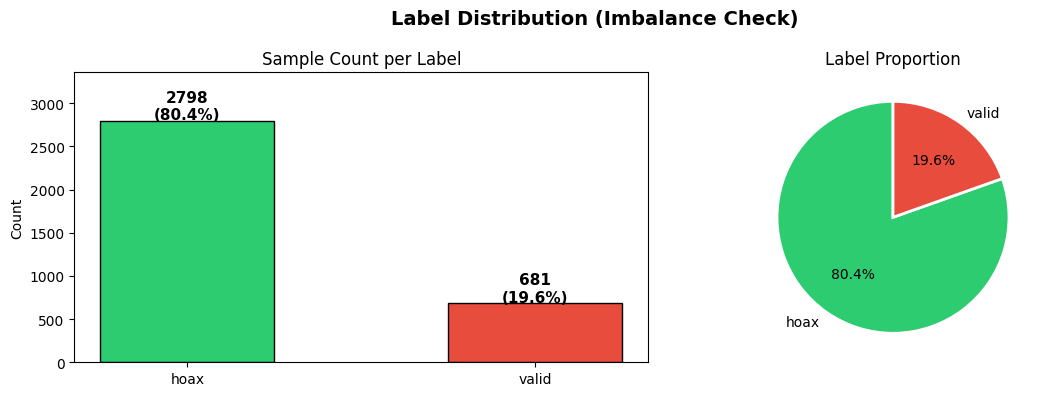

In [11]:
df['label_str'] = df['label'].map({0: 'valid', 1: 'hoax'})
label_counts = df['label_str'].value_counts()
total = len(df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Label Distribution (Imbalance Check)', fontsize=14, fontweight='bold')

colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(label_counts.index, label_counts.values, color=colors, edgecolor='black', width=0.5)
for bar, val in zip(bars, label_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{val}\n({val/total*100:.1f}%)', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Sample Count per Label')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, label_counts.max() * 1.2)

axes[1].pie(label_counts.values, labels=label_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Label Proportion')

ratio = label_counts.max() / label_counts.min()
print(f"📊 Imbalance ratio (hoax:valid) = {ratio:.2f}:1")

plt.tight_layout()
plt.savefig('eda1_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

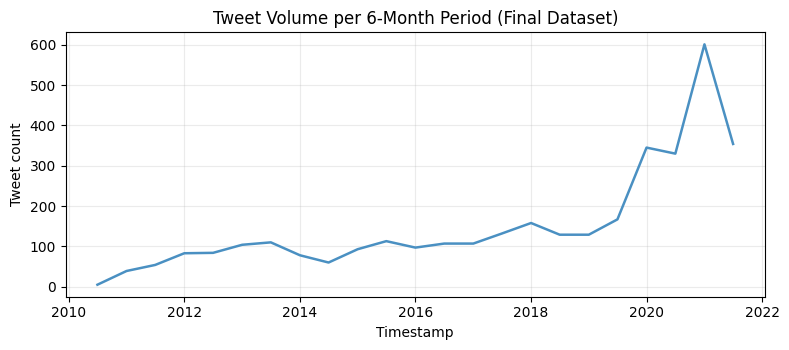

2020-01-01    345
2020-07-01    330
2021-01-01    601
2021-07-01    354
Freq: 6MS, Name: count, dtype: int64


In [12]:
# Gambar 4 naskah: volume tweet per periode 6 bulan (dataset final)
ts = pd.to_datetime(df['waktu_posting'], utc=True).dt.tz_localize(None)
half_start = pd.to_datetime(dict(year=ts.dt.year, month=np.where(ts.dt.month <= 6, 1, 7), day=1))
counts = half_start.value_counts().sort_index()
full_idx = pd.date_range(counts.index.min(), counts.index.max(), freq="6MS")
counts = counts.reindex(full_idx, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(counts.index, counts.values, color="#4a90c2", lw=1.8)
ax.set_title("Tweet Volume per 6-Month Period (Final Dataset)", fontsize=12)
ax.set_xlabel("Timestamp")
ax.set_ylabel("Tweet count")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("eda_tweet_volume_6month.png", dpi=300, bbox_inches="tight")
plt.show()
print(counts.tail(4))   # periode terakhir (Jul-Sep 2021) hanya parsial

Baris dengan label `?` dibuang karena tidak memiliki ground truth yang jelas untuk tugas klasifikasi biner (hoax vs valid). Timestamp diambil dari Twitter Snowflake ID yang di-decode dari kolom `url`, disaring dengan batas ID minimum untuk menghindari hasil decode yang tidak valid, sehingga merepresentasikan waktu unggah tweet yang sesungguhnya, bukan urutan baris atau nilai sintetis. Teks tweet dibersihkan (penghapusan URL, mention, dan simbol non-alfanumerik) sebelum data disortir secara kronologis berdasarkan `waktu_posting`.

## Section 2 — Penetapan Identitas Node

Dataframe `df` dari Section 1 telah diurutkan secara kronologis dan di-reset index-nya, sehingga index tersebut bersifat unik dan konsisten dengan urutan waktu. Index ini ditetapkan sebagai `node_id`, yaitu identitas tetap bagi setiap tweet yang digunakan secara konsisten pada seluruh tahap pembentukan graf, embedding, dan evaluasi selanjutnya.

In [13]:
df['node_id'] = df.index
n_nodes = len(df)
print(f"Total node: {n_nodes}")
print(f"node_id sudah unik & berurutan waktu: {(df['node_id'].values == range(n_nodes)).all()}")
df[['node_id', 'label', 'waktu_posting']].head()

Total node: 3479
node_id sudah unik & berurutan waktu: True


,node_id,label,waktu_posting
0,0,1,2010-11-15 00:10:02.355000+00:00
1,1,1,2010-11-17 12:16:49.509000+00:00
2,2,1,2010-11-19 11:44:29.686000+00:00
3,3,1,2010-12-02 23:18:31.290000+00:00
4,4,1,2010-12-27 02:59:49.554000+00:00


## Section 3 — Konfigurasi dan Reproducibility

Seluruh parameter eksperimen dikumpulkan pada satu struktur konfigurasi (`Config`) agar setiap keputusan desain terdokumentasi secara eksplisit dan dapat ditelusuri.

**[REVISI — Fair Comparison, per catatan dosen]** Untuk memastikan perbandingan antar model (MLP, Static GCN, TGNN) berlangsung adil, jumlah neighbor/Top-K disamakan menjadi `TOP_K = 4` dan `TOP_K_TGNN = 4`, sehingga graf yang mendasari Static GCN dan TGNN dibangun dengan jumlah tetangga yang identik. Nilai `SELF_LOOP_WEIGHT` dan `SELF_LOOP_WEIGHT_TGNN` juga diseragamkan menjadi `1.0`.

**[REVISI — Fair Comparison]** Fungsi loss juga disamakan untuk ketiga model: MLP, Static GCN, dan TGNN seluruhnya dilatih menggunakan **weighted cross-entropy** (bobot dari `class_weights`) sesuai arahan pembimbing.

Fungsi `set_seed` memastikan seluruh proses stokastik (inisialisasi bobot, pembagian batch, dropout) dapat direproduksi.

In [14]:
import random
import warnings
from dataclasses import dataclass, asdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    f1_score, roc_auc_score, confusion_matrix
)

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

@dataclass
class Config:
    SEED: int = 42
    SEEDS_MULTIRUN: tuple = (42, 123, 2024, 7, 999)

    TRAIN_RATIO: float = 0.70
    VAL_RATIO: float = 0.15
    TEST_RATIO: float = 0.15

    N_SNAPSHOTS_TRAIN: int = 8
    N_SNAPSHOTS_VAL: int = 2
    N_SNAPSHOTS_TEST: int = 2

    MODEL_NAME: str = "indobenchmark/indobert-base-p1"
    MAX_LENGTH: int = 64
    EMBEDDING_DIM: int = 768
    EMBEDDING_BATCH_SIZE: int = 32
    EMBEDDING_CACHE_PATH: str = "/kaggle/working/artifacts/embeddings.npy"

    # Konfigurasi Fair Comparison (Top-K = 4, Self-Loop = 1.0)
    TOP_K: int = 4
    TOP_K_TGNN: int = 4
    SELF_LOOP_WEIGHT: float = 1.0
    SELF_LOOP_WEIGHT_TGNN: float = 1.0

    SIMILARITY_THRESHOLD: float = None

    HIDDEN_DIM: int = 128
    DROPOUT: float = 0.3
    GCN_LAYERS: int = 1

    LEARNING_RATE: float = 1e-3
    WEIGHT_DECAY: float = 1e-5
    EPOCHS: int = 100
    PATIENCE: int = 10
    GRAD_CLIP: float = 5.0

    ARTIFACT_DIR: str = "/kaggle/working/artifacts"

import os, json as json_lib
CFG = Config()
os.makedirs(CFG.ARTIFACT_DIR, exist_ok=True)

assert CFG.TOP_K_TGNN == CFG.TOP_K, "[REVISI - FAIRNESS] TOP_K_TGNN harus sama dengan TOP_K untuk perbandingan yang adil."

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG.SEED)
print(json_lib.dumps({k: v for k, v in asdict(CFG).items()}, indent=2, default=str))

Using device: cuda
{
  "SEED": 42,
  "SEEDS_MULTIRUN": [
    42,
    123,
    2024,
    7,
    999
  ],
  "TRAIN_RATIO": 0.7,
  "VAL_RATIO": 0.15,
  "TEST_RATIO": 0.15,
  "N_SNAPSHOTS_TRAIN": 8,
  "N_SNAPSHOTS_VAL": 2,
  "N_SNAPSHOTS_TEST": 2,
  "MODEL_NAME": "indobenchmark/indobert-base-p1",
  "MAX_LENGTH": 64,
  "EMBEDDING_DIM": 768,
  "EMBEDDING_BATCH_SIZE": 32,
  "EMBEDDING_CACHE_PATH": "/kaggle/working/artifacts/embeddings.npy",
  "TOP_K": 4,
  "TOP_K_TGNN": 4,
  "SELF_LOOP_WEIGHT": 1.0,
  "SELF_LOOP_WEIGHT_TGNN": 1.0,
  "SIMILARITY_THRESHOLD": null,
  "HIDDEN_DIM": 128,
  "DROPOUT": 0.3,
  "GCN_LAYERS": 1,
  "LEARNING_RATE": 0.001,
  "WEIGHT_DECAY": 1e-05,
  "EPOCHS": 100,
  "PATIENCE": 10,
  "GRAD_CLIP": 5.0,
  "ARTIFACT_DIR": "/kaggle/working/artifacts"
}


## Section 4 — Pembagian Data Temporal (Train / Validation / Test)

Data dibagi menjadi subset pelatihan, validasi, dan pengujian berdasarkan urutan waktu, bukan secara acak. Proporsi yang digunakan adalah 70% data paling awal untuk pelatihan, 15% berikutnya untuk validasi, dan 15% data paling akhir untuk pengujian. Pendekatan ini dipilih agar evaluasi model merepresentasikan kondisi realistis, yaitu memprediksi tweet yang muncul setelah periode pelatihan, sekaligus mencegah kebocoran informasi dari masa depan ke masa lalu. Proporsi 70/15/15 dipilih agar subset pengujian tetap memiliki jumlah sampel kelas minoritas (`valid`) yang cukup untuk menghasilkan estimasi F1 yang stabil.

In [15]:
df_sorted = df.sort_values("waktu_posting").reset_index(drop=True)
assert (df_sorted["node_id"].values == df["node_id"].values).all(), "df harusnya sudah terurut dari Section 1, cek ulang."

n = len(df_sorted)
n_train = int(n * CFG.TRAIN_RATIO)
n_val = int(n * CFG.VAL_RATIO)
n_test = n - n_train - n_val

df_train = df_sorted.iloc[:n_train].copy()
df_val = df_sorted.iloc[n_train:n_train + n_val].copy()
df_test = df_sorted.iloc[n_train + n_val:].copy()

df_train["split"] = "train"
df_val["split"] = "val"
df_test["split"] = "test"

print(f"Train: {len(df_train)} ({df_train['waktu_posting'].min()} -> {df_train['waktu_posting'].max()})")
print(f"Val  : {len(df_val)} ({df_val['waktu_posting'].min()} -> {df_val['waktu_posting'].max()})")
print(f"Test : {len(df_test)} ({df_test['waktu_posting'].min()} -> {df_test['waktu_posting'].max()})")

print("\nDistribusi label per split (0=valid, 1=hoax):")
for name, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    vc = d["label"].value_counts()
    print(f"  {name}: {dict(vc)}  (minority 'valid' ratio: {vc.get(0,0)/len(d):.3f})")

assert df_train["waktu_posting"].max() <= df_val["waktu_posting"].min()
assert df_val["waktu_posting"].max() <= df_test["waktu_posting"].min()
print("\nValidasi leakage waktu: OK, train <= val <= test secara kronologis.")

df_split = pd.concat([df_train, df_val, df_test]).sort_values("node_id").reset_index(drop=True)
idx_train = df_train["node_id"].values
idx_val = df_val["node_id"].values
idx_test = df_test["node_id"].values

print(f"\nIndeks node berhasil dibuat: Train={len(idx_train)}, Val={len(idx_val)}, Test={len(idx_test)}")

Train: 2435 (2010-11-15 00:10:02.355000+00:00 -> 2020-11-16 03:00:59.634000+00:00)
Val  : 521 (2020-11-16 04:03:00.297000+00:00 -> 2021-06-09 23:30:00.208000+00:00)
Test : 523 (2021-06-09 23:35:37.813000+00:00 -> 2021-09-10 14:28:22.545000+00:00)

Distribusi label per split (0=valid, 1=hoax):
  train: {1: np.int64(2009), 0: np.int64(426)}  (minority 'valid' ratio: 0.175)
  val: {1: np.int64(385), 0: np.int64(136)}  (minority 'valid' ratio: 0.261)
  test: {1: np.int64(404), 0: np.int64(119)}  (minority 'valid' ratio: 0.228)

Validasi leakage waktu: OK, train <= val <= test secara kronologis.

Indeks node berhasil dibuat: Train=2435, Val=521, Test=523


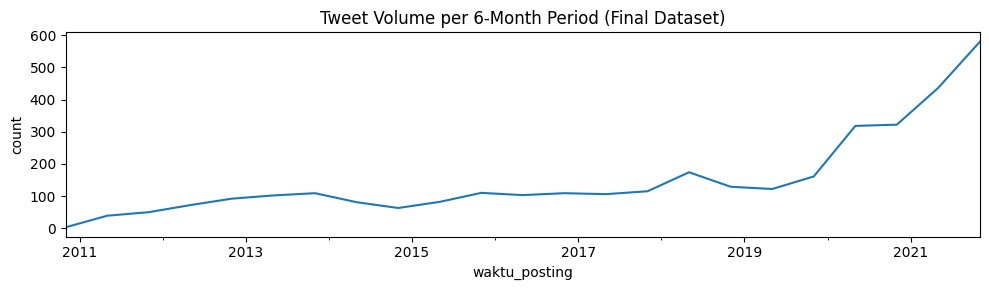

Distribusi per split:
  train: 2010-11-15 s/d 2020-11-16, n=2435
  val: 2020-11-16 s/d 2021-06-09, n=521
  test: 2021-06-09 s/d 2021-09-10, n=523


In [16]:
fig, ax = plt.subplots(figsize=(10, 3))
df_split.set_index("waktu_posting")["label"].resample("6ME").count().plot(ax=ax)
ax.set_title("Tweet Volume per 6-Month Period (Final Dataset)")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

print("Distribusi per split:")
for name in ["train", "val", "test"]:
    d = df_split[df_split["split"] == name]
    print(f"  {name}: {d['waktu_posting'].min().date()} s/d {d['waktu_posting'].max().date()}, n={len(d)}")

## Section 5 — Pemuatan Model IndoBERT

Model `indobenchmark/indobert-base-p1` dimuat dan dibekukan (frozen), artinya parameter model tidak diperbarui selama pelatihan model klasifikasi. Keputusan ini diambil karena ukuran dataset yang relatif kecil (sekitar 3479 tweet setelah pembersihan), sehingga fine-tuning penuh terhadap model BERT berisiko menyebabkan overfitting dan menambah kompleksitas yang tidak diperlukan.

In [17]:
tokenizer = AutoTokenizer.from_pretrained(CFG.MODEL_NAME)
bert_model = AutoModel.from_pretrained(CFG.MODEL_NAME).to(device)
bert_model.eval()
for p in bert_model.parameters():
    p.requires_grad = False
print("IndoBERT loaded & frozen. Params:", sum(p.numel() for p in bert_model.parameters()))

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

IndoBERT loaded & frozen. Params: 124441344


## Section 6 — Pembangkitan dan Penyimpanan Representasi Embedding

Representasi embedding untuk setiap tweet dihasilkan melalui mean-pooling terhadap seluruh token embedding pada lapisan output IndoBERT, bukan hanya token `[CLS]`, karena pendekatan ini memberikan representasi yang lebih stabil untuk teks pendek seperti tweet. Embedding dihitung dari kolom `tweet` sebagaimana adanya dari Section 1, tanpa pembersihan tambahan. Hasil embedding disimpan ke berkas `.npy` agar tidak perlu dihitung ulang pada eksekusi berikutnya.

In [18]:
def mean_pooling(token_embeddings, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    summed = torch.sum(token_embeddings * mask, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

@torch.no_grad()
def generate_embeddings(texts, batch_size=32):
    all_emb = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        enc = tokenizer(batch, padding=True, truncation=True,
                         max_length=CFG.MAX_LENGTH, return_tensors="pt").to(device)
        out = bert_model(**enc)
        pooled = mean_pooling(out.last_hidden_state, enc["attention_mask"])
        all_emb.append(pooled.cpu().numpy())
    return np.concatenate(all_emb, axis=0)

if os.path.exists(CFG.EMBEDDING_CACHE_PATH):
    embeddings = np.load(CFG.EMBEDDING_CACHE_PATH)
    print("Load embedding dari cache:", embeddings.shape)
    assert embeddings.shape[0] == len(df_split), "Cache tidak cocok jumlah data saat ini, hapus cache dan generate ulang."
else:
    texts = df_split.sort_values("node_id")["tweet"].tolist()
    embeddings = generate_embeddings(texts, batch_size=CFG.EMBEDDING_BATCH_SIZE)
    np.save(CFG.EMBEDDING_CACHE_PATH, embeddings)
    print("Embedding digenerate & disimpan:", embeddings.shape)

embeddings_norm = embeddings / (np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-9)

Embedding digenerate & disimpan: (3479, 768)


## Section 7 — Diagnostik Kemiripan Semantik dan Pemeriksaan Near-Duplicate

Nilai ambang batas kemiripan (SIMILARITY_THRESHOLD) ditentukan dari distribusi cosine similarity antar embedding pada data training saja, menggunakan persentil ke-95. Nilai threshold kemudian dibekukan dan digunakan secara konsisten dalam konstruksi graph pada tahap training, validation, dan testing.

**[CATATAN REVISI]** Pemilihan persentil ke-95 belum disertai uji sensitivitas, dan pada praktiknya threshold ini hanya memangkas sebagian kecil slot Top-K (lihat Section 24). Sensitivitas threshold dan K diuji pada validasi di Section 26.

Cosine Similarity Distribution Across Training Tweets
count    200000.000000
mean          0.407777
std           0.092991
min           0.080168
50%           0.400504
90%           0.532960
95%           0.571785
99%           0.643070
max           0.946227
dtype: float64

SIMILARITY_THRESHOLD ditetapkan dari TRAIN ONLY (percentile-95) = 0.572


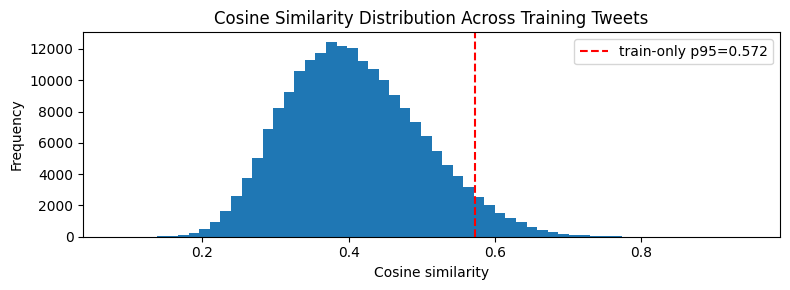

In [19]:
train_node_ids = np.sort(idx_train)
train_embeddings_norm = embeddings_norm[train_node_ids]
sim_matrix_train = train_embeddings_norm @ train_embeddings_norm.T
np.fill_diagonal(sim_matrix_train, -1)

iu_train = np.triu_indices_from(sim_matrix_train, k=1)
rng = np.random.default_rng(CFG.SEED)
sample_idx_train = rng.choice(len(iu_train[0]), size=min(200_000, len(iu_train[0])), replace=False)
sim_sample_train = sim_matrix_train[iu_train][sample_idx_train]

print("Cosine Similarity Distribution Across Training Tweets")
print(pd.Series(sim_sample_train).describe(percentiles=[.5, .9, .95, .99]))

p95_train = float(np.percentile(sim_sample_train, 95))
CFG.SIMILARITY_THRESHOLD = round(p95_train, 3)
print(f"\nSIMILARITY_THRESHOLD ditetapkan dari TRAIN ONLY (percentile-95) = {CFG.SIMILARITY_THRESHOLD}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sim_sample_train, bins=60)
ax.axvline(CFG.SIMILARITY_THRESHOLD, color="red", linestyle="--", label=f"train-only p95={CFG.SIMILARITY_THRESHOLD}")
ax.set_title("Cosine Similarity Distribution Across Training Tweets")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.show()

## Section 8 — Definisi Snapshot Temporal

Snapshot temporal dibentuk dengan pembagian equal-count secara kronologis, dialokasikan secara proporsional pada masing-masing subset: delapan snapshot pada rentang data pelatihan, dua pada validasi, dan dua pada pengujian, sehingga total dua belas snapshot. Alokasi proporsional ini memastikan batas snapshot tidak pernah melintasi batas antar subset pelatihan, validasi, dan pengujian, sehingga tidak terjadi percampuran data antar subset pada level snapshot.

**[CATATAN REVISI]** Pembagian equal-count menghasilkan durasi kalender snapshot yang sangat tidak seragam (lihat Section 24). Alokasi 8/2/2 tidak diuji terhadap alternatif lain; hal ini dicatat sebagai keputusan yang dasarnya harus dijelaskan di naskah.

In [20]:
def make_snapshot_bins(df_part, n_bins):
    idx_sorted = df_part.sort_values("waktu_posting")["node_id"].values
    return np.array_split(idx_sorted, n_bins)

snapshot_bins = []
snapshot_bins += make_snapshot_bins(df_train, CFG.N_SNAPSHOTS_TRAIN)
snapshot_bins += make_snapshot_bins(df_val, CFG.N_SNAPSHOTS_VAL)
snapshot_bins += make_snapshot_bins(df_test, CFG.N_SNAPSHOTS_TEST)

snapshot_split_label = (["train"] * CFG.N_SNAPSHOTS_TRAIN +
                         ["val"] * CFG.N_SNAPSHOTS_VAL +
                         ["test"] * CFG.N_SNAPSHOTS_TEST)

print(f"Total snapshot: {len(snapshot_bins)}")
for i, (b, s) in enumerate(zip(snapshot_bins, snapshot_split_label)):
    t_min = df_split.loc[df_split.node_id.isin(b), "waktu_posting"].min()
    t_max = df_split.loc[df_split.node_id.isin(b), "waktu_posting"].max()
    print(f"  snapshot {i:2d} [{s:5s}]: {len(b):4d} node, {t_min} -> {t_max}")

Total snapshot: 12
  snapshot  0 [train]:  305 node, 2010-11-15 00:10:02.355000+00:00 -> 2013-03-13 15:16:30.699000+00:00
  snapshot  1 [train]:  305 node, 2013-03-15 00:42:21.503000+00:00 -> 2014-11-26 00:46:37.308000+00:00
  snapshot  2 [train]:  305 node, 2014-11-30 07:56:56.608000+00:00 -> 2016-06-14 21:48:06.663000+00:00
  snapshot  3 [train]:  304 node, 2016-06-17 09:04:59.224000+00:00 -> 2017-11-02 08:05:10.541000+00:00
  snapshot  4 [train]:  304 node, 2017-11-07 05:47:15.905000+00:00 -> 2018-11-17 11:39:51.989000+00:00
  snapshot  5 [train]:  304 node, 2018-11-18 14:38:25.302000+00:00 -> 2019-12-08 01:11:16.280000+00:00
  snapshot  6 [train]:  304 node, 2019-12-08 14:21:39.925000+00:00 -> 2020-05-26 10:21:52.676000+00:00
  snapshot  7 [train]:  304 node, 2020-05-26 13:30:36.124000+00:00 -> 2020-11-16 03:00:59.634000+00:00
  snapshot  8 [val  ]:  261 node, 2020-11-16 04:03:00.297000+00:00 -> 2021-03-12 13:57:51.525000+00:00
  snapshot  9 [val  ]:  260 node, 2021-03-14 07:37:24.

## Section 9 — Konstruksi Graf (Kausal dan Akumulatif)

Edge antar node dibentuk dengan aturan kausal: sebuah node hanya dapat terhubung ke node lain yang waktu unggahnya lebih awal. Aturan ini diterapkan pada seluruh proses konstruksi graf untuk mencegah kebocoran informasi dari masa depan ke masa lalu.

Graf sengaja dibuat searah (directed), bukan undirected — edge hanya mengalir dari node lama (`source`) ke node baru (`target`). Karena graf searah, operasi graph convolution memakai normalisasi in-degree rata-rata.

Kedua graf (`edge_index_full` dan `edge_index_full_tgnn`) sekarang dibangun menggunakan `TOP_K = 4` yang identik untuk menjamin **Fair Comparison**.

In [21]:
n_nodes = len(embeddings_norm)
sim_matrix_full = embeddings_norm @ embeddings_norm.T

def build_causal_edges(top_k):
    edge_src, edge_dst = [], []
    for i in range(n_nodes):
        if i == 0:
            continue
        k = min(top_k, i)
        sims_to_past = sim_matrix_full[i, :i]
        top_k_idx = (
            np.argpartition(-sims_to_past, k - 1)[:k]
            if k > 0
            else np.array([], dtype=int)
        )
        top_k_idx = top_k_idx[
            sims_to_past[top_k_idx] >= CFG.SIMILARITY_THRESHOLD
        ]
        for j in top_k_idx:
            edge_src.append(int(j))
            edge_dst.append(i)
    return np.array([edge_src, edge_dst], dtype=np.int64)

# Graph untuk Static GCN
edge_index_full = build_causal_edges(CFG.TOP_K)

print(
    f"[StaticGCN] top_k={CFG.TOP_K}, "
    f"n_edges(directed)={edge_index_full.shape[1]}, "
    f"avg in-degree={edge_index_full.shape[1] / n_nodes:.2f}"
)

# Graph untuk TGNN
edge_index_full_tgnn = build_causal_edges(CFG.TOP_K_TGNN)

print(
    f"[TGNN] top_k={CFG.TOP_K_TGNN}, "
    f"n_edges(directed)={edge_index_full_tgnn.shape[1]}, "
    f"avg in-degree={edge_index_full_tgnn.shape[1] / n_nodes:.2f}"
)

same_edges = (edge_index_full.shape == edge_index_full_tgnn.shape) and np.array_equal(edge_index_full, edge_index_full_tgnn)
print(f"[Fairness check] edge_index_full == edge_index_full_tgnn (struktur identik): {same_edges}")

[StaticGCN] top_k=4, n_edges(directed)=13114, avg in-degree=3.77
[TGNN] top_k=4, n_edges(directed)=13114, avg in-degree=3.77
[Fairness check] edge_index_full == edge_index_full_tgnn (struktur identik): True


## Section 10 — Laporan Diagnostik Graf & Analisis Homophily

Section ini menyajikan statistik graf di setiap snapshot: jumlah node, jumlah edge, rata-rata in-degree, jumlah node terisolasi, serta distribusi label.

**[PENYEMPURNAAN — Analisis Homophily Snapshot Kumulatif & Step]**
Bagian ini dilengkapi dengan perhitungan **edge homophily kumulatif (`edge_homophily_cumul`)** dan **edge homophily step (`edge_homophily_step`)** untuk menjawab evaluasi dospem mengenai dinamika graf temporal TGNN. Seluruh metrik snapshot diekspor ke `tgnn_homophily_summary.csv`.

In [22]:
## =====================================================================
## Section 10 — Laporan Diagnostik Graf & Analisis Homophily Lengkap
## (Overall + Breakdown per Kelas: Valid & Hoax)
## =====================================================================

def snapshot_cumulative_nodes(snapshot_bins):
    cum, seen = [], np.array([], dtype=int)
    for b in snapshot_bins:
        seen = np.concatenate([seen, b])
        cum.append(np.sort(seen))
    return cum

cumulative_nodes_per_snapshot = snapshot_cumulative_nodes(snapshot_bins)
labels_all_np = df_split.sort_values("node_id")["label"].values

def compute_detailed_homophily(edge_idx, labels):
    """
    Menghitung Edge Homophily keseluruhan (overall)
    dan breakdown per kelas (class-wise homophily).
    Class-k homophily = rasio edge (k <-> k) terhadap total edge yang melibatkan simpul kelas k.
    """
    if edge_idx.shape[1] == 0:
        return float('nan'), float('nan'), float('nan')
    
    src_lbl = labels[edge_idx[0]]
    dst_lbl = labels[edge_idx[1]]
    
    # 1. Overall Edge Homophily
    overall_h = float(np.mean(src_lbl == dst_lbl))
    
    # 2. Homophily Kelas Valid (Label 0)
    mask_valid = (src_lbl == 0) | (dst_lbl == 0)
    if np.sum(mask_valid) > 0:
        valid_h = float(np.sum((src_lbl == 0) & (dst_lbl == 0)) / np.sum(mask_valid))
    else:
        valid_h = float('nan')
        
    # 3. Homophily Kelas Hoax (Label 1)
    mask_hoax = (src_lbl == 1) | (dst_lbl == 1)
    if np.sum(mask_hoax) > 0:
        hoax_h = float(np.sum((src_lbl == 1) & (dst_lbl == 1)) / np.sum(mask_hoax))
    else:
        hoax_h = float('nan')
        
    return overall_h, valid_h, hoax_h

# --- A. Homophily Static GCN ---
mask_train_e = np.isin(edge_index_full[0], idx_train) & np.isin(edge_index_full[1], idx_train)
gcn_train_overall, gcn_train_valid, gcn_train_hoax = compute_detailed_homophily(edge_index_full[:, mask_train_e], labels_all_np)
gcn_full_overall, gcn_full_valid, gcn_full_hoax = compute_detailed_homophily(edge_index_full, labels_all_np)

print("=== EDGE HOMOPHILY STATIC GCN ===")
print(f"Train Subgraph -> Overall: {gcn_train_overall:.4f} | Valid (0): {gcn_train_valid:.4f} | Hoax (1): {gcn_train_hoax:.4f}")
print(f"Full Graph     -> Overall: {gcn_full_overall:.4f} | Valid (0): {gcn_full_valid:.4f} | Hoax (1): {gcn_full_hoax:.4f}\n")

# --- B. Homophily TGNN (Temporal Snapshot Dinamis & Kumulatif) ---
diag_rows = []
print("=== TEMPORAL HOMOPHILY TGNN PER-SNAPSHOT ===")
print(f"{'snap':>4} {'split':>6} {'n_nodes':>8} {'n_edges':>8} {'avg_in':>7} | {'h_all':>7} {'h_val':>7} {'h_hx':>7} | {'step_all':>8} {'step_val':>8} {'step_hx':>8}")

for i, (nodes_upto, s) in enumerate(zip(cumulative_nodes_per_snapshot, snapshot_split_label)):
    # 1. Kumulatif
    mask_e_cum = np.isin(edge_index_full_tgnn[0], nodes_upto) & np.isin(edge_index_full_tgnn[1], nodes_upto)
    e_cum = edge_index_full_tgnn[:, mask_e_cum]
    h_cum_all, h_cum_val, h_cum_hx = compute_detailed_homophily(e_cum, labels_all_np)
    
    # 2. Step (Tweet baru snapshot saat ini menerima edge dari masa lalu)
    curr_nodes = snapshot_bins[i]
    mask_e_step = np.isin(edge_index_full_tgnn[0], nodes_upto) & np.isin(edge_index_full_tgnn[1], curr_nodes)
    e_step = edge_index_full_tgnn[:, mask_e_step]
    h_stp_all, h_stp_val, h_stp_hx = compute_detailed_homophily(e_step, labels_all_np)
    
    # In-degree & node terisolasi
    sub_dst = e_cum[1]
    if len(sub_dst) > 0:
        deg_count = np.bincount(sub_dst, minlength=n_nodes)
        avg_deg = deg_count[nodes_upto].mean()
        isolated = (deg_count[nodes_upto] == 0).sum()
    else:
        avg_deg, isolated = 0.0, len(nodes_upto)
        
    labels_here = df_split.set_index("node_id").loc[nodes_upto, "label"].value_counts()
    
    diag_rows.append(dict(
        snapshot=i, split=s, n_nodes=len(nodes_upto), n_edges=int(e_cum.shape[1]),
        avg_in_degree=round(float(avg_deg), 2), isolated=int(isolated),
        # Kumulatif
        homophily_cumul_overall=round(h_cum_all, 4),
        homophily_cumul_valid=round(h_cum_val, 4),
        homophily_cumul_hoax=round(h_cum_hx, 4),
        # Step
        homophily_step_overall=round(h_stp_all, 4),
        homophily_step_valid=round(h_stp_val, 4),
        homophily_step_hoax=round(h_stp_hx, 4),
        hoax=int(labels_here.get(1, 0)), valid=int(labels_here.get(0, 0))
    ))
    
    print(f"{i:>4} {s:>6} {len(nodes_upto):>8} {int(e_cum.shape[1]):>8} {avg_deg:>7.2f} | "
          f"{h_cum_all:>7.4f} {h_cum_val:>7.4f} {h_cum_hx:>7.4f} | "
          f"{h_stp_all:>8.4f} {h_stp_val:>8.4f} {h_stp_hx:>8.4f}")

# Simpan ke CSV untuk bahan tabel skripsi
homophily_summary_df = pd.DataFrame(diag_rows)
homophily_summary_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "tgnn_homophily_summary.csv"), index=False)
print("\n✅ Hasil analisis homophily lengkap per-kelas berhasil disimpan ke tgnn_homophily_summary.csv!")

=== EDGE HOMOPHILY STATIC GCN ===
Train Subgraph -> Overall: 0.7773 | Valid (0): 0.2032 | Hoax (1): 0.7639
Full Graph     -> Overall: 0.7638 | Valid (0): 0.2230 | Hoax (1): 0.7467

=== TEMPORAL HOMOPHILY TGNN PER-SNAPSHOT ===
snap  split  n_nodes  n_edges  avg_in |   h_all   h_val    h_hx | step_all step_val  step_hx
   0  train      305      884    2.90 |  0.9333  0.0781  0.9329 |   0.9333   0.0781   0.9329
   1  train      610     1998    3.28 |  0.8784  0.1196  0.8763 |   0.8348   0.1321   0.8306
   2  train      915     3166    3.46 |  0.8427  0.1075  0.8397 |   0.7817   0.0957   0.7765
   3  train     1219     4317    3.54 |  0.8216  0.1210  0.8171 |   0.7637   0.1447   0.7538
   4  train     1523     5475    3.59 |  0.8035  0.1501  0.7964 |   0.7358   0.2154   0.7151
   5  train     1827     6645    3.64 |  0.7920  0.1720  0.7826 |   0.7385   0.2407   0.7148
   6  train     2131     7851    3.68 |  0.7840  0.1885  0.7726 |   0.7396   0.2542   0.7143
   7  train     2435     9031 

In [23]:
## =====================================================================
## Cek Rincian Jumlah Edge Mentah Berdasarkan Asal Simpul (Source Node)
## =====================================================================

labels_all_np = df_split.sort_values("node_id")["label"].values

# Ambil label simpul asal (source) dan simpul tujuan (destination)
src_nodes = edge_index_full[0]
dst_nodes = edge_index_full[1]
src_lbl = labels_all_np[src_nodes]
dst_lbl = labels_all_np[dst_nodes]

total_edges = edge_index_full.shape[1]

# 1. Rincian Berdasarkan Simpul Asal (Source-Origin)
hoax_origin_edges = int(np.sum(src_lbl == 1))
valid_origin_edges = int(np.sum(src_lbl == 0))

# 2. Rincian Hubungan Pasangan Label (Edge Pair Breakdown)
hoax_to_hoax = int(np.sum((src_lbl == 1) & (dst_lbl == 1)))
hoax_to_valid = int(np.sum((src_lbl == 1) & (dst_lbl == 0)))
valid_to_valid = int(np.sum((src_lbl == 0) & (dst_lbl == 0)))
valid_to_hoax = int(np.sum((src_lbl == 0) & (dst_lbl == 1)))

print("=== RINCIAN JUMLAH EDGE PADA GRAF BARU (TOP-K = 4) ===")
print(f"Total Edges             : {total_edges}")
print(f"- Hoax-origin edges (src=1)  : {hoax_origin_edges} ({hoax_origin_edges/total_edges*100:.2f}%)")
print(f"- Valid-origin edges (src=0) : {valid_origin_edges} ({valid_origin_edges/total_edges*100:.2f}%)")
print("\n--- Rincian Pasangan Simpul ---")
print(f"- Hoax -> Hoax   (Homofilik)  : {hoax_to_hoax}")
print(f"- Hoax -> Valid  (Heterofilik): {hoax_to_valid}")
print(f"- Valid -> Valid (Homofilik)  : {valid_to_valid}")
print(f"- Valid -> Hoax  (Heterofilik): {valid_to_hoax}")

=== RINCIAN JUMLAH EDGE PADA GRAF BARU (TOP-K = 4) ===
Total Edges             : 13114
- Hoax-origin edges (src=1)  : 10919 (83.26%)
- Valid-origin edges (src=0) : 2195 (16.74%)

--- Rincian Pasangan Simpul ---
- Hoax -> Hoax   (Homofilik)  : 9128
- Hoax -> Valid  (Heterofilik): 1791
- Valid -> Valid (Homofilik)  : 889
- Valid -> Hoax  (Heterofilik): 1306


In [24]:
## =====================================================================
## Perhitungan Baseline Homophily Acak (H_random)
## Berdasarkan Proporsi Kuadrat Kelas Teoretis (Random Baseline)
## =====================================================================

# 1. Ambil frekuensi dan proporsi masing-masing kelas dari dataset final
class_counts = df_split["label"].value_counts()
total_samples = len(df_split)

p_hoax = class_counts[1] / total_samples
p_valid = class_counts[0] / total_samples

# 2. Rumus teoretis baseline acak: p^2 + (1-p)^2
h_random = (p_hoax ** 2) + (p_valid ** 2)

print("=== BASELINE HOMOPHILY ACAK (H_RANDOM) ===")
print(f"Total Sampel Dataset     : {total_samples}")
print(f"Proporsi Kelas Hoax (1)  : {p_hoax:.4f} ({class_counts[1]} sampel)")
print(f"Proporsi Kelas Valid (0) : {p_valid:.4f} ({class_counts[0]} sampel)")
print(f"\nPerhitungan: ({p_hoax:.4f})^2 + ({p_valid:.4f})^2")
print(f"H_random (Baseline Acak) : {h_random:.4f}")

# Bandingkan dengan homophily graf aktual (Full Graph dari Cell 20)
print(f"H_aktual (Full Graph)    : {gcn_full_overall:.4f}")
print(f"Selisih (Gain di atas random): +{gcn_full_overall - h_random:.4f}")

=== BASELINE HOMOPHILY ACAK (H_RANDOM) ===
Total Sampel Dataset     : 3479
Proporsi Kelas Hoax (1)  : 0.8043 (2798 sampel)
Proporsi Kelas Valid (0) : 0.1957 (681 sampel)

Perhitungan: (0.8043)^2 + (0.1957)^2
H_random (Baseline Acak) : 0.6851
H_aktual (Full Graph)    : 0.7638
Selisih (Gain di atas random): +0.0787


## Section 11 — Definisi Arsitektur Model

Tiga model dibandingkan pada data dan pembagian subset yang sama. Model pertama (MLP) merupakan baseline yang hanya menggunakan embedding IndoBERT tanpa informasi graf. Model kedua (Static GCN) menambahkan graph convolution pada graf statis. Model ketiga (TGNN) memberi setiap tweet sebuah state (catatan) yang ditulis oleh sel GRU dan dibaca oleh tweet-tweet yang datang kemudian. Arsitektur TGNN didefinisikan dan dilatih di Section 15B; sel ini hanya mendefinisikan MLP dan Static GCN.

Operasi graph convolution memakai normalisasi in-degree rata-rata (`build_normalized_adj`) dengan self-loop weight seragam 1.0.

In [25]:
def build_normalized_adj(node_idx_array, edge_index, n_total, self_loop_weight=1.0):
    local_map = {g: l for l, g in enumerate(node_idx_array)}
    mask = np.isin(edge_index[0], node_idx_array) & np.isin(edge_index[1], node_idx_array)
    src = edge_index[0][mask]; dst = edge_index[1][mask]
    src_local = np.array([local_map[s] for s in src], dtype=np.int64)
    dst_local = np.array([local_map[d] for d in dst], dtype=np.int64)

    n = len(node_idx_array)
    self_loops = np.arange(n)
    all_src = np.concatenate([src_local, self_loops])
    all_dst = np.concatenate([dst_local, self_loops])
    raw_weights = np.concatenate([np.ones(len(src_local)), np.full(n, self_loop_weight)])

    in_deg = np.zeros(n, dtype=np.float32)
    np.add.at(in_deg, all_dst, raw_weights)
    in_deg[in_deg == 0] = 1.0

    norm_vals = raw_weights / in_deg[all_dst]

    indices = torch.tensor(np.stack([all_dst, all_src]), dtype=torch.long)
    values = torch.tensor(norm_vals, dtype=torch.float32)
    adj = torch.sparse_coo_tensor(indices, values, size=(n, n)).coalesce()
    return adj.to(device)

class GCNLayer(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim)

    def forward(self, x, adj_sparse):
        x = self.lin(x)
        return torch.sparse.mm(adj_sparse, x)

class MLPBaseline(nn.Module):
    def __init__(self, in_dim, hidden_dim, dropout, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes),
        )

    def forward(self, x):
        return self.net(x)

class StaticGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, dropout, n_layers=1, n_classes=2):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * n_layers
        self.layers = nn.ModuleList([GCNLayer(dims[i], dims[i + 1]) for i in range(n_layers)])
        self.dropout = dropout
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, adj_sparse):
        for layer in self.layers:
            x = F.relu(layer(x, adj_sparse))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.classifier(x)

print("Model classes defined: MLPBaseline, StaticGCN (TGNN didefinisikan di Section 15B)")


Model classes defined: MLPBaseline, StaticGCN (TGNN didefinisikan di Section 15B)


## Section 12 — Utilitas Pelatihan & Bobot Kelas

Section ini mendefinisikan komponen pendukung proses pelatihan: penghitungan bobot kelas (class weighting) untuk menangani ketidakseimbangan kelas biner (~4:1), fungsi evaluasi metrik, dan early stopping berbasis Macro F1.

Sesuai arahan dospem, fungsi loss untuk **seluruh model (MLP, Static GCN, dan TGNN) dikunci menggunakan Weighted Cross-Entropy** agar perbandingan model berlangsung 100% adil.

In [26]:
def compute_class_weights(labels):
    labels = np.array(labels)
    classes, counts = np.unique(labels, return_counts=True)
    weights = len(labels) / (len(classes) * counts)
    w = np.ones(len(classes))
    for c, wt in zip(classes, weights):
        w[c] = wt
    return torch.tensor(w, dtype=torch.float32).to(device)

def evaluate_predictions(y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    result = dict(accuracy=acc, precision_macro=prec_macro, recall_macro=rec_macro,
                  f1_macro=f1_macro, f1_weighted=f1_weighted)
    if y_prob is not None and len(np.unique(y_true)) == 2:
        try:
            result["roc_auc"] = roc_auc_score(y_true, y_prob)
        except ValueError:
            result["roc_auc"] = float("nan")
    return result

class EarlyStopper:
    def __init__(self, patience, ckpt_path):
        self.patience = patience
        self.ckpt_path = ckpt_path
        self.best_score = -np.inf
        self.counter = 0
        self.should_stop = False

    def step(self, score, model):
        if score > self.best_score:
            self.best_score = score
            self.counter = 0
            torch.save(model.state_dict(), self.ckpt_path)
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop

print("Training utilities ready.")

Training utilities ready.


## Section 13 — Pelatihan Model 1: MLP Baseline

Model MLP dilatih menggunakan fungsi loss cross-entropy dengan pembobotan kelas (`class_weights`). Fungsi loss ini dipakai seragam oleh ketiga model agar fungsi loss tidak menjadi variabel perancu saat membandingkan arsitektur.

In [27]:
def get_split_tensors():
    X = torch.tensor(embeddings, dtype=torch.float32).to(device)
    y = torch.tensor(df_split.sort_values("node_id")["label"].values, dtype=torch.long).to(device)
    split_arr = df_split.sort_values("node_id")["split"].values
    idx_train = np.where(split_arr == "train")[0]
    idx_val = np.where(split_arr == "val")[0]
    idx_test = np.where(split_arr == "test")[0]
    return X, y, idx_train, idx_val, idx_test

X_all, y_all, idx_train, idx_val, idx_test = get_split_tensors()
class_weights = compute_class_weights(y_all[idx_train].cpu().numpy())
print("Class weights seragam (0=valid, 1=hoax):", class_weights)

def train_mlp(seed):
    set_seed(seed)
    model = MLPBaseline(CFG.EMBEDDING_DIM, CFG.HIDDEN_DIM, CFG.DROPOUT).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)
    ckpt = os.path.join(CFG.ARTIFACT_DIR, f"mlp_seed{seed}.pt")
    stopper = EarlyStopper(CFG.PATIENCE, ckpt)
    history = []

    for epoch in range(CFG.EPOCHS):
        model.train()
        opt.zero_grad()
        logits = model(X_all[idx_train])
        loss = F.cross_entropy(logits, y_all[idx_train], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        opt.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_all[idx_val])
            val_pred = val_logits.argmax(1).cpu().numpy()
            val_true = y_all[idx_val].cpu().numpy()
            val_metrics = evaluate_predictions(val_true, val_pred)
        history.append(dict(epoch=epoch, train_loss=loss.item(), **{f"val_{k}": v for k, v in val_metrics.items()}))

        if stopper.step(val_metrics["f1_macro"], model):
            print(f"[MLP seed={seed}] early stop di epoch {epoch}, best val f1_macro={stopper.best_score:.4f}")
            break

    model.load_state_dict(torch.load(ckpt))
    return model, pd.DataFrame(history)

mlp_results = {}
for seed in CFG.SEEDS_MULTIRUN:
    model, hist = train_mlp(seed)
    mlp_results[seed] = dict(model=model, history=hist)
print("Training MLP selesai untuk seed:", list(mlp_results.keys()))

Class weights seragam (0=valid, 1=hoax): tensor([2.8580, 0.6060], device='cuda:0')
[MLP seed=42] early stop di epoch 22, best val f1_macro=0.6974
[MLP seed=123] early stop di epoch 46, best val f1_macro=0.7055
[MLP seed=2024] early stop di epoch 45, best val f1_macro=0.7103
[MLP seed=7] early stop di epoch 23, best val f1_macro=0.7046
[MLP seed=999] early stop di epoch 26, best val f1_macro=0.6999
Training MLP selesai untuk seed: [42, 123, 2024, 7, 999]


## Section 14 — Pelatihan Model 2: Static GCN

Static GCN digunakan sebagai baseline graph-based dalam **setting transductive**. Untuk mencegah kebocoran informasi saat training, optimasi hanya memakai `adj_train`. Validasi menggunakan `adj_trainval`, dan graf lengkap (`adj_all`) hanya dipakai saat pengujian akhir.

Model ini memakai graf kausal $Top\text{-}K = 4$ dan dilatih menggunakan **Weighted Cross-Entropy**.

In [28]:
train_node_ids = np.sort(idx_train)
trainval_node_ids = np.sort(np.concatenate([idx_train, idx_val]))
all_node_ids = np.arange(n_nodes)

adj_train = build_normalized_adj(train_node_ids, edge_index_full, n_nodes, self_loop_weight=CFG.SELF_LOOP_WEIGHT)
adj_trainval = build_normalized_adj(trainval_node_ids, edge_index_full, n_nodes, self_loop_weight=CFG.SELF_LOOP_WEIGHT)
adj_all = build_normalized_adj(all_node_ids, edge_index_full, n_nodes, self_loop_weight=CFG.SELF_LOOP_WEIGHT)
n_val_only = len(idx_val)

def train_static_gcn(seed):
    set_seed(seed)
    model = StaticGCN(CFG.EMBEDDING_DIM, CFG.HIDDEN_DIM, CFG.DROPOUT, n_layers=CFG.GCN_LAYERS).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)
    ckpt = os.path.join(CFG.ARTIFACT_DIR, f"gcn_seed{seed}.pt")
    stopper = EarlyStopper(CFG.PATIENCE, ckpt)
    history = []

    x_train_graph = X_all[train_node_ids]
    x_trainval_graph = X_all[trainval_node_ids]

    for epoch in range(CFG.EPOCHS):
        model.train()
        opt.zero_grad()
        logits = model(x_train_graph, adj_train)
        loss = F.cross_entropy(logits, y_all[train_node_ids], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        opt.step()

        model.eval()
        with torch.no_grad():
            val_logits_full = model(x_trainval_graph, adj_trainval)
            val_logits = val_logits_full[-n_val_only:]
            val_pred = val_logits.argmax(1).cpu().numpy()
            val_true = y_all[idx_val].cpu().numpy()
            val_metrics = evaluate_predictions(val_true, val_pred)
        history.append(dict(epoch=epoch, train_loss=loss.item(), **{f"val_{k}": v for k, v in val_metrics.items()}))

        if stopper.step(val_metrics["f1_macro"], model):
            print(f"[GCN seed={seed}] early stop di epoch {epoch}, best val f1_macro={stopper.best_score:.4f}")
            break

    model.load_state_dict(torch.load(ckpt))
    return model, pd.DataFrame(history)

gcn_results = {}
for seed in CFG.SEEDS_MULTIRUN:
    model, hist = train_static_gcn(seed)
    gcn_results[seed] = dict(model=model, history=hist)
print("Training Static GCN selesai untuk seed:", list(gcn_results.keys()))

[GCN seed=42] early stop di epoch 16, best val f1_macro=0.6499
[GCN seed=123] early stop di epoch 10, best val f1_macro=0.6558
[GCN seed=2024] early stop di epoch 17, best val f1_macro=0.6569
[GCN seed=7] early stop di epoch 18, best val f1_macro=0.6497
[GCN seed=999] early stop di epoch 10, best val f1_macro=0.6422
Training Static GCN selesai untuk seed: [42, 123, 2024, 7, 999]


## Section 15 — Persiapan Snapshot untuk TGNN

Section ini menyiapkan adjacency per snapshot (dipakai untuk bukti struktural kausalitas di Section 20.1) dan daftar snapshot train, validasi, dan uji. Pelatihan TGNN dilakukan di Section 15B: hanya snapshot subset pelatihan yang dipakai untuk menghitung loss dan backpropagation, sedangkan validasi hanya untuk early stopping. Loss yang dipakai adalah Weighted Cross-Entropy, dengan `TOP_K_TGNN = 4` dan threshold yang sama dengan Static GCN.


In [29]:
snapshot_adjs = []
for nodes_upto in cumulative_nodes_per_snapshot:
    adj = build_normalized_adj(nodes_upto, edge_index_full_tgnn, n_nodes, self_loop_weight=CFG.SELF_LOOP_WEIGHT)
    snapshot_adjs.append(adj)
print(f"Precomputed adjacency untuk {len(snapshot_adjs)} snapshot dengan self_loop_weight={CFG.SELF_LOOP_WEIGHT}.")

train_snap_ids = [i for i, s in enumerate(snapshot_split_label) if s == "train"]
val_snap_ids = [i for i, s in enumerate(snapshot_split_label) if s == "val"]
test_snap_ids = [i for i, s in enumerate(snapshot_split_label) if s == "test"]


Precomputed adjacency untuk 12 snapshot dengan self_loop_weight=1.0.


## Section 15B — Pelatihan Model 3: TGNN (versi yang dilaporkan di naskah) dan dua kontrol

Section ini melatih TGNN yang dilaporkan di naskah, yaitu model dengan memori yang benar-benar dibaca saat memprediksi node baru (dibuktikan di Section 20.5), beserta dua kontrol berarsitektur sama.

Rancangan (satu paragraf). Setiap node yang sudah diproses menyimpan satu vektor catatan `h` (state). Ketika node baru tiba, model membaca catatan tetangga masuknya yang lebih tua (rata-rata berbobot, tetangga hanya dari masa lalu sehingga tetap kausal). Hasil bacaan itu menjadi *hidden state* GRU, sedangkan teks node itu sendiri menjadi *input* GRU. Dengan demikian gerbang GRU memutuskan seberapa besar catatan lama dipercaya dibanding teks sendiri, dan catatan tiap node membawa informasi dari tetangganya yang juga telah memuat catatan tetangganya sebelumnya. Hanya node yang belum punya catatan (satu snapshot yang sama) dibaca lewat proyeksi teksnya. Selama pelatihan gradien mengalir lewat catatan antar snapshot (tanpa `detach`).

Tiga mode dilatih dengan protokol yang sama dengan Section 13–14 (seed, lr, patience, split, loss berbobot, K=4, threshold sama):
- `memory`: tetangga dibaca lewat catatan tersimpan (TGNN).
- `text`: tetangga dibaca lewat teksnya saja, tanpa catatan (kontrol: arsitektur sama, tanpa memori).
- `off`: tanpa tetangga (kontrol: tanpa graf).

Selisih `memory` dengan `text` mengukur efek memori; selisih `text` dengan `off` mengukur efek graf. Hasil tidak dijamin lebih baik daripada MLP, dan keduanya tetap dilaporkan.

In [30]:
# ===== SECTION 15B - TGNN dengan memori aktif =====
# 15B.1 Struktur baca-memori per snapshot.
# Untuk setiap snapshot, node baru membaca tetangga masuknya (yang lebih tua). Bobot dinormalkan per node.
snap_of = np.full(n_nodes, -1, dtype=np.int64)
for i, b in enumerate(snapshot_bins):
    snap_of[np.asarray(b)] = i

_src_all = np.asarray(edge_index_full_tgnn[0]); _dst_all = np.asarray(edge_index_full_tgnn[1])
mem_struct = []
_n_old, _n_same, _n_iso, _n_tot = 0, 0, 0, 0
for i, new in enumerate(snapshot_bins):
    new = np.asarray(new)
    nodes_upto = np.asarray(cumulative_nodes_per_snapshot[i])
    m = np.isin(_dst_all, new) & np.isin(_src_all, nodes_upto)
    s, d = _src_all[m], _dst_all[m]
    pos = np.full(n_nodes, -1, dtype=np.int64); pos[new] = np.arange(len(new))
    r = pos[d]
    deg = np.bincount(r, minlength=len(new)).astype(np.float32)
    w = 1.0 / np.maximum(deg, 1.0)[r]
    gap = (i - snap_of[s]).astype(np.float32)
    _n_old += int((gap > 0).sum()); _n_same += int((gap == 0).sum())
    _n_iso += int((deg == 0).sum()); _n_tot += len(new)
    mem_struct.append(dict(
        new_idx=torch.tensor(new, dtype=torch.long, device=device),
        indices=torch.tensor(np.stack([r, s]), dtype=torch.long, device=device),
        w=torch.tensor(w, dtype=torch.float32, device=device),
        gap=torch.tensor(gap, dtype=torch.float32, device=device),
        n_new=len(new)))
print(f"Sisi masuk dibaca dari memori snapshot lebih awal: {_n_old} ({_n_old/(_n_old+_n_same):.1%}); "
      f"dari snapshot yang sama (dibaca lewat teks): {_n_same} ({_n_same/(_n_old+_n_same):.1%}); "
      f"node tanpa tetangga: {_n_iso}/{_n_tot} ({_n_iso/_n_tot:.1%}).")


Sisi masuk dibaca dari memori snapshot lebih awal: 9303 (70.9%); dari snapshot yang sama (dibaca lewat teks): 3811 (29.1%); node tanpa tetangga: 86/3479 (2.5%).


In [31]:
# 15B.2 Model TGNN.
# Ide: setiap tweet yang sudah diproses menyimpan "catatan" (state) h. Tweet baru membaca catatan tetangga lamanya
# (rata-rata), lalu GRU memutuskan seberapa banyak catatan itu dipercaya dibanding teks tweet sendiri.
#   read_mode="memory": tetangga dibaca lewat catatan (state) yang tersimpan   -> TGNN
#   read_mode="text"  : tetangga dibaca lewat teksnya saja, tanpa catatan      -> kontrol (arsitektur sama, tanpa memori)
#   read_mode="off"   : tidak membaca tetangga sama sekali                      -> kontrol (tanpa graf)
class TGNNMem(nn.Module):
    def __init__(self, in_dim, hidden_dim, dropout, read_mode="memory", use_decay=False, n_classes=2):
        super().__init__()
        assert read_mode in ("memory", "text", "off")
        self.read_mode, self.use_decay = read_mode, use_decay
        self.hidden_dim, self.dropout = hidden_dim, dropout
        self.inp = nn.Linear(in_dim, hidden_dim)
        self.msg = nn.Linear(hidden_dim, hidden_dim)
        self.gru = nn.GRUCell(hidden_dim, hidden_dim)
        self.classifier = nn.Linear(hidden_dim, n_classes)
        if use_decay:
            self.decay_raw = nn.Parameter(torch.tensor(0.0))   # laju lupa terhadap selisih snapshot (dipelajari)

    def project(self, X):
        return F.dropout(F.relu(self.inp(X)), p=self.dropout, training=self.training)

    def step(self, P, M, written, snap_i):
        ms = mem_struct[snap_i]
        new_idx, n_new = ms["new_idx"], ms["n_new"]
        x_new = P[new_idx]
        if self.read_mode == "off" or ms["indices"].shape[1] == 0:
            mem_in = torch.zeros(n_new, self.hidden_dim, device=P.device)
        else:
            R = torch.where(written.unsqueeze(1), M, P) if self.read_mode == "memory" else P
            w = ms["w"]
            if self.use_decay:
                w = w * torch.exp(-F.softplus(self.decay_raw) * ms["gap"])
            A = torch.sparse_coo_tensor(ms["indices"], w, size=(n_new, P.shape[0]))
            msg = torch.sparse.mm(A, self.msg(R))
            mem_in = F.dropout(F.relu(msg), p=self.dropout, training=self.training)
        h_new = self.gru(x_new, mem_in)                  # input = teks sendiri, hidden = catatan tetangga
        M = M.index_copy(0, new_idx, h_new)
        written = written.clone(); written[new_idx] = True
        logits = self.classifier(F.dropout(h_new, p=self.dropout, training=self.training))
        return logits, M, written

def run_mem(model, snap_ids, M, written):
    P = model.project(X_all)
    L, T, G = [], [], []
    for s in snap_ids:
        logits, M, written = model.step(P, M, written, s)
        idx = mem_struct[s]["new_idx"]
        L.append(logits); T.append(y_all[idx]); G.append(idx.cpu().numpy())
    return torch.cat(L), torch.cat(T), np.concatenate(G), M, written

def _fresh_mem():
    return (torch.zeros(n_nodes, CFG.HIDDEN_DIM, device=device),
            torch.zeros(n_nodes, dtype=torch.bool, device=device))

def train_mem(seed, read_mode="memory", use_decay=False, ckpt_dir=None):
    ckpt_dir = ckpt_dir or os.path.join(CFG.ARTIFACT_DIR, "tgnn_mem")
    os.makedirs(ckpt_dir, exist_ok=True)
    set_seed(seed)
    model = TGNNMem(CFG.EMBEDDING_DIM, CFG.HIDDEN_DIM, CFG.DROPOUT, read_mode, use_decay).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)
    tag = f"{read_mode}{'_decay' if use_decay else ''}"
    ckpt = os.path.join(ckpt_dir, f"tgnnmem_{tag}_seed{seed}.pt")
    stopper = EarlyStopper(CFG.PATIENCE, ckpt)
    history = []
    for epoch in range(CFG.EPOCHS):
        model.train(); opt.zero_grad()
        M, written = _fresh_mem()
        logits, true, _, M, written = run_mem(model, train_snap_ids, M, written)
        loss = F.cross_entropy(logits, true, weight=class_weights)
        loss.backward()                                   # gradien mengalir lewat catatan antar snapshot
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        opt.step()
        model.eval()
        with torch.no_grad():
            M, written = _fresh_mem()                     # ulang dari nol dalam mode eval (tanpa dropout)
            _, _, _, M, written = run_mem(model, train_snap_ids, M, written)
            vl, vt, _, _, _ = run_mem(model, val_snap_ids, M, written)
        vm = evaluate_predictions(vt.cpu().numpy(), vl.argmax(1).cpu().numpy())
        history.append(dict(epoch=epoch, train_loss=loss.item(), **{f"val_{k}": v for k, v in vm.items()}))
        if stopper.step(vm["f1_macro"], model):
            break
    model.load_state_dict(torch.load(ckpt))
    return model, pd.DataFrame(history)

def eval_mem_test(model):
    model.eval()
    with torch.no_grad():
        M, written = _fresh_mem()
        _, _, _, M, written = run_mem(model, train_snap_ids, M, written)
        _, _, _, M, written = run_mem(model, val_snap_ids, M, written)
        tl, tt, tg, _, _ = run_mem(model, test_snap_ids, M, written)
    prob = F.softmax(tl, dim=1)[:, 1].cpu().numpy(); pred = tl.argmax(1).cpu().numpy()
    pos = {g: i for i, g in enumerate(tg)}
    order = [pos[g] for g in idx_test]
    true = y_all[idx_test].cpu().numpy()
    return evaluate_predictions(true, pred[order], prob[order]), true, pred[order]
print("TGNN siap.")


TGNN siap.


In [32]:
# 15B.3 Latih 5 seed untuk tiga mode (+ opsional decay), lalu evaluasi pada test.
MEM_VARIANTS = {"TGNN": ("memory", False),
                "Kontrol: baca teks tetangga": ("text", False),
                "Kontrol: tanpa tetangga": ("off", False),
                # "TGNN + decay waktu": ("memory", True),     # aktifkan bila ingin ablasi decay
               }
mem_models, mem_metrics, mem_preds = {}, {k: [] for k in MEM_VARIANTS}, {k: {} for k in MEM_VARIANTS}
for name, (mode, dec) in MEM_VARIANTS.items():
    for seed in CFG.SEEDS_MULTIRUN:
        mdl, hist = train_mem(seed, mode, dec)
        met, true, pred = eval_mem_test(mdl)
        mem_models[(name, seed)] = (mdl, hist)
        mem_metrics[name].append(met); mem_preds[name][seed] = (true, pred)
        print(f"{name} seed={seed}: val_best={hist['val_f1_macro'].max():.4f} test_f1={met['f1_macro']:.4f} epoch={len(hist)}")


TGNN seed=42: val_best=0.6864 test_f1=0.7358 epoch=18
TGNN seed=123: val_best=0.6912 test_f1=0.7045 epoch=16
TGNN seed=2024: val_best=0.6878 test_f1=0.6931 epoch=14
TGNN seed=7: val_best=0.6847 test_f1=0.7286 epoch=17
TGNN seed=999: val_best=0.7040 test_f1=0.6964 epoch=13
Kontrol: baca teks tetangga seed=42: val_best=0.6882 test_f1=0.7549 epoch=27
Kontrol: baca teks tetangga seed=123: val_best=0.6985 test_f1=0.7530 epoch=54
Kontrol: baca teks tetangga seed=2024: val_best=0.6817 test_f1=0.7747 epoch=22
Kontrol: baca teks tetangga seed=7: val_best=0.6942 test_f1=0.7524 epoch=24
Kontrol: baca teks tetangga seed=999: val_best=0.6812 test_f1=0.6644 epoch=11
Kontrol: tanpa tetangga seed=42: val_best=0.6940 test_f1=0.7681 epoch=21
Kontrol: tanpa tetangga seed=123: val_best=0.6874 test_f1=0.7614 epoch=25
Kontrol: tanpa tetangga seed=2024: val_best=0.7063 test_f1=0.7435 epoch=37
Kontrol: tanpa tetangga seed=7: val_best=0.7050 test_f1=0.7414 epoch=37
Kontrol: tanpa tetangga seed=999: val_best=0.

## Section 16 — Evaluasi pada Data Uji

Subset pengujian dievaluasi untuk ketiga model menggunakan seed yang sama pada `CFG.SEEDS_MULTIRUN`. Hasil akhir merangkum rata-rata (mean) dan simpangan baku (std) dari kelima seed.

In [33]:
def eval_mlp_test(model):
    model.eval()
    with torch.no_grad():
        logits = model(X_all[idx_test])
        prob = F.softmax(logits, dim=1)[:, 1].cpu().numpy()
        pred = logits.argmax(1).cpu().numpy()
    true = y_all[idx_test].cpu().numpy()
    return evaluate_predictions(true, pred, prob), true, pred

def eval_gcn_test(model):
    model.eval()
    with torch.no_grad():
        logits = model(X_all, adj_all)[idx_test]
        prob = F.softmax(logits, dim=1)[:, 1].cpu().numpy()
        pred = logits.argmax(1).cpu().numpy()
    true = y_all[idx_test].cpu().numpy()
    return evaluate_predictions(true, pred, prob), true, pred

all_test_metrics = {"MLP": [], "StaticGCN": []}
confmats = {"MLP": None, "StaticGCN": None}
all_predictions = {"MLP": {}, "StaticGCN": {}}

for seed in CFG.SEEDS_MULTIRUN:
    m, true, pred = eval_mlp_test(mlp_results[seed]["model"])
    all_test_metrics["MLP"].append(m)
    all_predictions["MLP"][seed] = (true, pred)
    if confmats["MLP"] is None:
        confmats["MLP"] = confusion_matrix(true, pred)

    m, true, pred = eval_gcn_test(gcn_results[seed]["model"])
    all_test_metrics["StaticGCN"].append(m)
    all_predictions["StaticGCN"][seed] = (true, pred)
    if confmats["StaticGCN"] is None:
        confmats["StaticGCN"] = confusion_matrix(true, pred)

# TGNN (Section 15B) disalin ke all_predictions agar bisa dipakai Section 18 dan 18B; metriknya ada di mem_metrics (Section 17B).
all_predictions["TGNN"] = {sd: mem_preds["TGNN"][sd] for sd in CFG.SEEDS_MULTIRUN}

summary_rows = []
for model_name, metrics_list in all_test_metrics.items():
    dfm = pd.DataFrame(metrics_list)
    row = {"model": model_name}
    for col in dfm.columns:
        row[f"{col}_mean"] = dfm[col].mean()
        row[f"{col}_std"] = dfm[col].std()
    summary_rows.append(row)

comparison_df = pd.DataFrame(summary_rows)
comparison_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "comparison_results.csv"), index=False)
comparison_df

,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,f1_weighted_mean,f1_weighted_std,roc_auc_mean,roc_auc_std
0,MLP,0.827916,0.011392,0.756259,0.014272,0.777165,0.013393,0.765282,0.013526,0.831338,0.010411,0.851003,0.012598
1,StaticGCN,0.801530,0.012047,0.715970,0.019312,0.669386,0.051738,0.681126,0.048621,0.787632,0.024008,0.796659,0.034894


## Section 17 — Tabel Perbandingan Model dan Confusion Matrix

Section ini merangkum performa ketiga model dalam bentuk tabel (rata-rata dan simpangan baku dari seluruh seed) serta confusion matrix untuk masing-masing model. Sesuai prinsip yang dipegang pada penelitian ini, selisih performa antar model yang lebih kecil dari satu simpangan baku tidak diinterpretasikan sebagai perbedaan yang signifikan.

**[CATATAN REVISI]** Perbandingan dengan simpangan baku antar seed di atas hanya menangkap variasi inisialisasi. Ketidakpastian akibat ukuran data uji yang kecil (523 tweet) dilaporkan lewat bootstrap CI di Section 30, bersama baseline sederhana dan model dengan kapasitas disamakan.

    model  accuracy_mean  accuracy_std  f1_macro_mean  f1_macro_std  f1_weighted_mean  f1_weighted_std  roc_auc_mean  roc_auc_std
      MLP         0.8279        0.0114         0.7653        0.0135            0.8313           0.0104        0.8510       0.0126
StaticGCN         0.8015        0.0120         0.6811        0.0486            0.7876           0.0240        0.7967       0.0349


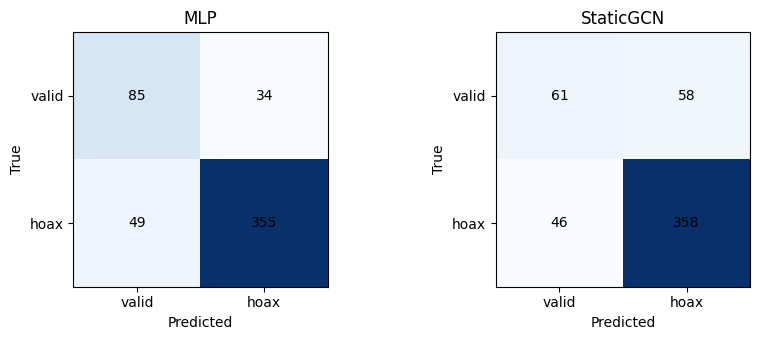

In [34]:
display_cols = ["model", "accuracy_mean", "accuracy_std", "f1_macro_mean", "f1_macro_std",
                "f1_weighted_mean", "f1_weighted_std", "roc_auc_mean", "roc_auc_std"]
print(comparison_df[display_cols].round(4).to_string(index=False))

fig, axes = plt.subplots(1, len(confmats), figsize=(4.4 * len(confmats), 3.5))
axes = np.atleast_1d(axes)
for ax, (name, cm) in zip(axes, confmats.items()):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["valid", "hoax"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["valid", "hoax"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i_ in range(2):
        for j_ in range(2):
            ax.text(j_, i_, cm[i_, j_], ha="center", va="center")
plt.tight_layout()
plt.show()

## Section 17B — Tabel Perbandingan dengan TGNN

**[TAMBAHAN — Revisi]** Menggabungkan TGNN dan dua kontrolnya ke tabel Section 17 (rata-rata dan simpangan baku antar seed). Perbedaan yang lebih kecil dari satu simpangan baku tidak ditafsirkan sebagai perbedaan nyata; CI bootstrap dan selisih berpasangan ada di Section 30.

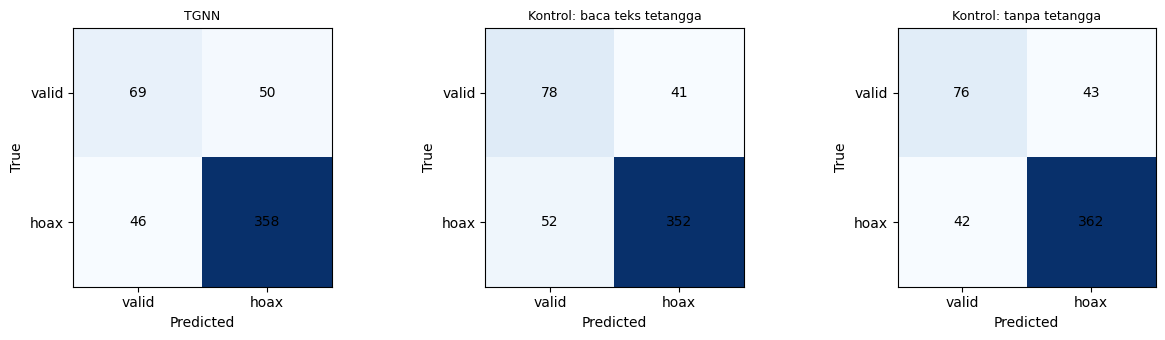

                      model  f1_macro_mean  f1_macro_std  accuracy_mean  roc_auc_mean
                        MLP         0.7653        0.0135         0.8279        0.8510
                  StaticGCN         0.6811        0.0486         0.8015        0.7967
                       TGNN         0.7117        0.0193         0.8061        0.8217
Kontrol: baca teks tetangga         0.7399        0.0432         0.8134        0.8325
    Kontrol: tanpa tetangga         0.7433        0.0257         0.8168        0.8325


In [35]:
rows = []
for name, lst in mem_metrics.items():
    d = pd.DataFrame(lst)
    rows.append(dict(model=name, f1_macro_mean=d.f1_macro.mean(), f1_macro_std=d.f1_macro.std(),
                     accuracy_mean=d.accuracy.mean(), roc_auc_mean=d.roc_auc.mean()))
mem_compare_df = pd.concat([comparison_df[["model","f1_macro_mean","f1_macro_std","accuracy_mean","roc_auc_mean"]], pd.DataFrame(rows)], ignore_index=True)
mem_compare_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "comparison_with_tgnn_mem.csv"), index=False)
mem_compare_df.round(4)

fig, axes = plt.subplots(1, len(MEM_VARIANTS), figsize=(4.2 * len(MEM_VARIANTS), 3.5))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, MEM_VARIANTS):
    t_, p_ = mem_preds[name][CFG.SEEDS_MULTIRUN[0]]
    cm = confusion_matrix(t_, p_)
    ax.imshow(cm, cmap="Blues"); ax.set_title(name, fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["valid", "hoax"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["valid", "hoax"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i_ in range(2):
        for j_ in range(2):
            ax.text(j_, i_, cm[i_, j_], ha="center", va="center")
plt.tight_layout(); plt.show()

print(mem_compare_df.round(4).to_string(index=False))


## Section 18 — Laporan Klasifikasi per Kelas

**[REVISI — Sesuai Catatan Dosen]** Precision, Recall, dan F1 per kelas (`valid` dan `hoax`) sekarang dihitung untuk **setiap seed** pada `CFG.SEEDS_MULTIRUN`, lalu dirangkum sebagai **mean ± std**. Hasilnya disimpan ke `per_class_results_5seeds.csv` agar siap dilampirkan ke dokumen skripsi.

In [36]:
from sklearn.metrics import classification_report

def per_class_metrics_one_seed(true, pred):
    prec, rec, f1, _ = precision_recall_fscore_support(
        true, pred, labels=[0, 1], zero_division=0
    )
    return {
        "valid_precision": prec[0], "valid_recall": rec[0], "valid_f1": f1[0],
        "hoax_precision": prec[1], "hoax_recall": rec[1], "hoax_f1": f1[1],
    }

per_class_summary_rows = []
for model_name in ["MLP", "StaticGCN", "TGNN"]:
    seed_records = []
    for seed in CFG.SEEDS_MULTIRUN:
        true, pred = all_predictions[model_name][seed]
        seed_records.append(per_class_metrics_one_seed(true, pred))
    
    df_model_seeds = pd.DataFrame(seed_records)
    row = {"model": model_name}
    for metric_col in ["valid_precision", "valid_recall", "valid_f1", 
                       "hoax_precision", "hoax_recall", "hoax_f1"]:
        row[f"{metric_col}_mean"] = df_model_seeds[metric_col].mean()
        row[f"{metric_col}_std"] = df_model_seeds[metric_col].std()
        row[f"{metric_col}_str"] = f"{df_model_seeds[metric_col].mean():.4f} ± {df_model_seeds[metric_col].std():.4f}"
    per_class_summary_rows.append(row)

per_class_df = pd.DataFrame(per_class_summary_rows)
per_class_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "per_class_results_5seeds.csv"), index=False)

print("=== Precision / Recall / F1 per kelas, mean +/- std dari 5 seeds ===\n")
cols_to_print = ["model", "valid_precision_str", "valid_recall_str", "valid_f1_str",
                 "hoax_precision_str", "hoax_recall_str", "hoax_f1_str"]
print(per_class_df[cols_to_print].to_string(index=False))

# Confusion matrix & classification report untuk SATU seed representatif (seed=42)
seed0 = CFG.SEEDS_MULTIRUN[0]
print(f"\n--- Ilustrasi kualitatif pada seed={seed0} (bukan angka final) ---")
for name in ["MLP", "StaticGCN", "TGNN"]:
    print(f"=== {name} (seed={seed0}) ===")
    true, pred = all_predictions[name][seed0]
    print(confusion_matrix(true, pred))
    print(classification_report(true, pred, target_names=["valid", "hoax"], zero_division=0))
    print()

=== Precision / Recall / F1 per kelas, mean +/- std dari 5 seeds ===

    model valid_precision_str valid_recall_str    valid_f1_str hoax_precision_str hoax_recall_str     hoax_f1_str
      MLP     0.6091 ± 0.0252  0.6840 ± 0.0249 0.6441 ± 0.0197    0.9034 ± 0.0068 0.8703 ± 0.0138 0.8865 ± 0.0081
StaticGCN     0.5870 ± 0.0216  0.4269 ± 0.1269 0.4857 ± 0.0940    0.8449 ± 0.0252 0.9119 ± 0.0249 0.8766 ± 0.0050
     TGNN     0.5831 ± 0.0158  0.5160 ± 0.0523 0.5467 ± 0.0348    0.8623 ± 0.0122 0.8916 ± 0.0073 0.8766 ± 0.0044

--- Ilustrasi kualitatif pada seed=42 (bukan angka final) ---
=== MLP (seed=42) ===
[[ 85  34]
 [ 49 355]]
              precision    recall  f1-score   support

       valid       0.63      0.71      0.67       119
        hoax       0.91      0.88      0.90       404

    accuracy                           0.84       523
   macro avg       0.77      0.80      0.78       523
weighted avg       0.85      0.84      0.84       523


=== StaticGCN (seed=42) ===
[[ 61  58]

In [37]:
# === PERBAIKAN: Menampilkan detail untuk SEMUA 5 SEEDS ===
print("\n--- Analisis Kualitatif untuk Tiap-Tiap Seed (Total 5 Seeds) ---")
for seed in CFG.SEEDS_MULTIRUN:
    print(f"\n==========================================================")
    print(f"===================== RUNNING SEED: {seed} =====================")
    print(f"==========================================================")
    
    for name in ["MLP", "StaticGCN", "TGNN"]:
        print(f"=== Model: {name} | Seed: {seed} ===")
        true, pred = all_predictions[name][seed]
        
        # Cetak matriks performa riil per run
        print("Confusion Matrix:")
        print(confusion_matrix(true, pred))
        print("\nClassification Report:")
        print(classification_report(true, pred, target_names=["valid", "hoax"], zero_division=0))
        print("-" * 50)


--- Analisis Kualitatif untuk Tiap-Tiap Seed (Total 5 Seeds) ---

===================== RUNNING SEED: 42 =====================
=== Model: MLP | Seed: 42 ===
Confusion Matrix:
[[ 85  34]
 [ 49 355]]

Classification Report:
              precision    recall  f1-score   support

       valid       0.63      0.71      0.67       119
        hoax       0.91      0.88      0.90       404

    accuracy                           0.84       523
   macro avg       0.77      0.80      0.78       523
weighted avg       0.85      0.84      0.84       523

--------------------------------------------------
=== Model: StaticGCN | Seed: 42 ===
Confusion Matrix:
[[ 61  58]
 [ 46 358]]

Classification Report:
              precision    recall  f1-score   support

       valid       0.57      0.51      0.54       119
        hoax       0.86      0.89      0.87       404

    accuracy                           0.80       523
   macro avg       0.72      0.70      0.71       523
weighted avg       0.79   

## Section 18B — Confusion Matrix Rata-Rata Lima Seed dan Rekonsiliasi dengan Tabel

**[TAMBAHAN — Revisi v5, menjawab komentar Reviewer 2 tentang Figure 7]** Reviewer 2 menunjuk bahwa confusion matrix di naskah hanya untuk seed 42, sedangkan Tabel 3 dan 4 melaporkan rata-rata lima seed, sehingga pembaca tidak bisa menghubungkan keduanya. Section 18 sudah mencetak matriks dan laporan klasifikasi per seed; section ini menjumlahkannya menjadi satu gambar untuk kelima seed dan menunjukkan bahwa angka tabel dapat dihitung ulang dari matriks tersebut.

Isi section:
1. **Confusion matrix rata-rata lima seed** per model (jumlah tweet, dengan simpangan baku antar seed), beserta versi yang dinormalisasi per baris (recall tiap kelas).
2. **Tabel rekonsiliasi**: precision, recall, dan F1 kelas valid, serta macro F1 dan akurasi, dihitung dari matriks tiap seed lalu dirata-ratakan. Nilainya diperiksa terhadap `comparison_df` (Section 17); selisih harus di bawah 0,001.
3. **Rentang antar seed untuk recall kelas valid.** Variasi macro F1 antar seed pada model graf terutama berasal dari recall kelas valid (kelas minoritas), sehingga seed 42 saja tidak mewakili.

Baris matriks adalah kelas sebenarnya dan kolom adalah prediksi, dengan urutan `[valid, hoax]` (label 0 = valid, 1 = hoax). Untuk menambahkan model lain (misalnya TGNN), isi `EXTRA_CM` dengan pasangan nama dan daftar prediksi per seed dengan urutan seed yang sama.

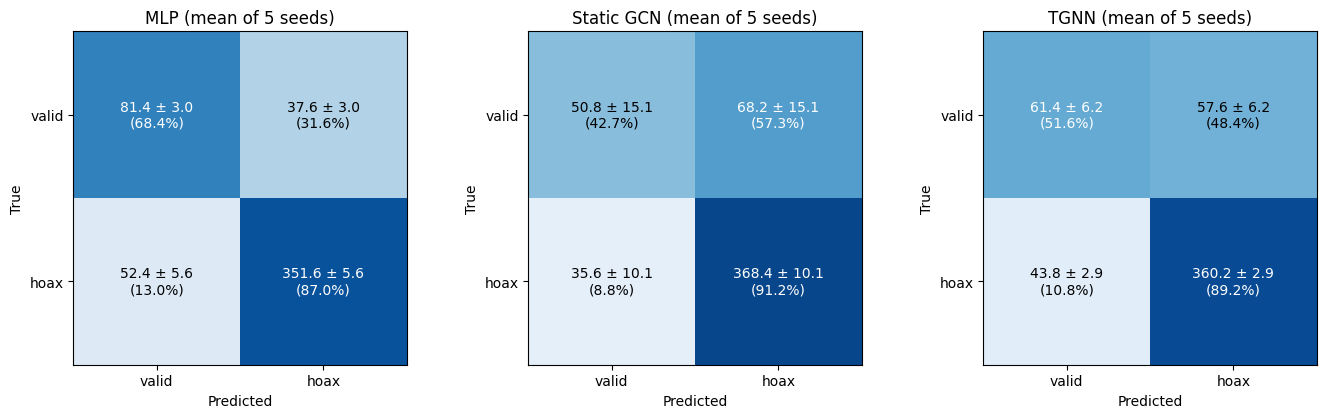

Rekonsiliasi MLP: macro F1 dari CM = 0.7653 vs tabel 0.7653 -> True; akurasi 0.8279 vs 0.8279 -> True
Rekonsiliasi StaticGCN: macro F1 dari CM = 0.6811 vs tabel 0.6811 -> True; akurasi 0.8015 vs 0.8015 -> True

=== Metrik dihitung dari confusion matrix per seed (rata-rata ± std antar seed) ===
    model valid_precision    valid_recall        valid_f1        f1_macro        accuracy valid_recall_min..max valid_recall_seed42
      MLP 0.6091 ± 0.0252 0.6840 ± 0.0249 0.6441 ± 0.0197 0.7653 ± 0.0135 0.8279 ± 0.0114            0.65..0.71                0.71
StaticGCN 0.5870 ± 0.0216 0.4269 ± 0.1269 0.4857 ± 0.0940 0.6811 ± 0.0486 0.8015 ± 0.0120            0.26..0.53                0.51
     TGNN 0.5831 ± 0.0158 0.5160 ± 0.0523 0.5467 ± 0.0348 0.7117 ± 0.0193 0.8061 ± 0.0084            0.46..0.58                0.58

Catatan: variasi macro F1 antar seed pada model graf terutama berasal dari recall kelas valid (lihat kolom valid_recall_min..max).


In [38]:
from sklearn.metrics import confusion_matrix

CM_SEEDS = list(CFG.SEEDS_MULTIRUN)
CM_MODELS = {"MLP": "MLP", "StaticGCN": "StaticGCN"}   # nama tampil -> kunci di all_predictions
EXTRA_CM = {"TGNN": [mem_preds["TGNN"][sd][1] for sd in CM_SEEDS]}   # dari Section 15B; urutan seed = CM_SEEDS

cm_stack = {}
for nm, key in CM_MODELS.items():
    cm_stack[nm] = np.stack([confusion_matrix(all_predictions[key][s][0], all_predictions[key][s][1], labels=[0, 1])
                             for s in CM_SEEDS])                      # bentuk (seed, 2, 2)
_true_cm = all_predictions["MLP"][CM_SEEDS[0]][0]
for nm, plist in EXTRA_CM.items():
    cm_stack[nm] = np.stack([confusion_matrix(_true_cm, p, labels=[0, 1]) for p in plist])

def _per_seed_metrics(c):
    c = c.astype(float)
    pv = c[0, 0] / max(c[:, 0].sum(), 1); rv = c[0, 0] / c[0].sum(); fv = 2 * pv * rv / max(pv + rv, 1e-12)
    ph = c[1, 1] / max(c[:, 1].sum(), 1); rh = c[1, 1] / c[1].sum(); fh = 2 * ph * rh / max(ph + rh, 1e-12)
    return dict(valid_precision=pv, valid_recall=rv, valid_f1=fv, hoax_recall=rh, f1_macro=(fv + fh) / 2,
                accuracy=(c[0, 0] + c[1, 1]) / c.sum())

# ---- 18B.1 Gambar 7 naskah: CM rata-rata lima seed (MLP, Static GCN, TGNN) ----
FIG_ORDER = [("MLP", "MLP"), ("StaticGCN", "Static GCN"), ("TGNN", "TGNN")]
fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.2))
for ax, (key, title) in zip(axes, FIG_ORDER):
    st = cm_stack[key]
    mean, sd = st.mean(0), st.std(0, ddof=1)
    rownorm = mean / mean.sum(1, keepdims=True)
    ax.imshow(rownorm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mean[i, j]:.1f} ± {sd[i, j]:.1f}\n({rownorm[i, j]*100:.1f}%)", ha="center", va="center",
                    color="white" if rownorm[i, j] > 0.5 else "black", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["valid", "hoax"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["valid", "hoax"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{title} (mean of {len(CM_SEEDS)} seeds)")
plt.tight_layout()
plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "confusion_matrix_mean_5seeds.png"), dpi=300, bbox_inches="tight")
plt.show()

# ---- 18B.2 Tabel rekonsiliasi ----
rows_ = []
for nm, st in cm_stack.items():
    ms_ = pd.DataFrame([_per_seed_metrics(c) for c in st])
    row = dict(model=nm)
    for m in ["valid_precision", "valid_recall", "valid_f1", "f1_macro", "accuracy"]:
        row[m] = f"{ms_[m].mean():.4f} ± {ms_[m].std(ddof=1):.4f}"
    row["valid_recall_min..max"] = f"{ms_['valid_recall'].min():.2f}..{ms_['valid_recall'].max():.2f}"
    row["valid_recall_seed42"] = f"{ms_['valid_recall'].iloc[0]:.2f}" if CM_SEEDS[0] == 42 else "-"
    rows_.append(row)
    if nm in comparison_df["model"].values:
        ref = comparison_df.set_index("model").loc[nm]
        ok_f1 = abs(ms_["f1_macro"].mean() - ref["f1_macro_mean"]) < 1e-3
        ok_acc = abs(ms_["accuracy"].mean() - ref["accuracy_mean"]) < 1e-3
        print(f"Rekonsiliasi {nm}: macro F1 dari CM = {ms_['f1_macro'].mean():.4f} vs tabel {ref['f1_macro_mean']:.4f} -> {ok_f1}; "
              f"akurasi {ms_['accuracy'].mean():.4f} vs {ref['accuracy_mean']:.4f} -> {ok_acc}")
cm_recon_df = pd.DataFrame(rows_)
print("\n=== Metrik dihitung dari confusion matrix per seed (rata-rata ± std antar seed) ===")
print(cm_recon_df.to_string(index=False))
cm_recon_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "confusion_reconciliation_5seeds.csv"), index=False)
pd.DataFrame({nm: st.mean(0).ravel() for nm, st in cm_stack.items()},
             index=["valid->valid", "valid->hoax", "hoax->valid", "hoax->hoax"]).round(2).to_csv(
    os.path.join(CFG.ARTIFACT_DIR, "confusion_matrix_mean_5seeds.csv"))
print("\nCatatan: variasi macro F1 antar seed pada model graf terutama berasal dari recall kelas valid (lihat kolom valid_recall_min..max).")

## Section 19 — Visualisasi Kurva Pelatihan

Section ini memplot macro F1 validasi per epoch untuk setiap seed pada ketiga model. Kurva dipakai untuk melihat kapan early stopping berhenti dan seberapa stabil pelatihan antar seed. Analisis lebih rinci (epoch terbaik per seed, kurva train loss, dan pemeriksaan lr/patience) ada di Section 21.

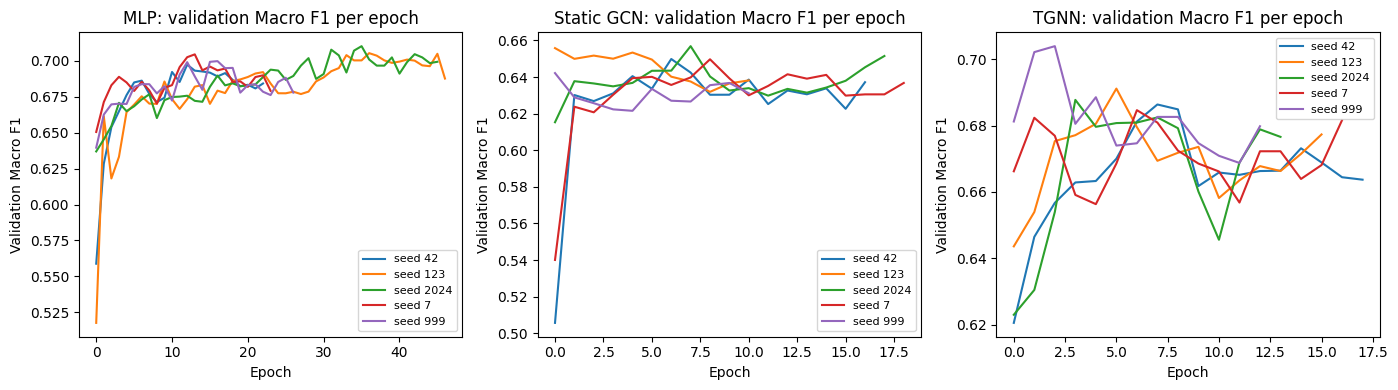

In [39]:
# Gambar 6 naskah: kurva Val Macro F1 per epoch (MLP, Static GCN, TGNN)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [("MLP", {s: r["history"] for s, r in mlp_results.items()}),
          ("Static GCN", {s: r["history"] for s, r in gcn_results.items()}),
          ("TGNN", {s: mem_models[("TGNN", s)][1] for s in CFG.SEEDS_MULTIRUN})]
for ax, (name, hists) in zip(axes, panels):
    for seed, h in hists.items():
        ax.plot(h["epoch"], h["val_f1_macro"], label=f"seed {seed}")
    ax.set_title(f"{name}: validation Macro F1 per epoch")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation Macro F1")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "val_f1_curves.png"), dpi=300, bbox_inches="tight")
plt.show()

## Section 20 — Uji Sanity: Struktur Graf Kausal dan Pemakaian Memori TGNN

**[TAMBAHAN — Revisi]** Section ini berisi dua pemeriksaan:
1. **Bukti struktural (20.1).** Baris adjacency node baru di setiap snapshot harus identik dengan baris yang sama pada graf penuh (`adj_all`, dipakai Static GCN). Ini mengikuti aturan kausal: seluruh tetangga masuk sebuah node lebih tua darinya, sehingga tidak ada informasi masa depan.
2. **Pemakaian memori TGNN (20.5).** State node lama diganti derau besar sebelum snapshot uji. Jika memori dipakai, logit dan prediksi node uji harus berubah.

Catatan: pada GPU, `torch.sparse.mm` dapat bersifat nondeterministik sehingga selisih sangat kecil (~1e-6) wajar.


In [40]:
# ---- 20.0 Helper struktur graf (dipakai juga oleh Section 22-23) ----
in_neighbors = [[] for _ in range(n_nodes)]
for _s, _d in zip(edge_index_full_tgnn[0], edge_index_full_tgnn[1]):
    in_neighbors[int(_d)].append(int(_s))
in_deg_all = np.array([len(v) for v in in_neighbors])
print(f"in_neighbors dibangun untuk {n_nodes} node; rata-rata in-degree = {in_deg_all.mean():.3f}")

# ---- 20.1 Bukti struktural: baris adjacency node baru identik antar snapshot ----
dense_last = snapshot_adjs[-1].to_dense()
dense_gcn = adj_all.to_dense()
print("adj snapshot terakhir == adj_all (Static GCN):", bool(torch.allclose(dense_last, dense_gcn, atol=1e-7)))

struct_rows = []
for s_i, bin_ in enumerate(snapshot_bins):
    nodes_upto = cumulative_nodes_per_snapshot[s_i]
    assert np.array_equal(nodes_upto, np.arange(len(nodes_upto))), "indeks lokal != global, cek ulang cumulative nodes"
    new_ids = torch.tensor(bin_, dtype=torch.long, device=dense_last.device)
    A_s = snapshot_adjs[s_i].to_dense()[new_ids]
    A_last = dense_last[new_ids]
    same = bool(torch.allclose(A_s, A_last[:, :len(nodes_upto)], atol=1e-7))
    zero_rest = bool((A_last[:, len(nodes_upto):] == 0).all())
    struct_rows.append(dict(snapshot=s_i, split=snapshot_split_label[s_i], n_new=len(bin_),
                            baris_identik_dgn_graf_penuh=same, tidak_ada_edge_ke_masa_depan=zero_rest))
    del A_s, A_last
struct_check_df = pd.DataFrame(struct_rows)
print(struct_check_df.to_string(index=False))
adjacency_rows_identical = bool(struct_check_df[["baris_identik_dgn_graf_penuh", "tidak_ada_edge_ke_masa_depan"]].all().all())
print("\nSemua snapshot lolos bukti struktural:", adjacency_rows_identical)
del dense_last, dense_gcn

in_neighbors dibangun untuk 3479 node; rata-rata in-degree = 3.769
adj snapshot terakhir == adj_all (Static GCN): True
 snapshot split  n_new  baris_identik_dgn_graf_penuh  tidak_ada_edge_ke_masa_depan
        0 train    305                          True                          True
        1 train    305                          True                          True
        2 train    305                          True                          True
        3 train    304                          True                          True
        4 train    304                          True                          True
        5 train    304                          True                          True
        6 train    304                          True                          True
        7 train    304                          True                          True
        8   val    261                          True                          True
        9   val    260                          Tru

### 20.5 Uji sanity TGNN: apakah memori kini benar-benar dipakai?

**[TAMBAHAN — Revisi]** Pada TGNN, state node lama (train dan val) diganti derau besar sebelum snapshot uji. Jika memori dipakai, logit dan prediksi node uji harus berubah. Hasil ini menjadi bukti bahwa komponen temporal pada TGNN aktif, terlepas dari apakah skor F1-nya naik.

In [41]:
# 20.5 Uji kewajaran: apakah memori benar-benar dipakai? (analog Section 20)
rows = []
for seed in CFG.SEEDS_MULTIRUN:
    mdl, _ = mem_models[("TGNN", seed)]
    mdl.eval()
    def test_logits(noise):
        with torch.no_grad():
            M, written = _fresh_mem()
            _, _, _, M, written = run_mem(mdl, train_snap_ids, M, written)
            _, _, _, M, written = run_mem(mdl, val_snap_ids, M, written)
            if noise:
                g = torch.Generator(device="cpu").manual_seed(seed + 1)
                M = torch.where(written.unsqueeze(1), (torch.randn(M.shape, generator=g) * 3.0).to(device), M)
            tl, _, tg, _, _ = run_mem(mdl, test_snap_ids, M, written)
        pos = {g_: i for i, g_ in enumerate(tg)}
        return tl[[pos[g_] for g_ in idx_test]].cpu().numpy()
    a, b = test_logits(False), test_logits(True)
    rows.append(dict(seed=seed, max_abs_dlogit_noise=float(np.abs(a - b).max()),
                     pred_sama=float((a.argmax(1) == b.argmax(1)).mean())))
mem_sanity_df = pd.DataFrame(rows)
print("=== TGNN: state node lama diganti derau -> output uji harus BERUBAH bila memori dipakai ===")
print(mem_sanity_df.to_string(index=False))


=== TGNN: state node lama diganti derau -> output uji harus BERUBAH bila memori dipakai ===
 seed  max_abs_dlogit_noise  pred_sama
   42              1.525801   0.952199
  123              0.630531   0.956023
 2024              0.822549   0.896750
    7              0.981048   0.929254
  999              0.696401   0.875717


## Section 21 — Epoch Terbaik, Kurva Train Loss, dan Pemeriksaan lr / Patience

**[TAMBAHAN — Revisi Langkah 2]** Pada Section 13–15B semua model berhenti sangat dini (dengan `PATIENCE = 10`; lihat jumlah epoch di Section 13–15B). Karena pelatihan bersifat full-batch (satu langkah gradien per epoch), "epoch" di sini sama dengan jumlah langkah optimasi, sehingga model hanya diberi puluhan langkah. Section ini memutuskan apakah penghentian dini itu wajar atau tanda pelatihan bermasalah.

Dua kemungkinan yang dibedakan:
- **Wajar (pergeseran distribusi / overfit ke periode lama).** Macro F1 validasi mencapai puncak lalu turun atau mendatar sementara train loss terus turun. Validasi berasal dari 2020–2021 sedangkan pelatihan mencakup 2010–2020, sehingga model yang makin cocok ke periode lama tidak membaik pada periode baru.
- **Bermasalah (belum terlatih).** Puncak validasi terjadi ketika train loss baru turun sedikit dari nilai awal, atau kurva validasi masih naik ketika patience habis.

Setelah indikator dihitung dari `history` yang sudah ada, dilakukan pemeriksaan dengan `lr` lebih kecil dan/atau `patience` lebih besar. Pemeriksaan ini memakai `cfg_override` agar `CFG` global dan checkpoint asli tidak tertimpa. Nilai macro F1 uji hanya dicatat sebagai informasi, keputusan diambil dari validasi.

    model  seed  epochs_dijalankan  best_epoch  train_loss_awal  train_loss_best  train_loss_akhir  penurunan_loss_di_best_pct  loss_masih_turun_setelah_best  val_f1_best  val_f1_akhir
      MLP    42                 23          12           0.6983           0.5458            0.4477                     21.8386                           True       0.6974        0.6843
      MLP   123                 47          36           0.7002           0.3647            0.2668                     47.9185                           True       0.7055        0.6877
      MLP  2024                 46          35           0.6957           0.3346            0.2431                     51.9069                           True       0.7103        0.6994
      MLP     7                 24          13           0.6941           0.5149            0.4328                     25.8227                           True       0.7046        0.6792
      MLP   999                 27          16           0.6924           0

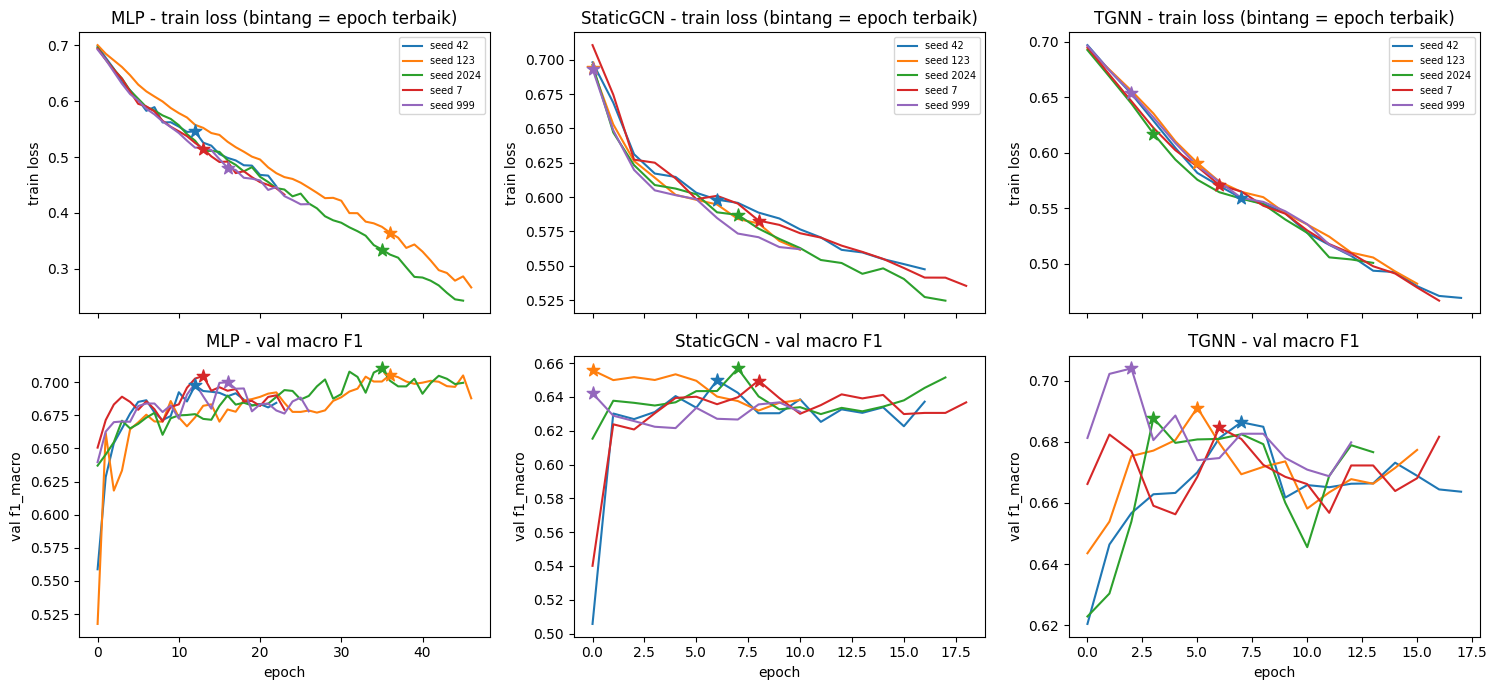

In [42]:
# ---- 21.1 Epoch terbaik dan indikator dari history yang sudah ada ----
def history_diagnostics(results_dict, name):
    rows = []
    for seed, r in results_dict.items():
        h = r["history"]
        best_ep = int(h["val_f1_macro"].values.argmax())
        l0, lb, ll = h["train_loss"].iloc[0], h["train_loss"].iloc[best_ep], h["train_loss"].iloc[-1]
        rows.append(dict(model=name, seed=seed, epochs_dijalankan=len(h), best_epoch=best_ep,
                         train_loss_awal=l0, train_loss_best=lb, train_loss_akhir=ll,
                         penurunan_loss_di_best_pct=100 * (1 - lb / l0),
                         loss_masih_turun_setelah_best=bool(ll < 0.99 * lb),
                         val_f1_best=h["val_f1_macro"].max(), val_f1_akhir=h["val_f1_macro"].iloc[-1]))
    return rows

tgnn_hist_results = {sd: dict(history=mem_models[("TGNN", sd)][1]) for sd in CFG.SEEDS_MULTIRUN}   # TGNN Section 15B
diag_rows = []
for nm, res in [("MLP", mlp_results), ("StaticGCN", gcn_results), ("TGNN", tgnn_hist_results)]:
    diag_rows += history_diagnostics(res, nm)
epoch_diag_df = pd.DataFrame(diag_rows)
print(epoch_diag_df.round(4).to_string(index=False))
epoch_diag_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "best_epoch_per_seed.csv"), index=False)

print("\n=== Ringkasan per model ===")
for nm, g in epoch_diag_df.groupby("model", sort=False):
    print(f"{nm:10s} best_epoch median={g.best_epoch.median():.0f} (min {g.best_epoch.min()}, maks {g.best_epoch.max()}) | "
          f"penurunan loss di best: median {g.penurunan_loss_di_best_pct.median():.1f}% | "
          f"loss masih turun setelah best pada {g.loss_masih_turun_setelah_best.mean()*100:.0f}% seed | "
          f"val F1 best->akhir: {g.val_f1_best.mean():.4f} -> {g.val_f1_akhir.mean():.4f}")

# ---- 21.2 Plot train loss + val F1 dengan penanda epoch terbaik ----
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex="col")
for col, (nm, res) in enumerate([("MLP", mlp_results), ("StaticGCN", gcn_results), ("TGNN", tgnn_hist_results)]):
    for seed, r in res.items():
        h = r["history"]; be = int(h["val_f1_macro"].values.argmax())
        l1, = axes[0, col].plot(h["epoch"], h["train_loss"], label=f"seed {seed}")
        axes[0, col].scatter([be], [h["train_loss"].iloc[be]], color=l1.get_color(), marker="*", s=90, zorder=3)
        l2, = axes[1, col].plot(h["epoch"], h["val_f1_macro"], color=l1.get_color())
        axes[1, col].scatter([be], [h["val_f1_macro"].iloc[be]], color=l1.get_color(), marker="*", s=90, zorder=3)
    axes[0, col].set_title(f"{nm} - train loss (bintang = epoch terbaik)")
    axes[1, col].set_title(f"{nm} - val macro F1")
    axes[1, col].set_xlabel("epoch")
    axes[0, col].set_ylabel("train loss"); axes[1, col].set_ylabel("val f1_macro")
    axes[0, col].legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "train_loss_best_epoch.png"), dpi=150, bbox_inches="tight")
plt.show()

In [43]:
# ---- 21.3 Pemeriksaan lr lebih kecil / patience lebih besar ----
from contextlib import contextmanager

@contextmanager
def cfg_override(**kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

LR_CHECK_SEEDS = CFG.SEEDS_MULTIRUN[:3]     # kurangi/tambah sesuai waktu
RUN_LR_CHECK_TGNN = True                    # TGNN paling lambat; set False untuk melewatkan
LR_CHECK_CONFIGS = [
    dict(tag="lr_kecil",                LEARNING_RATE=3e-4, PATIENCE=10, EPOCHS=300),
    dict(tag="patience_besar",          LEARNING_RATE=1e-3, PATIENCE=30, EPOCHS=300),
    dict(tag="lr_kecil+patience_besar", LEARNING_RATE=3e-4, PATIENCE=30, EPOCHS=300),
]
trainers_chk = {"MLP": train_mlp, "StaticGCN": train_static_gcn, "TGNN": lambda sd: train_mem(sd, "memory", False)}
eval_chk = {"MLP": lambda m, s: eval_mlp_test(m), "StaticGCN": lambda m, s: eval_gcn_test(m), "TGNN": lambda m, s: eval_mem_test(m)}
base_res = {"MLP": mlp_results, "StaticGCN": gcn_results, "TGNN": {sd: dict(model=mem_models[("TGNN", sd)][0], history=mem_models[("TGNN", sd)][1]) for sd in CFG.SEEDS_MULTIRUN}}

def _chk_row(tag, nm, seed, model, hist):
    m = eval_chk[nm](model, seed)[0]
    return dict(config=tag, model=nm, seed=seed, epochs_dijalankan=len(hist),
                best_epoch=int(hist["val_f1_macro"].values.argmax()),
                val_f1_macro=float(hist["val_f1_macro"].max()),
                loss_awal=float(hist["train_loss"].iloc[0]), loss_akhir=float(hist["train_loss"].iloc[-1]),
                test_f1_macro_info=float(m["f1_macro"]))

lr_rows = []
for nm in trainers_chk:                                        # baseline = hasil asli (lr 1e-3, patience 10)
    for seed in LR_CHECK_SEEDS:
        r = base_res[nm][seed]
        lr_rows.append(_chk_row("baseline(1e-3,p10)", nm, seed, r["model"], r["history"]))

chk_dir = os.path.join(CFG.ARTIFACT_DIR, "lr_patience_check")
os.makedirs(chk_dir, exist_ok=True)
lr_check_histories = {}
for cfg_ in LR_CHECK_CONFIGS:
    kw = {k: v for k, v in cfg_.items() if k != "tag"}
    with cfg_override(ARTIFACT_DIR=chk_dir, **kw):
        for nm, fn in trainers_chk.items():
            if nm == "TGNN" and not RUN_LR_CHECK_TGNN:
                continue
            for seed in LR_CHECK_SEEDS:
                model_, hist_ = fn(seed)
                lr_check_histories[(cfg_["tag"], nm, seed)] = hist_
                lr_rows.append(_chk_row(cfg_["tag"], nm, seed, model_, hist_))

lr_check_df = pd.DataFrame(lr_rows)
lr_check_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "lr_patience_check.csv"), index=False)
lr_check_summary_df = (lr_check_df.groupby(["model", "config"], sort=False)
                       .agg(epochs=("epochs_dijalankan", "mean"), best_epoch=("best_epoch", "mean"),
                            val_f1_mean=("val_f1_macro", "mean"), val_f1_std=("val_f1_macro", "std"),
                            test_f1_info=("test_f1_macro_info", "mean")).round(4))
print(lr_check_summary_df.to_string())

print("\n=== Keputusan (kriteria: kenaikan val F1 >= 0.01 dibanding baseline = penghentian dini bermasalah) ===")
for nm in lr_check_df["model"].unique():
    sub = lr_check_summary_df.loc[nm]
    base_v = sub.loc["baseline(1e-3,p10)", "val_f1_mean"]
    best_cfg = sub["val_f1_mean"].idxmax()
    gain = sub["val_f1_mean"].max() - base_v
    verdict = ("TANDA PELATIHAN BELUM OPTIMAL: konfigurasi lain menaikkan val F1" if gain >= 0.01
               else "PENGHENTIAN DINI WAJAR: val F1 tidak membaik berarti dengan lr/patience lain")
    print(f"{nm:10s} konfigurasi val terbaik = {best_cfg:26s} gain val F1 = {gain:+.4f} -> {verdict}")

[MLP seed=42] early stop di epoch 25, best val f1_macro=0.6828
[MLP seed=123] early stop di epoch 58, best val f1_macro=0.7006
[MLP seed=2024] early stop di epoch 28, best val f1_macro=0.6785
[GCN seed=42] early stop di epoch 21, best val f1_macro=0.6418
[GCN seed=123] early stop di epoch 20, best val f1_macro=0.6534
[GCN seed=2024] early stop di epoch 28, best val f1_macro=0.6643
[MLP seed=42] early stop di epoch 92, best val f1_macro=0.7060
[MLP seed=123] early stop di epoch 66, best val f1_macro=0.7055
[MLP seed=2024] early stop di epoch 65, best val f1_macro=0.7103
[GCN seed=42] early stop di epoch 56, best val f1_macro=0.6508
[GCN seed=123] early stop di epoch 30, best val f1_macro=0.6558
[GCN seed=2024] early stop di epoch 37, best val f1_macro=0.6569
[MLP seed=42] early stop di epoch 59, best val f1_macro=0.6963
[MLP seed=123] early stop di epoch 78, best val f1_macro=0.7006
[MLP seed=2024] early stop di epoch 101, best val f1_macro=0.7068
[GCN seed=42] early stop di epoch 71, b

## Section 22 — Struktur Graf Dihitung Ulang dari Notebook

**[TAMBAHAN — Revisi Langkah 3]** Section ini menghitung langsung dari notebook, bukan dari ringkasan CSV, struktur graf yang dipakai Static GCN dan TGNN. Sebagian angka sudah ada di `tgnn_homophily_summary.csv` (Section 10), dan di akhir section dilakukan pemeriksaan konsistensi terhadap file tersebut.

Isi section ini:
1. Proporsi kelas per snapshot dan per split.
2. Distribusi in-degree dan out-degree, serta node terisolasi (in-degree 0) per split dan per kelas.
3. Komposisi tetangga masuk per kelas untuk node uji dibandingkan dengan base rate. Base rate dihitung dua cara: proporsi kelas pada data latih, dan proporsi kelas pada kumpulan node yang lebih tua dari node tersebut (kumpulan kandidat tetangga, karena graf kausal). Rasio terhadap base rate (lift) memperlihatkan seberapa jauh tetangga lebih informatif daripada pilihan acak.
4. Homophily yang dikoreksi untuk ketidakseimbangan kelas: *adjusted homophily* dan *class-insensitive homophily*. Edge homophily mentah (0.7638 pada Section 10) harus dibaca terhadap baseline acak 0.6851, dan pada kelas minoritas (valid) homophily-nya rendah (~0.22).
5. Diagnostik oracle "mayoritas label tetangga". Ini bukan model: ia memakai label asli tetangga (termasuk label uji) hanya untuk melihat batas atas informasi label yang tersedia di struktur graf.

=== Proporsi kelas per snapshot ===
 snapshot split  n_baru  hoax  valid  valid_ratio_baru  valid_ratio_kumulatif
        0 train     305   288     17             0.056                  0.056
        1 train     305   264     41             0.134                  0.095
        2 train     305   262     43             0.141                  0.110
        3 train     304   253     51             0.168                  0.125
        4 train     304   235     69             0.227                  0.145
        5 train     304   237     67             0.220                  0.158
        6 train     304   235     69             0.227                  0.168
        7 train     304   235     69             0.227                  0.175
        8   val     261   182     79             0.303                  0.187
        9   val     260   203     57             0.219                  0.190
       10  test     262   201     61             0.233                  0.194
       11  test     261   20

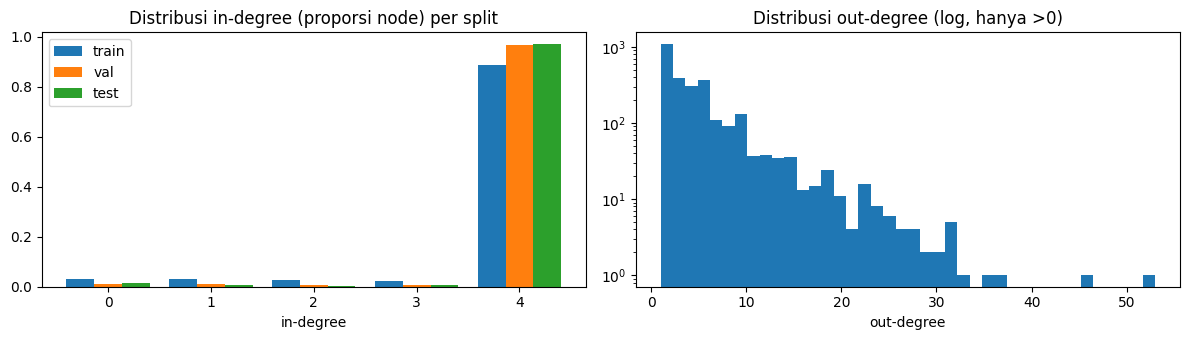

In [44]:
labels = labels_all_np
split_arr_all = df_split.sort_values("node_id")["split"].values
SPLIT_ORDER = ["train", "val", "test"]

# ---- 22.1 Proporsi kelas per snapshot dan per split ----
rows = []
for i, (b, s) in enumerate(zip(snapshot_bins, snapshot_split_label)):
    lab = labels[b]
    rows.append(dict(snapshot=i, split=s, n_baru=len(b), hoax=int((lab == 1).sum()), valid=int((lab == 0).sum()),
                     valid_ratio_baru=round(float((lab == 0).mean()), 3),
                     valid_ratio_kumulatif=round(float((labels[cumulative_nodes_per_snapshot[i]] == 0).mean()), 3)))
snap_class_df = pd.DataFrame(rows)
print("=== Proporsi kelas per snapshot ===")
print(snap_class_df.to_string(index=False))

split_class_df = (df_split.assign(hoax=(df_split["label"] == 1), valid=(df_split["label"] == 0))
                  .groupby("split")[["hoax", "valid"]].sum().reindex(SPLIT_ORDER))
split_class_df["n"] = split_class_df["hoax"] + split_class_df["valid"]
split_class_df["valid_ratio"] = (split_class_df["valid"] / split_class_df["n"]).round(4)
print("\n=== Proporsi kelas per split ===")
print(split_class_df.to_string())
base_rate_train_hoax = float(labels[split_arr_all == "train"].mean())
print(f"\nBase rate hoax (train) = {base_rate_train_hoax:.4f}; valid = {1-base_rate_train_hoax:.4f}")

# ---- 22.2 Distribusi in-degree / out-degree dan node terisolasi ----
deg_in = np.bincount(edge_index_full_tgnn[1], minlength=n_nodes)
deg_out = np.bincount(edge_index_full_tgnn[0], minlength=n_nodes)
print("\n=== Distribusi in-degree per split (kolom = in-degree) ===")
indeg_tab = pd.DataFrame({s: pd.Series(deg_in[split_arr_all == s]).value_counts().sort_index() for s in SPLIT_ORDER}).fillna(0).astype(int)
print(indeg_tab.to_string())

iso_rows = []
for s in SPLIT_ORDER:
    for cname, cval in [("valid", 0), ("hoax", 1)]:
        m = (split_arr_all == s) & (labels == cval)
        iso_rows.append(dict(split=s, kelas=cname, n=int(m.sum()), terisolasi_in0=int((deg_in[m] == 0).sum()),
                             pct_terisolasi=round(100 * float((deg_in[m] == 0).mean()), 2), rata2_in_degree=round(float(deg_in[m].mean()), 3)))
iso_df = pd.DataFrame(iso_rows)
print("\n=== Node terisolasi (in-degree 0) dan rata-rata in-degree per split & kelas ===")
print(iso_df.to_string(index=False))

print("\n=== Out-degree (seberapa sering sebuah tweet lama dijadikan tetangga) ===")
print(pd.Series(deg_out).describe(percentiles=[.5, .9, .99]).round(2).to_string())
top_hubs = np.argsort(-deg_out)[:10]
print("Share edge dari 1% node dengan out-degree tertinggi:",
      round(float(np.sort(deg_out)[::-1][:max(1, n_nodes // 100)].sum() / deg_out.sum()), 4))
print("Node dengan out-degree 0 (tidak pernah dijadikan tetangga):", int((deg_out == 0).sum()), f"({(deg_out == 0).mean()*100:.1f}%)")
print("Label 10 hub teratas (1=hoax):", labels[top_hubs].tolist(), "| out-degree:", deg_out[top_hubs].tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
w = 0.27
for k_, s in enumerate(SPLIT_ORDER):
    vc = pd.Series(deg_in[split_arr_all == s]).value_counts(normalize=True).sort_index()
    axes[0].bar(vc.index + (k_ - 1) * w, vc.values, width=w, label=s)
axes[0].set_title("Distribusi in-degree (proporsi node) per split"); axes[0].set_xlabel("in-degree"); axes[0].legend()
axes[1].hist(deg_out[deg_out > 0], bins=40, log=True)
axes[1].set_title("Distribusi out-degree (log, hanya >0)"); axes[1].set_xlabel("out-degree")
plt.tight_layout(); plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "graph_degree_distribution.png"), dpi=150, bbox_inches="tight"); plt.show()

In [45]:
# ---- 22.3 Komposisi tetangga masuk per kelas dibanding base rate ----
def neighbor_composition(target_ids):
    recs = []
    for i in target_ids:
        nb = in_neighbors[i]
        pool = float(labels[:i].mean()) if i > 0 else np.nan
        if len(nb) == 0:
            recs.append(dict(node=int(i), y=int(labels[i]), n_nb=0, n_hoax_nb=0, pool_hoax=pool)); continue
        recs.append(dict(node=int(i), y=int(labels[i]), n_nb=len(nb), n_hoax_nb=int(labels[nb].sum()), pool_hoax=pool))
    return pd.DataFrame(recs)

comp_rows = []
for s in SPLIT_ORDER:
    ids = np.where(split_arr_all == s)[0]
    cdf = neighbor_composition(ids)
    cdf = cdf[cdf["n_nb"] > 0]
    for cname, cval in [("valid", 0), ("hoax", 1)]:
        g = cdf[cdf["y"] == cval]
        if len(g) == 0: continue
        obs_hoax = g["n_hoax_nb"].sum() / g["n_nb"].sum()                  # pooled per edge
        exp_pool = float(np.average(g["pool_hoax"], weights=g["n_nb"]))    # base rate: kumpulan kandidat (node lebih tua)
        comp_rows.append(dict(split_target=s, kelas_target=cname, n_node_punya_tetangga=len(g),
                              tetangga_hoax_obs=round(float(obs_hoax), 4),
                              base_rate_pool_lebih_tua=round(exp_pool, 4),
                              base_rate_train=round(base_rate_train_hoax, 4),
                              lift_hoax_vs_pool=round(float(obs_hoax / exp_pool), 3),
                              lift_valid_vs_pool=round(float((1 - obs_hoax) / (1 - exp_pool)), 3)))
neighbor_comp_df = pd.DataFrame(comp_rows)
print("=== Komposisi tetangga masuk menurut kelas node target (lift > 1: lebih banyak dari acak) ===")
print(neighbor_comp_df.to_string(index=False))
for s in SPLIT_ORDER:
    t = neighbor_comp_df[neighbor_comp_df.split_target == s].set_index("kelas_target")
    if {"valid", "hoax"} <= set(t.index):
        gap = t.loc["hoax", "tetangga_hoax_obs"] - t.loc["valid", "tetangga_hoax_obs"]
        print(f"[{s}] selisih P(tetangga hoax | target hoax) - P(tetangga hoax | target valid) = {gap:+.4f} "
              "(0 = tetangga tidak membedakan kelas target)")

test_nb_src = np.concatenate([in_neighbors[i] for i in idx_test if len(in_neighbors[i])])
print("\nAsal split tetangga masuk node uji:")
print(pd.Series(split_arr_all[test_nb_src]).value_counts(normalize=True).reindex(SPLIT_ORDER).round(4).to_string())

# Oracle diagnostik: prediksi = mayoritas label tetangga (bukan model; memakai label tetangga termasuk label uji)
orc_pred = np.array([(1 if labels[in_neighbors[i]].mean() >= 0.5 else 0) if len(in_neighbors[i]) else 1 for i in idx_test])
orc_true = labels[idx_test]
orc_metrics = evaluate_predictions(orc_true, orc_pred)
print("\nOracle mayoritas-label-tetangga pada node uji:", {k: round(v, 4) for k, v in orc_metrics.items()})
print("Sebagai pembanding, MLP asli macro F1 =", round(comparison_df.set_index('model').loc['MLP', 'f1_macro_mean'], 4))

=== Komposisi tetangga masuk menurut kelas node target (lift > 1: lebih banyak dari acak) ===
split_target kelas_target  n_node_punya_tetangga  tetangga_hoax_obs  base_rate_pool_lebih_tua  base_rate_train  lift_hoax_vs_pool  lift_valid_vs_pool
       train        valid                    422             0.6928                    0.8642           0.8251              0.802               2.263
       train         hoax                   1939             0.8840                    0.8762           0.8251              1.009               0.937
         val        valid                    136             0.6499                    0.8162           0.8251              0.796               1.905
         val         hoax                    380             0.8300                    0.8155           0.8251              1.018               0.921
        test        valid                    119             0.6025                    0.8064           0.8251              0.747               2.053
      

In [46]:
# ---- 22.4 Homophily yang dikoreksi untuk ketidakseimbangan kelas ----
def homophily_suite(edge_idx, lab, n_classes=2):
    if edge_idx.shape[1] == 0:
        return dict(h_edge=np.nan, h_adjusted=np.nan, h_class_insensitive=np.nan, h_random=np.nan, n_edges=0)
    s_l, d_l = lab[edge_idx[0]], lab[edge_idx[1]]
    h_edge = float(np.mean(s_l == d_l))
    deg = np.bincount(np.concatenate([edge_idx[0], edge_idx[1]]), minlength=len(lab)).astype(float)
    Dk = np.array([deg[lab == k].sum() for k in range(n_classes)])
    pk_deg = Dk / Dk.sum()
    h_adj = (h_edge - (pk_deg ** 2).sum()) / (1 - (pk_deg ** 2).sum())            # Platonov et al. (2023)
    hk = []
    for k in range(n_classes):                                                    # Lim et al. (2021)
        kk = np.sum((s_l == k) & (d_l == k)); cross = np.sum((s_l == k) ^ (d_l == k))
        hk.append((2 * kk) / (2 * kk + cross) if (2 * kk + cross) > 0 else 0.0)
    pk_node = np.array([np.mean(lab == k) for k in range(n_classes)])
    h_ci = float(np.sum(np.maximum(0, np.array(hk) - pk_node)) / (n_classes - 1))
    p_all = np.array([np.mean(lab == k) for k in range(n_classes)])
    return dict(h_edge=h_edge, h_adjusted=float(h_adj), h_class_insensitive=h_ci,
                h_random=float((p_all ** 2).sum()), n_edges=int(edge_idx.shape[1]))

E = edge_index_full_tgnn
subsets = {
    "graf penuh": E,
    "subgraf train": E[:, np.isin(E[0], idx_train) & np.isin(E[1], idx_train)],
    "edge menuju node val": E[:, np.isin(E[1], idx_val)],
    "edge menuju node uji": E[:, np.isin(E[1], idx_test)],
}
hs_rows = [dict(subset=k, **homophily_suite(v, labels)) for k, v in subsets.items()]
homophily_corrected_df = pd.DataFrame(hs_rows)
print("=== Homophily mentah vs terkoreksi ===")
print(homophily_corrected_df.round(4).to_string(index=False))
print("\nKeterangan: h_adjusted = 0 berarti sama dengan acak (dengan memperhitungkan derajat per kelas); "
      "h_class_insensitive = 0 berarti tidak lebih homofilik dari proporsi kelas. "
      "Pada dua kelas, kedua ukuran bernilai identik selama homophily tiap kelas melebihi proporsinya (itu identitas aljabar, bukan kesalahan hitung).")

# ---- 22.5 Konsistensi dengan tgnn_homophily_summary.csv (Section 10) ----
last = homophily_summary_df.iloc[-1]
ok = abs(float(last["homophily_cumul_overall"]) - homophily_corrected_df.iloc[0]["h_edge"]) < 1e-3
print(f"\nKonsistensi dengan Section 10 (snapshot terakhir h_edge): {ok}")

graph_structure_summary = dict(
    adjusted_homophily_full=float(homophily_corrected_df.iloc[0]["h_adjusted"]),
    ci_homophily_full=float(homophily_corrected_df.iloc[0]["h_class_insensitive"]),
    adjusted_homophily_to_test=float(homophily_corrected_df.iloc[3]["h_adjusted"]),
    oracle_f1_macro=float(orc_metrics["f1_macro"]),
    isolated_test_pct=float(100 * (deg_in[idx_test] == 0).mean()),
    avg_in_degree=float(deg_in.mean()),
)
pd.DataFrame([graph_structure_summary]).to_csv(os.path.join(CFG.ARTIFACT_DIR, "graph_structure_summary.csv"), index=False)
neighbor_comp_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "neighbor_composition.csv"), index=False)
homophily_corrected_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "homophily_corrected.csv"), index=False)
snap_class_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "snapshot_class_proportion.csv"), index=False)
print(graph_structure_summary)

=== Homophily mentah vs terkoreksi ===
              subset  h_edge  h_adjusted  h_class_insensitive  h_random  n_edges
          graf penuh  0.7638      0.2197               0.2197    0.6851    13114
       subgraf train  0.7773      0.2040               0.2040    0.6851     9031
edge menuju node val  0.7035      0.1885               0.1885    0.6851     2037
edge menuju node uji  0.7644      0.2892               0.2892    0.6851     2046

Keterangan: h_adjusted = 0 berarti sama dengan acak (dengan memperhitungkan derajat per kelas); h_class_insensitive = 0 berarti tidak lebih homofilik dari proporsi kelas. Pada dua kelas, kedua ukuran bernilai identik selama homophily tiap kelas melebihi proporsinya (itu identitas aljabar, bukan kesalahan hitung).

Konsistensi dengan Section 10 (snapshot terakhir h_edge): True
{'adjusted_homophily_full': 0.2196797807790177, 'ci_homophily_full': 0.21967978077901734, 'adjusted_homophily_to_test': 0.2891870034727178, 'oracle_f1_macro': 0.630841256122155

## Section 23 — Telaah Sampel Edge Lintas Kelas (hoax ↔ valid)

**[TAMBAHAN — Revisi Langkah 4]** Pertanyaan konseptual yang harus dijawab: apakah kelas `valid` berisi bantahan atau klarifikasi atas topik yang sama dengan tweet hoax, sehingga edge kemiripan lintas kelas memang masuk akal secara konseptual (tweet bantahan dan tweet hoax membahas hal yang sama, namun labelnya berbeda)? Atau edge lintas kelas hanyalah kemiripan gaya bahasa/topik umum tanpa hubungan bantah-membantah?

Edge selalu mengarah dari tweet lama (`source`) ke tweet baru (`target`). Dua arah lintas kelas disampel seimbang:
- **Arah A**: lama = hoax → baru = valid (tweet valid yang muncul belakangan, mungkin membantah hoax lama).
- **Arah B**: lama = valid → baru = hoax (hoax yang muncul belakangan menyerupai tweet valid yang lebih lama).

Sel pertama mencetak sampel (default 50 pasangan) dan menyimpannya ke `cross_class_edge_sample.csv` dengan kolom anotasi kosong. **Penilaian akhir harus manual**: baca tiap pasangan lalu isi `topik_sama` (ya/tidak), `valid_berisi_bantahan` (ya/tidak/tidak_jelas), dan `catatan`. Kolom heuristik (irisan kata, penanda leksikal bantahan) hanya alat bantu menyortir. Sel kedua membaca kembali file yang sudah diisi dan menghitung proporsinya. Sebagai pembanding, dicetak juga beberapa edge valid→valid dan statistik penanda leksikal bantahan per kelas pada seluruh data.

In [47]:
N_EDGE_SAMPLE = 50
EDGE_SAMPLE_SPLITS = ("train", "val", "test")     # ubah ke ("test",) bila ingin hanya edge menuju node uji
REBUTTAL_CUES = ["hoax", "hoaks", "bohong", "tidak benar", "tdk benar", "bukan", "fakta", "faktanya", "klarifikasi",
                 "bantah", "menepis", "keliru", "salah", "disinformasi", "cek fakta", "sebenarnya", "nyatanya", "mitos"]

texts_all = df_split.sort_values("node_id")["tweet"].values
times_all = df_split.sort_values("node_id")["waktu_posting"].values
src_e, dst_e = edge_index_full_tgnn
split_dst = split_arr_all[dst_e]
keep_split = np.isin(split_dst, EDGE_SAMPLE_SPLITS)
dirA = np.where((labels[src_e] == 1) & (labels[dst_e] == 0) & keep_split)[0]
dirB = np.where((labels[src_e] == 0) & (labels[dst_e] == 1) & keep_split)[0]
print(f"Edge lintas kelas tersedia: arah A (hoax->valid) = {len(dirA)}, arah B (valid->hoax) = {len(dirB)}")

rng_e = np.random.default_rng(CFG.SEED)
pick = [("A: lama=hoax -> baru=valid", rng_e.choice(dirA, size=min(N_EDGE_SAMPLE // 2, len(dirA)), replace=False)),
        ("B: lama=valid -> baru=hoax", rng_e.choice(dirB, size=min(N_EDGE_SAMPLE - N_EDGE_SAMPLE // 2, len(dirB)), replace=False))]

def _cue_flag(t):
    return int(any(c in t for c in REBUTTAL_CUES))

def _jacc(a, b):
    sa, sb = set(a.split()), set(b.split())
    return len(sa & sb) / max(1, len(sa | sb))

sample_rows = []
for dname, ids in pick:
    for e in ids:
        s_, d_ = int(src_e[e]), int(dst_e[e])
        sample_rows.append(dict(arah=dname, node_lama=s_, node_baru=d_, split_target=split_dst[e],
                                sim=float(sim_matrix_full[s_, d_]),
                                selisih_hari=float((times_all[d_] - times_all[s_]) / np.timedelta64(1, "D")),
                                jaccard_kata=round(_jacc(texts_all[s_], texts_all[d_]), 3),
                                cue_bantahan_lama=_cue_flag(texts_all[s_]), cue_bantahan_baru=_cue_flag(texts_all[d_]),
                                teks_lama=texts_all[s_], teks_baru=texts_all[d_],
                                topik_sama="", valid_berisi_bantahan="", catatan=""))
cross_sample_df = pd.DataFrame(sample_rows)
cross_sample_path = os.path.join(CFG.ARTIFACT_DIR, "cross_class_edge_sample.csv")
cross_sample_df.to_csv(cross_sample_path, index=False)
print(f"Tersimpan: {cross_sample_path}  ({len(cross_sample_df)} pasangan). Isi kolom anotasi secara manual.\n")

for k_, r in cross_sample_df.iterrows():
    print(f"[{k_:02d}] {r['arah']} | sim={r['sim']:.3f} | +{r['selisih_hari']:.0f} hari | jaccard={r['jaccard_kata']} | {r['split_target']}")
    print(f"     LAMA : {r['teks_lama'][:140]}")
    print(f"     BARU : {r['teks_baru'][:140]}")

print("\n--- Pembanding: 10 edge valid -> valid ---")
vv = np.where((labels[src_e] == 0) & (labels[dst_e] == 0) & keep_split)[0]
for e in rng_e.choice(vv, size=min(10, len(vv)), replace=False):
    s_, d_ = int(src_e[e]), int(dst_e[e])
    print(f"sim={sim_matrix_full[s_, d_]:.3f} | LAMA: {texts_all[s_][:100]} || BARU: {texts_all[d_][:100]}")

print("\n--- Penanda leksikal bantahan pada seluruh data (konteks, bukan bukti) ---")
cue_all = np.array([_cue_flag(t) for t in texts_all])
print(f"P(ada penanda | valid) = {cue_all[labels == 0].mean():.3f} | P(ada penanda | hoax) = {cue_all[labels == 1].mean():.3f}")
if len(cross_sample_df):
    print("Pada sampel lintas kelas: penanda di tweet 'valid' =",
          round(float(np.where(cross_sample_df['arah'].str.startswith('A'), cross_sample_df['cue_bantahan_baru'], cross_sample_df['cue_bantahan_lama']).mean()), 3))
else:
    print("Tidak ada edge lintas kelas pada split yang dipilih.")

Edge lintas kelas tersedia: arah A (hoax->valid) = 1791, arah B (valid->hoax) = 1306
Tersimpan: /kaggle/working/artifacts/cross_class_edge_sample.csv  (50 pasangan). Isi kolom anotasi secara manual.

[00] A: lama=hoax -> baru=valid | sim=0.721 | +6 hari | jaccard=0.176 | val
     LAMA : sore semut2 kecil kasak kusuk arrow pointing rightwards then curving downwards sertifikasi halal dipegang pt surveyor indonesia bukan lagi m
     BARU : sertifikasi halal dipegang pt surveyor indonesia bukan lagi mui false context berdasarkan hasil pemantauan tim jabar saber hoaks beredar seb
[01] A: lama=hoax -> baru=valid | sim=0.731 | +1853 hari | jaccard=0.114 | train
     LAMA : 2 ubi jalar ubi juga merupakan salah satu makanan yang kaya akan vitamin a yang bagus untuk kesehatan mata
     BARU : bisa dibilang sirsak adalah salah satu buah favorit masyarakat berdaging buah berserat dengan rasa sedikit asam tapi segar ternyata buah yan
[02] A: lama=hoax -> baru=valid | sim=0.734 | +859 hari | jaccard

In [48]:
# ---- Telaah manual edge lintas kelas (Section 23) ----
# PENTING: isi kolom anotasi di bawah adalah DRAF yang ditulis asisten (Claude) dengan membaca 50 pasangan tweet.
# Penulis WAJIB memeriksa ulang (idealnya dua penulis, bandingkan, lalu catat kesepakatannya) sebelum angka dipakai di naskah.
# Untuk mengganti penilaian: ubah nilai pada ANN_DRAF (ya / tidak / tidak_jelas) lalu jalankan ulang sel ini.
ANN_DRAF = {
    (2526, 2548): ('ya', 'ya', "Dua-duanya klarifikasi soal sertifikasi halal; tweet lama (berlabel hoax) sendiri berisi koreksi ('salah ... hanya auditor')"),
    (445, 1518): ('tidak', 'tidak', 'Tema sama (khasiat makanan), klaim berbeda'),
    (547, 976): ('tidak', 'tidak', 'Tema sama (khasiat/kanker), bahan berbeda'),
    (2070, 2779): ('ya', 'tidak', 'Topik Al-Maidah 51 sama; tweet valid justru membenarkan klaim, bukan membantah'),
    (6, 933): ('tidak', 'tidak', 'Tweet lama tidak terkait klaim hoax yang jelas'),
    (2742, 2779): ('ya', 'tidak', 'Topik Al-Maidah 51 sama; tweet valid membenarkan klaim'),
    (654, 2439): ('ya', 'ya', 'Tweet valid menjelaskan tinta cumi halal, membantah klaim haram'),
    (1957, 2995): ('tidak', 'ya', 'Tweet valid membantah isu lain (Eriksen/vaksin); hanya tema covid-vaksin yang mirip'),
    (644, 2690): ('ya', 'ya', 'Topik mandi malam sama; tweet valid menyebut mitos tanpa bukti'),
    (688, 695): ('tidak', 'tidak', 'Tema khasiat makanan, bahan berbeda'),
    (451, 586): ('tidak', 'ya', 'Tweet valid membantah mitos es krim; isu berbeda dari styrofoam'),
    (589, 1707): ('tidak', 'ya', 'Tweet valid mengoreksi isu nasi magic com; isu berbeda dari sosis babi'),
    (782, 1990): ('tidak', 'tidak', 'Tema khasiat, bahan berbeda'),
    (1263, 2627): ('tidak', 'tidak', 'Tema khasiat minuman, klaim berbeda'),
    (442, 588): ('tidak', 'tidak', 'Efek makanan berbeda; kemiripan hanya gaya bahasa santai'),
    (1122, 2601): ('tidak', 'tidak', 'Tema korupsi politisi sama, kasus berbeda'),
    (86, 1747): ('tidak', 'ya', 'Tema stroke sama, klaim berbeda; tweet valid menyatakan tusuk jari tidak membantu'),
    (2307, 2721): ('tidak', 'ya', 'Tema vaksin covid sama, klaim berbeda; tweet valid bergaya cek fakta'),
    (614, 1701): ('tidak', 'tidak_jelas', 'Tema bahaya kesehatan; tweet valid hanya bertanya'),
    (1881, 1915): ('tidak', 'tidak_jelas', 'Tweet valid berupa klarifikasi umum soal GERD, bukan atas klaim tertentu'),
    (2940, 3232): ('ya', 'tidak_jelas', 'Topik dana haji sama; tweet valid melaporkan pernyataan menteri yang tampak bertentangan dengan tweet lama'),
    (2259, 3352): ('tidak', 'tidak', 'Tema herbal/kesehatan, isi berbeda'),
    (2567, 2938): ('tidak', 'ya', "Tema bumbu mie instan sama, klaim berbeda; tweet valid menyebut 'hoax banget'"),
    (483, 596): ('tidak', 'tidak', 'Tema bahaya sayuran/bayi, klaim berbeda'),
    (1045, 1945): ('tidak', 'tidak_jelas', 'Tweet valid berupa pertanyaan'),
    (638, 1666): ('tidak', 'tidak', 'Tema makanan/minuman berbeda'),
    (1636, 1804): ('tidak', 'ya', 'Tweet valid (lama) berupa notifikasi disinformasi; tweet baru topik berbeda'),
    (1984, 2712): ('tidak', 'ya', 'Tweet valid (lama) membantah klaim virus corona = jamur; hanya tema covid yang sama'),
    (2473, 2642): ('ya', 'tidak_jelas', 'Topik matahari buatan China sama; arah isi tweet valid tidak jelas'),
    (2343, 2789): ('tidak', 'tidak', "Kata 'tsunami' sama, topik berbeda"),
    (309, 1561): ('tidak', 'tidak', 'Tema khasiat makanan, bahan berbeda'),
    (1996, 2018): ('tidak', 'tidak', 'Tema covid sama, isi berbeda'),
    (493, 560): ('ya', 'tidak_jelas', "Topik Bali dijual sama; tweet valid ('diisukan') tidak jelas membantah"),
    (169, 1953): ('ya', 'ya', 'Pasangan khas: tweet valid membantah mitos lesung pipi, tweet hoax mengulang mitos'),
    (2422, 2500): ('tidak', 'tidak_jelas', 'Tema vaksin sama; tweet berlabel hoax justru bergaya cek fakta'),
    (680, 957): ('tidak', 'tidak', 'Tema manfaat makanan, bahan berbeda'),
    (465, 1645): ('tidak', 'tidak', 'Tema kanker/antioksidan, klaim berbeda'),
    (2181, 2674): ('ya', 'tidak', 'Topik masker dan jerawat sama; label berbeda padahal isi serupa'),
    (1699, 3326): ('ya', 'tidak', 'Klaim biji apel/sianida sama; label berbeda padahal isi serupa'),
    (1060, 2633): ('tidak', 'ya', 'Tweet valid (lama) membantah isu sari roti; isu baru berbeda'),
    (661, 734): ('tidak', 'tidak', 'Topik berbeda'),
    (694, 1100): ('ya', 'tidak', 'Topik garam dan sakit gigi sama; tweet valid membenarkan klaim'),
    (309, 1087): ('tidak', 'tidak', 'Node lama sama dengan pasangan sebelumnya (kacang mete); topik berbeda'),
    (596, 887): ('tidak', 'tidak', 'Tema makanan bayi/anak, klaim berbeda'),
    (1419, 1651): ('tidak', 'tidak', 'Tema khasiat tanaman, tanaman berbeda'),
    (1717, 1936): ('tidak', 'tidak', 'Tema kanker/herbal, klaim berbeda'),
    (933, 1935): ('tidak', 'tidak', 'Topik berbeda'),
    (1701, 2150): ('tidak', 'tidak_jelas', 'Tema bahaya/kesehatan umum'),
    (1989, 3174): ('tidak', 'tidak', 'Tema khasiat herbal, tanaman berbeda'),
    (3071, 3138): ('ya', 'ya', "Topik syarat vaksin untuk SKCK sama; tweet valid menyebut 'keliru', tweet hoax mengulang klaim"),
}

cross_sample_df = pd.read_csv(cross_sample_path)
keys_ = list(zip(cross_sample_df["node_lama"].astype(int), cross_sample_df["node_baru"].astype(int)))
assert all(k in ANN_DRAF for k in keys_), "Sampel berubah: pasangan node tidak cocok dengan anotasi tertanam; anotasi ulang."
cross_sample_df["topik_sama"] = [ANN_DRAF[k][0] for k in keys_]
cross_sample_df["valid_berisi_bantahan"] = [ANN_DRAF[k][1] for k in keys_]
cross_sample_df["catatan"] = [ANN_DRAF[k][2] for k in keys_]
cross_sample_df.to_csv(cross_sample_path, index=False)

ann = cross_sample_df.copy()
for c in ["topik_sama", "valid_berisi_bantahan"]:
    ann[c] = ann[c].astype(str).str.strip().str.lower().replace({"nan": ""})
print("=== Hasil telaah manual (anotasi draf; verifikasi penulis diperlukan) ===")
print("Topik sama:");  print(pd.crosstab(ann["arah"], ann["topik_sama"], margins=True).to_string())
print("\nTweet valid berisi bantahan:"); print(pd.crosstab(ann["arah"], ann["valid_berisi_bantahan"], margins=True).to_string())
n_a = int((ann["topik_sama"] != "").sum())
print(f"\nProporsi topik sama = {(ann['topik_sama']=='ya').sum()}/{n_a} = {(ann['topik_sama']=='ya').mean():.2%} (dari {len(ann)} pasangan)")
print(f"Proporsi valid berisi bantahan = {(ann['valid_berisi_bantahan']=='ya').sum()}/{n_a}")
cross_edge_annotation_summary = dict(
    topik_sama_pct=float((ann["topik_sama"] == "ya").mean()),
    bantahan_pct=float((ann["valid_berisi_bantahan"] == "ya").mean()))


=== Hasil telaah manual (anotasi draf; verifikasi penulis diperlukan) ===
Topik sama:
topik_sama                  tidak  ya  All
arah                                      
A: lama=hoax -> baru=valid     19   6   25
B: lama=valid -> baru=hoax     18   7   25
All                            37  13   50

Tweet valid berisi bantahan:
valid_berisi_bantahan       tidak  tidak_jelas  ya  All
arah                                                   
A: lama=hoax -> baru=valid     12            4   9   25
B: lama=valid -> baru=hoax     16            4   5   25
All                            28            8  14   50

Proporsi topik sama = 13/50 = 26.00% (dari 50 pasangan)
Proporsi valid berisi bantahan = 14/50


## Section 24 — Rekonstruksi Riwayat Keputusan: K, Threshold, dan Snapshot

**[TAMBAHAN — Revisi Langkah 5]** Reviewer dan pembaca akan bertanya: kapan `K = 4`, threshold kemiripan, dan jumlah snapshot ditetapkan, dan berdasarkan data apa? Section ini menyusun catatan keputusan secara jujur dengan dua jenis isi yang sengaja dipisahkan:

- **Dapat diverifikasi dari notebook.** Nilai, cara penentuan, dan data yang dipakai (misalnya threshold diambil dari persentil ke-95 kemiripan antar tweet latih saja). Sel di bawah menghitung bukti pendukungnya dari data.
- **Tidak dapat diverifikasi dari notebook.** Riwayat sebenarnya (nilai awal sebelum berubah, percobaan yang pernah dijalankan, apakah data validasi/uji pernah dilihat ketika memilih nilai). Kolom ini diberi tanda `[ISI PENULIS]` dan harus diisi dari ingatan, log eksperimen, atau riwayat versi. Jangan ditulis di naskah sebelum diisi dengan jujur.

Bukti yang dihitung di sini sudah menunjukkan dua hal penting. Pertama, snapshot equal-count sangat tidak seragam dalam rentang waktu (snapshot awal mencakup beberapa tahun, sedangkan dua snapshot uji masing-masing hanya sekitar 5 sampai 8 minggu). Kedua, threshold persentil ke-95 dari seluruh pasangan tweet hampir tidak memangkas edge karena Top-K = 4 sudah memilih tetangga dengan kemiripan jauh di atas persentil tersebut, sehingga yang sebenarnya menentukan graf adalah K.

In [49]:
# ---- 24.1 Bukti yang dapat dihitung dari data ----
t_idx = df_split.set_index("node_id")["waktu_posting"]
snap_dur = []
for i, b in enumerate(snapshot_bins):
    t = t_idx.loc[b]
    snap_dur.append(dict(snapshot=i, split=snapshot_split_label[i], n_node=len(b),
                         durasi_hari=(t.max() - t.min()).days, mulai=str(t.min().date()), selesai=str(t.max().date())))
snap_dur_df = pd.DataFrame(snap_dur)
print("=== Durasi kalender tiap snapshot (equal-count => durasi sangat tidak seragam) ===")
print(snap_dur_df.to_string(index=False))

max_slots = int(sum(min(CFG.TOP_K, i) for i in range(n_nodes)))
kept = int(edge_index_full.shape[1])
print(f"\nSlot Top-{CFG.TOP_K} yang tersedia = {max_slots}; edge yang lolos threshold {CFG.SIMILARITY_THRESHOLD} = {kept} "
      f"({kept/max_slots:.1%}). Threshold hanya memangkas {1 - kept/max_slots:.1%} slot Top-K.")
print(f"Persentil-95 kemiripan semua pasangan latih = {CFG.SIMILARITY_THRESHOLD}; "
      f"median kemiripan tetangga Top-1 (semua node) = {np.median([sim_matrix_full[i, :i].max() for i in range(1, n_nodes)]):.3f}")

=== Durasi kalender tiap snapshot (equal-count => durasi sangat tidak seragam) ===
 snapshot split  n_node  durasi_hari      mulai    selesai
        0 train     305          849 2010-11-15 2013-03-13
        1 train     305          621 2013-03-15 2014-11-26
        2 train     305          562 2014-11-30 2016-06-14
        3 train     304          502 2016-06-17 2017-11-02
        4 train     304          375 2017-11-07 2018-11-17
        5 train     304          384 2018-11-18 2019-12-08
        6 train     304          169 2019-12-08 2020-05-26
        7 train     304          173 2020-05-26 2020-11-16
        8   val     261          116 2020-11-16 2021-03-12
        9   val     260           87 2021-03-14 2021-06-09
       10  test     262           38 2021-06-09 2021-07-18
       11  test     261           54 2021-07-18 2021-09-10

Slot Top-4 yang tersedia = 13906; edge yang lolos threshold 0.572 = 13114 (94.3%). Threshold hanya memangkas 5.7% slot Top-K.
Persentil-95 kemiripan 

In [50]:
# ---- 24.2 Catatan keputusan ----
V, T, P = "TERVERIFIKASI dari kode/notebook", "TERTULIS di notebook, dasar pemilihan tidak terdokumentasi", "[ISI PENULIS]"
decision_log = [
    dict(keputusan="Pembagian 70/15/15 kronologis", nilai="0.70 / 0.15 / 0.15", status=V,
         dasar_di_notebook="Section 4; alasan tertulis: sampel kelas minoritas valid di uji cukup. Rasio valid: train 0.175, val 0.261, uji 0.228.",
         data_yang_dipakai="waktu_posting (Snowflake ID); distribusi label per split",
         jawaban_penulis="Tidak ada proporsi lain yang dicoba; 70/15/15 dipakai sejak awal (ingatan penulis, 4 Nov 2026)."),
    dict(keputusan="Jumlah snapshot", nilai="8 train / 2 val / 2 uji = 12 (equal-count)", status=T,
         dasar_di_notebook="Section 8: alokasi proporsional agar batas snapshot tidak melintasi split. Tidak ada pengujian jumlah snapshot lain.",
         data_yang_dipakai="Jumlah node per split saja. Durasi kalender snapshot tidak dipertimbangkan (lihat 24.1).",
         jawaban_penulis="Tidak ada jumlah snapshot lain yang dicoba (ingatan penulis). Alasan 8/2/2: alokasi proporsional terhadap split, bukan hasil model."),
    dict(keputusan="Top-K tetangga", nilai=f"K = {CFG.TOP_K} (TOP_K = TOP_K_TGNN)", status=T,
         dasar_di_notebook="Section 3: 'disamakan menjadi 4' untuk Fair Comparison atas catatan dosen. Kata 'disamakan' menunjukkan nilai K sebelumnya berbeda.",
         data_yang_dipakai="Tidak ada tabel sensitivitas sebelum Section 26. Rata-rata in-degree 3.77 adalah akibat K=4, bukan dasar pemilihannya.",
         jawaban_penulis="K awal TGNN diingat penulis kemungkinan 8 dan pernah dicoba, tetapi tidak ada catatan hasilnya. K disamakan menjadi 4 atas catatan dosen untuk fair comparison, bukan atas dasar hasil uji."),
    dict(keputusan="Threshold kemiripan", nilai=f"{CFG.SIMILARITY_THRESHOLD} (persentil ke-95, train saja)", status=V,
         dasar_di_notebook="Section 7: persentil-95 dari sampel 200.000 pasangan tweet latih; dibekukan untuk train/val/uji (tidak bocor dari uji).",
         data_yang_dipakai="Distribusi kemiripan pasangan tweet latih (Section 7).",
         jawaban_penulis="Persentil ke-95 dipilih mengikuti praktik umum; tidak ada referensi spesifik yang dikutip di naskah. Dampaknya diperiksa belakangan lewat sensitivitas (Section 26); threshold hanya memangkas sekitar 6% slot Top-K (24.1)."),
    dict(keputusan="Aturan kausal & arah edge", nilai="edge hanya dari node lama ke node baru", status=V,
         dasar_di_notebook="Section 9; baris adjacency node baru terbukti identik antar snapshot (Section 20.1).",
         data_yang_dipakai="Urutan waktu", jawaban_penulis="-"),
    dict(keputusan="Self-loop weight", nilai="1.0 (seragam)", status=T,
         dasar_di_notebook="Section 3: diseragamkan atas catatan dosen. Dampaknya baru diuji di Section 27.",
         data_yang_dipakai="-", jawaban_penulis="Nilai sebelum diseragamkan tidak tercatat (penulis lupa); tidak dipakai dalam hasil akhir."),
    dict(keputusan="Hiperparameter latih", nilai="hidden 128, dropout 0.3, lr 1e-3, patience 10, 1 lapis GCN", status=T,
         dasar_di_notebook="Section 3. Tidak ada jejak pencarian hiperparameter di notebook. Pemeriksaan lr/patience baru di Section 21.",
         data_yang_dipakai="-", jawaban_penulis="Menurut ingatan penulis tidak ada tuning sebelumnya; nilai ini dipakai sejak awal. Pemeriksaan lr/patience baru dilakukan di Section 21 dan 30C."),
    dict(keputusan="Pembersihan near-duplicate", nilai="TF-IDF char n-gram, cos > 0.95, hapus yang lebih baru", status=V,
         dasar_di_notebook="Section 1; 48 baris dibuang (55 pasangan).",
         data_yang_dipakai="Seluruh data sebelum split (dilakukan sebelum pembagian).",
         jawaban_penulis="[BELUM DIJAWAB PENULIS] Mengapa 0.95? Near-duplicate di bawah ambang masih bisa lintas split (tulis sebagai keterbatasan)."),
    dict(keputusan="Apakah data uji pernah dilihat saat memilih K/threshold/snapshot?", nilai="tidak dapat diketahui dari notebook", status="TIDAK DAPAT DIVERIFIKASI",
         dasar_di_notebook="Kode final memilih epoch dengan validasi, threshold dari train. Namun riwayat iterasi sebelumnya tidak tersimpan.",
         data_yang_dipakai="-", jawaban_penulis="Penulis menyatakan tidak pernah memilih K, threshold, atau snapshot berdasarkan data uji. Riwayat iterasi lama tidak tersimpan, jadi pernyataan ini tidak dapat diverifikasi dari notebook; tulis sebagai keterbatasan."),
]
decision_log_df = pd.DataFrame(decision_log)
pd.set_option("display.max_colwidth", 140)
print(decision_log_df[["keputusan", "nilai", "status", "jawaban_penulis"]].to_string(index=False))
decision_log_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "decision_log.csv"), index=False)
print("\nTersimpan: decision_log.csv (periksa kolom `jawaban_penulis` sebelum dipakai di naskah).")

                                                        keputusan                                                      nilai                                                     status                                                                                                                                                                                                              jawaban_penulis
                                    Pembagian 70/15/15 kronologis                                         0.70 / 0.15 / 0.15                           TERVERIFIKASI dari kode/notebook                                                                                                                              Tidak ada proporsi lain yang dicoba; 70/15/15 dipakai sejak awal (ingatan penulis, 4 Nov 2026).
                                                  Jumlah snapshot                 8 train / 2 val / 2 uji = 12 (equal-count) TERTULIS di notebook, dasar pemilihan tidak terdokumentasi       

## Section 25 — Infrastruktur Eksperimen Minimum (Graf Parametrik dan Model Generik)

**[TAMBAHAN — Revisi Langkah 6]** Section 26–30 menjalankan eksperimen minimum: sensitivitas K dan threshold, ablasi self-loop dan pemisahan fitur sendiri vs tetangga, kapasitas MLP yang disamakan, baseline mayoritas dan logistic regression, serta bootstrap CI. Semuanya membutuhkan graf dan model yang bisa diparameterkan, sehingga section ini menyiapkan komponen bersama dan tidak mengubah apa pun pada Section 1–19.

Isi section:
- **Top-K prakomputasi.** Untuk tiap node disimpan `K_MAX = 16` tetangga masa lalu terkuat beserta kemiripannya. Graf dengan K dan threshold apa pun lalu diturunkan dengan mengiris tabel ini, tanpa menghitung ulang matriks kemiripan. Hasil pada (K=4, threshold default) dicocokkan dengan `edge_index_full` sebagai pemeriksaan integritas.
- **`GraphClassifier`.** Satu lapis konvolusi graf + klasifier (setara `StaticGCN` satu lapis). Dengan `separate_self=True`, fitur sendiri dan agregasi tetangga memakai bobot terpisah (gaya GraphSAGE). Dengan graf tanpa edge, model ini menjadi MLP satu lapis tersembunyi, sehingga perbandingan graf vs tanpa graf berlangsung pada kapasitas identik.
- **Protokol latih/validasi/uji sama dengan Section 14**: latih pada `adj_train`, validasi pada `adj_trainval`, uji pada `adj_all`; loss weighted cross-entropy; early stopping pada macro F1 validasi.
- **`run_variant`** menjalankan satu konfigurasi untuk beberapa seed dan menyimpan F1 validasi, epoch terbaik, metrik uji (opsional), prediksi, dan jumlah parameter. Untuk sensitivitas (Section 26) uji tidak disentuh sama sekali.

In [51]:
VARIANT_DIR = os.path.join(CFG.ARTIFACT_DIR, "variants")
os.makedirs(VARIANT_DIR, exist_ok=True)
EMPTY_EDGES = np.zeros((2, 0), dtype=np.int64)

# ---- 25.1 Top-K prakomputasi dan graf parametrik ----
K_MAX = 16
topk_idx = -np.ones((n_nodes, K_MAX), dtype=np.int64)
topk_sim = np.full((n_nodes, K_MAX), -np.inf, dtype=np.float64)
for i in range(1, n_nodes):
    s = sim_matrix_full[i, :i]
    k = min(K_MAX, i)
    idx = np.argpartition(-s, k - 1)[:k]
    idx = idx[np.argsort(-s[idx])]
    topk_idx[i, :k] = idx
    topk_sim[i, :k] = s[idx]

def edges_from_topk(K, thr):
    mask = np.zeros_like(topk_sim, dtype=bool)
    mask[:, :K] = True
    mask &= (topk_sim >= thr)
    dst, col = np.where(mask)
    src = topk_idx[dst, col]
    return np.stack([src, dst]).astype(np.int64)

_chk = edges_from_topk(CFG.TOP_K, CFG.SIMILARITY_THRESHOLD)
_a = set(map(tuple, _chk.T.tolist())); _b = set(map(tuple, edge_index_full.T.tolist()))
print(f"Pemeriksaan integritas: graf parametrik (K={CFG.TOP_K}, thr={CFG.SIMILARITY_THRESHOLD}) == edge_index_full: {_a == _b} "
      f"({len(_a)} vs {len(_b)} edge)")

# ---- 25.2 Bundle adjacency dan model generik ----
def make_adj_bundle(edge_index, self_loop_weight=1.0):
    return dict(
        train=build_normalized_adj(train_node_ids, edge_index, n_nodes, self_loop_weight=self_loop_weight),
        trainval=build_normalized_adj(trainval_node_ids, edge_index, n_nodes, self_loop_weight=self_loop_weight),
        all=build_normalized_adj(all_node_ids, edge_index, n_nodes, self_loop_weight=self_loop_weight),
    )

class GraphClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, dropout, separate_self=False, n_classes=2):
        super().__init__()
        self.lin_self = nn.Linear(in_dim, hidden_dim)
        self.lin_nei = nn.Linear(in_dim, hidden_dim) if separate_self else None
        self.classifier = nn.Linear(hidden_dim, n_classes)
        self.dropout = dropout

    def forward(self, x, adj_sparse):
        if self.lin_nei is None:
            h = torch.sparse.mm(adj_sparse, self.lin_self(x))
        else:
            h = self.lin_self(x) + torch.sparse.mm(adj_sparse, self.lin_nei(x))
        h = F.dropout(F.relu(h), p=self.dropout, training=self.training)
        return self.classifier(h)

def count_params(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def train_graph_variant(seed, bundle, hidden_dim=None, separate_self=False, tag="variant"):
    hidden_dim = hidden_dim or CFG.HIDDEN_DIM
    set_seed(seed)
    model = GraphClassifier(CFG.EMBEDDING_DIM, hidden_dim, CFG.DROPOUT, separate_self=separate_self).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)
    ckpt = os.path.join(VARIANT_DIR, f"{tag}_seed{seed}.pt".replace("/", "_").replace(" ", "_"))
    stopper = EarlyStopper(CFG.PATIENCE, ckpt)
    x_train, x_trainval = X_all[train_node_ids], X_all[trainval_node_ids]
    history = []
    for epoch in range(CFG.EPOCHS):
        model.train()
        opt.zero_grad()
        loss = F.cross_entropy(model(x_train, bundle["train"]), y_all[train_node_ids], weight=class_weights)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        opt.step()
        model.eval()
        with torch.no_grad():
            val_logits = model(x_trainval, bundle["trainval"])[-n_val_only:]
            val_metrics = evaluate_predictions(y_all[idx_val].cpu().numpy(), val_logits.argmax(1).cpu().numpy())
        history.append(dict(epoch=epoch, train_loss=loss.item(), **{f"val_{k}": v for k, v in val_metrics.items()}))
        if stopper.step(val_metrics["f1_macro"], model):
            break
    model.load_state_dict(torch.load(ckpt))
    return model, pd.DataFrame(history)

def eval_graph_variant_test(model, bundle):
    model.eval()
    with torch.no_grad():
        logits = model(X_all, bundle["all"])[idx_test]
        prob = F.softmax(logits, dim=1)[:, 1].cpu().numpy()
        pred = logits.argmax(1).cpu().numpy()
    true = y_all[idx_test].cpu().numpy()
    return evaluate_predictions(true, pred, prob), true, pred

variant_results = {}
def run_variant(tag, edge_index, self_loop_weight=1.0, hidden_dim=None, separate_self=False,
                seeds=None, with_test=True, label=None):
    seeds = list(seeds or CFG.SEEDS_MULTIRUN)
    bundle = make_adj_bundle(edge_index, self_loop_weight)
    out = dict(tag=tag, label=label or tag, seeds=seeds, val_f1=[], best_epoch=[], test_metrics=[], preds={},
               n_params=None, n_edges=int(edge_index.shape[1]))
    for seed in seeds:
        model, hist = train_graph_variant(seed, bundle, hidden_dim, separate_self, tag)
        out["val_f1"].append(float(hist["val_f1_macro"].max()))
        out["best_epoch"].append(int(hist["val_f1_macro"].values.argmax()))
        out["n_params"] = count_params(model)
        if with_test:
            m, true, pred = eval_graph_variant_test(model, bundle)
            out["test_metrics"].append(m); out["preds"][seed] = (true, pred)
    variant_results[tag] = out
    return out

def ms(vals):
    v = np.asarray(vals, dtype=float)
    return f"{v.mean():.4f} ± {(v.std(ddof=1) if len(v) > 1 else 0.0):.4f}"

def variant_row(res):
    row = dict(varian=res["label"], n_param=res["n_params"], n_edge=res["n_edges"],
               val_f1_macro=ms(res["val_f1"]), best_epoch_median=int(np.median(res["best_epoch"])))
    if res["test_metrics"]:
        row["test_f1_macro"] = ms([m["f1_macro"] for m in res["test_metrics"]])
        row["test_acc"] = ms([m["accuracy"] for m in res["test_metrics"]])
        row["test_valid_f1"] = ms([per_class_metrics_one_seed(*res["preds"][s])["valid_f1"] for s in res["seeds"]])
    return row
print("Infrastruktur eksperimen siap: edges_from_topk, make_adj_bundle, GraphClassifier, run_variant.")

Pemeriksaan integritas: graf parametrik (K=4, thr=0.572) == edge_index_full: True (13114 vs 13114 edge)
Infrastruktur eksperimen siap: edges_from_topk, make_adj_bundle, GraphClassifier, run_variant.


## Section 26 — Sensitivitas K dan Threshold pada Validasi

**[TAMBAHAN — Revisi Langkah 6a]** Nilai K = 4 dan threshold persentil ke-95 belum pernah diuji sensitivitasnya (Section 24). Di sini K dan threshold divariasikan pada grid, dan setiap konfigurasi dilatih ulang dengan protokol Static GCN (Section 25), lalu dinilai pada **data validasi saja**. Data uji tidak dipakai untuk memilih konfigurasi.

- Grid K: {1, 2, 4, 8, 16}.
- Grid threshold, diambil dari persentil distribusi kemiripan pasangan latih (`sim_sample_train`, Section 7): tanpa threshold, p50, p90, p95 (default), p99.
- Setiap sel dijalankan pada beberapa seed (`SENS_SEEDS`), dilaporkan rata-rata dan simpangan baku macro F1 validasi, jumlah edge, rata-rata in-degree, dan edge homophily.
- Acuan bawah: K = 0 (tanpa edge, yaitu MLP satu lapis dengan kapasitas sama).

Setelah grid selesai, konfigurasi terbaik pada validasi dan konfigurasi default (K = 4, p95) masing-masing dijalankan pada lima seed dan dievaluasi pada data uji satu kali, supaya bisa dilaporkan apakah pilihan K/threshold mengubah kesimpulan. Selisih antar konfigurasi yang lebih kecil dari satu simpangan baku antar seed tidak diinterpretasikan sebagai perbedaan nyata (prinsip yang sama dengan Section 17).

Threshold grid: {'tanpa_thr': -1.0, 'p50': 0.401, 'p90': 0.533, 'p95': 0.572, 'p99': 0.643}
[K=0 tanpa edge] val F1 = 0.6951 ± 0.0022
K= 1 tanpa_thr edges=  3478 val F1=0.6862 ± 0.0009
K= 1 p50       edges=  3476 val F1=0.6837 ± 0.0012
K= 1 p90       edges=  3442 val F1=0.6828 ± 0.0016
K= 1 p95       edges=  3393 val F1=0.6820 ± 0.0022
K= 1 p99       edges=  3044 val F1=0.6882 ± 0.0019
K= 2 tanpa_thr edges=  6955 val F1=0.6768 ± 0.0047
K= 2 p50       edges=  6951 val F1=0.6789 ± 0.0051
K= 2 p90       edges=  6849 val F1=0.6769 ± 0.0040
K= 2 p95       edges=  6704 val F1=0.6740 ± 0.0066
K= 2 p99       edges=  5755 val F1=0.6843 ± 0.0052
K= 4 tanpa_thr edges= 13906 val F1=0.6514 ± 0.0050
K= 4 p50       edges= 13896 val F1=0.6517 ± 0.0049
K= 4 p90       edges= 13571 val F1=0.6496 ± 0.0067
K= 4 p95       edges= 13114 val F1=0.6542 ± 0.0038
K= 4 p99       edges= 10410 val F1=0.6611 ± 0.0025
K= 8 tanpa_thr edges= 27796 val F1=0.6642 ± 0.0056
K= 8 p50       edges= 27750 val F1=0.6653 ± 0.0031

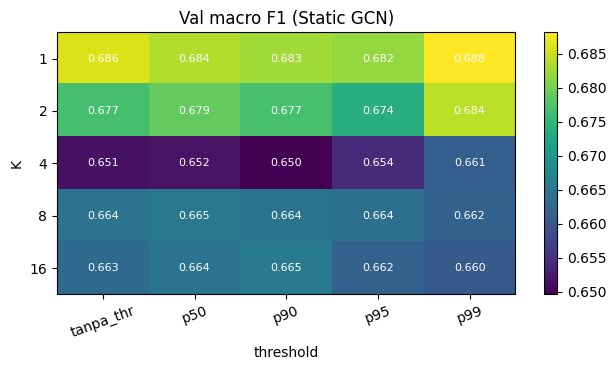

In [52]:
SENS_SEEDS = CFG.SEEDS_MULTIRUN[:3]
K_GRID = [1, 2, 4, 8, 16]
THR_GRID = {
    "tanpa_thr": -1.0,
    "p50": float(np.percentile(sim_sample_train, 50)),
    "p90": float(np.percentile(sim_sample_train, 90)),
    "p95": float(CFG.SIMILARITY_THRESHOLD),
    "p99": float(np.percentile(sim_sample_train, 99)),
}
print("Threshold grid:", {k: round(v, 3) for k, v in THR_GRID.items()})

sens_rows = []
ref0 = run_variant("sens_K0_noedge", EMPTY_EDGES, seeds=SENS_SEEDS, with_test=False, label="K=0 (tanpa edge)")
print(f"[K=0 tanpa edge] val F1 = {ms(ref0['val_f1'])}")
for K in K_GRID:
    for tname, thr in THR_GRID.items():
        ei = edges_from_topk(K, thr)
        res = run_variant(f"sens_K{K}_{tname}", ei, seeds=SENS_SEEDS, with_test=False, label=f"K={K},{tname}")
        hs = homophily_suite(ei, labels)
        indeg = np.bincount(ei[1], minlength=n_nodes)
        sens_rows.append(dict(K=K, threshold=tname, thr_value=round(thr, 3), n_edge=int(ei.shape[1]),
                              avg_in_degree=round(float(indeg.mean()), 2), pct_terisolasi=round(float((indeg == 0).mean() * 100), 1),
                              h_edge=round(hs["h_edge"], 4), h_adjusted=round(hs["h_adjusted"], 4),
                              val_f1_mean=float(np.mean(res["val_f1"])), val_f1_std=float(np.std(res["val_f1"], ddof=1))))
        print(f"K={K:2d} {tname:9s} edges={ei.shape[1]:6d} val F1={ms(res['val_f1'])}")

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "sensitivity_K_threshold_val.csv"), index=False)
pivot = sens_df.pivot(index="K", columns="threshold", values="val_f1_mean")[list(THR_GRID.keys())]
print("\n=== Macro F1 validasi (rata-rata seed): baris = K, kolom = threshold ===")
print(pivot.round(4).to_string())
print(f"Acuan K=0 (tanpa edge): {np.mean(ref0['val_f1']):.4f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns, rotation=20)
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels(pivot.index)
for r_ in range(pivot.shape[0]):
    for c_ in range(pivot.shape[1]):
        ax.text(c_, r_, f"{pivot.values[r_, c_]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.set_xlabel("threshold"); ax.set_ylabel("K"); ax.set_title("Val macro F1 (Static GCN)")
plt.colorbar(im); plt.tight_layout()
plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "sensitivity_heatmap.png"), dpi=150, bbox_inches="tight"); plt.show()

In [53]:
# ---- Pilih konfigurasi terbaik pada VALIDASI, lalu evaluasi sekali pada uji (5 seed) ----
best_row = sens_df.loc[sens_df["val_f1_mean"].idxmax()]
default_row = sens_df[(sens_df["K"] == CFG.TOP_K) & (sens_df["threshold"] == "p95")].iloc[0]
print(f"Terbaik pada validasi : K={int(best_row.K)}, {best_row.threshold} (val F1 {best_row.val_f1_mean:.4f} ± {best_row.val_f1_std:.4f})")
print(f"Default naskah        : K={CFG.TOP_K}, p95        (val F1 {default_row.val_f1_mean:.4f} ± {default_row.val_f1_std:.4f})")
diff = best_row.val_f1_mean - default_row.val_f1_mean
print(f"Selisih = {diff:+.4f}; simpangan baku default = {default_row.val_f1_std:.4f} -> "
      f"{'dalam rentang derau seed (tidak dianggap nyata)' if abs(diff) < default_row.val_f1_std else 'melebihi satu simpangan baku'}")

sens_best = dict(K=int(best_row.K), threshold=str(best_row.threshold), val_f1_mean=float(best_row.val_f1_mean),
                 default_val_f1_mean=float(default_row.val_f1_mean), diff=float(diff), within_noise=bool(abs(diff) < default_row.val_f1_std))

ei_def = edges_from_topk(CFG.TOP_K, CFG.SIMILARITY_THRESHOLD)
res_def = run_variant("gcn_default_K4_p95", ei_def, with_test=True, label=f"GCN K={CFG.TOP_K}, p95 (default, 5 seed)")
if (int(best_row.K), str(best_row.threshold)) != (CFG.TOP_K, "p95"):
    ei_best = edges_from_topk(int(best_row.K), THR_GRID[str(best_row.threshold)])
    res_best = run_variant("gcn_best_val", ei_best, with_test=True, label=f"GCN K={int(best_row.K)}, {best_row.threshold} (terbaik-val)")
else:
    res_best = None
    print("Konfigurasi terbaik-val sama dengan default.")

print("\n=== Uji (5 seed) ===")
rows_ = [variant_row(res_def)] + ([variant_row(res_best)] if res_best else [])
print(pd.DataFrame(rows_).to_string(index=False))
orig_gcn_f1 = [m["f1_macro"] for m in all_test_metrics["StaticGCN"]]
print(f"\nReplikasi: Static GCN asli (Section 16) test macro F1 = {ms(orig_gcn_f1)}  vs  varian generik default = {ms([m['f1_macro'] for m in res_def['test_metrics']])}")

Terbaik pada validasi : K=1, p99 (val F1 0.6882 ± 0.0019)
Default naskah        : K=4, p95        (val F1 0.6542 ± 0.0038)
Selisih = +0.0340; simpangan baku default = 0.0038 -> melebihi satu simpangan baku

=== Uji (5 seed) ===
                        varian  n_param  n_edge    val_f1_macro  best_epoch_median   test_f1_macro        test_acc   test_valid_f1
GCN K=4, p95 (default, 5 seed)    98690   13114 0.6509 ± 0.0059                  6 0.6811 ± 0.0486 0.8015 ± 0.0120 0.4857 ± 0.0940
    GCN K=1, p99 (terbaik-val)    98690    3044 0.6847 ± 0.0051                  7 0.7496 ± 0.0059 0.8314 ± 0.0028 0.6065 ± 0.0103

Replikasi: Static GCN asli (Section 16) test macro F1 = 0.6811 ± 0.0486  vs  varian generik default = 0.6811 ± 0.0486


## Section 27 — Ablasi Self-Loop dan Pemisahan Fitur Sendiri vs Tetangga

**[TAMBAHAN — Revisi Langkah 6b]** Pada Section 20 terlihat bahwa prediksi node baru ditentukan oleh fitur node itu sendiri dan tetangga masuknya saja. Pertanyaan berikutnya: seberapa besar peran masing-masing? Ablasi ini dijalankan pada graf default (K = 4, threshold p95) dengan lima seed:

- **A0** GCN standar, self-loop 1.0 (konfigurasi naskah).
- **A1** self-loop 0: node hanya melihat tetangga, fiturnya sendiri tidak dipakai. Node tanpa tetangga masuk menerima vektor nol.
- **A2–A4** self-loop 0.5, 2.0, dan 4.0: mengatur seberapa dominan fitur sendiri dalam rata-rata. Self-loop yang membesar mendekatkan model ke MLP.
- **A5** pemisahan fitur sendiri vs tetangga (gaya GraphSAGE): `W_self·x + W_nei·mean(x_tetangga)`, dengan bobot terpisah sehingga model bebas menentukan sendiri kontribusi relatif tetangga.

Pada GCN standar, bobot fitur sendiri dan tetangga dibagi sama rata (self-loop 1 di antara `deg` tetangga), sehingga model tidak bisa belajar "abaikan tetangga" bila tetangga memang kurang informatif. A5 menguji kemampuan itu. Hasil validasi dan uji dilaporkan berdampingan (uji hanya untuk pelaporan, bukan untuk memilih).

In [54]:
ABL = [
    ("A0 GCN standar (self-loop 1.0)", dict(self_loop_weight=1.0, separate_self=False)),
    ("A1 self-loop 0 (tetangga saja)", dict(self_loop_weight=0.0, separate_self=False)),
    ("A2 self-loop 0.5",               dict(self_loop_weight=0.5, separate_self=False)),
    ("A3 self-loop 2.0",               dict(self_loop_weight=2.0, separate_self=False)),
    ("A4 self-loop 4.0",               dict(self_loop_weight=4.0, separate_self=False)),
    ("A5 pisah sendiri/tetangga (SAGE)", dict(self_loop_weight=0.0, separate_self=True)),
]
abl_rows = []
for lab_, kw in ABL:
    tag = "abl_" + lab_.split()[0]
    if lab_.startswith("A0"):
        res = dict(variant_results["gcn_default_K4_p95"]); res["label"] = lab_
    else:
        res = run_variant(tag, edge_index_full, label=lab_, **kw)
    abl_rows.append(variant_row(res))
ablation_df = pd.DataFrame(abl_rows)
print(ablation_df[["varian", "n_param", "val_f1_macro", "test_f1_macro", "test_valid_f1", "test_acc"]].to_string(index=False))
ablation_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "ablation_selfloop_separate.csv"), index=False)

a0 = np.mean([m["f1_macro"] for m in variant_results["gcn_default_K4_p95"]["test_metrics"]])
a5 = np.mean([m["f1_macro"] for m in variant_results["abl_A5"]["test_metrics"]])
a1 = np.mean([m["f1_macro"] for m in variant_results["abl_A1"]["test_metrics"]])
print(f"\nTest macro F1: A0={a0:.4f} | A1 (tetangga saja)={a1:.4f} | A5 (pisah)={a5:.4f}")
print("Bila A1 jauh di bawah A0 -> fitur sendiri membawa sebagian besar sinyal; bila A5 > A0 -> pembobotan sama rata pada GCN merugikan.")

                          varian  n_param    val_f1_macro   test_f1_macro   test_valid_f1        test_acc
  A0 GCN standar (self-loop 1.0)    98690 0.6509 ± 0.0059 0.6811 ± 0.0486 0.4857 ± 0.0940 0.8015 ± 0.0120
  A1 self-loop 0 (tetangga saja)    98690 0.6401 ± 0.0080 0.7019 ± 0.0491 0.5256 ± 0.0887 0.8065 ± 0.0198
                A2 self-loop 0.5    98690 0.6424 ± 0.0063 0.6855 ± 0.0548 0.4905 ± 0.1023 0.8069 ± 0.0177
                A3 self-loop 2.0    98690 0.6571 ± 0.0050 0.6871 ± 0.0378 0.4970 ± 0.0715 0.8031 ± 0.0115
                A4 self-loop 4.0    98690 0.6712 ± 0.0046 0.7258 ± 0.0348 0.5685 ± 0.0643 0.8164 ± 0.0135
A5 pisah sendiri/tetangga (SAGE)   197122 0.6845 ± 0.0033 0.7494 ± 0.0191 0.6021 ± 0.0365 0.8359 ± 0.0053

Test macro F1: A0=0.6811 | A1 (tetangga saja)=0.7019 | A5 (pisah)=0.7494
Bila A1 jauh di bawah A0 -> fitur sendiri membawa sebagian besar sinyal; bila A5 > A0 -> pembobotan sama rata pada GCN merugikan.


## Section 28 — Kapasitas MLP Disamakan dan Jumlah Parameter

**[TAMBAHAN — Revisi Langkah 6c]** Pada Section 11, MLP baseline memiliki dua lapis tersembunyi (768→128→64→2), Static GCN satu lapis (768→128→2), dan TGNN satu lapis GCN ditambah `GRUCell` (jumlah parameter sekitar dua kali lipat). Jadi kapasitas tidak seragam dan perbandingan MLP vs GCN vs TGNN tidak sepenuhnya adil dari sisi kapasitas.

Section ini menambahkan varian dengan kapasitas disamakan, memakai kelas `GraphClassifier` yang sama dengan graf tanpa edge:
- **MLP 1-lapis h=128**: jumlah parameter sama dengan Static GCN.
- **MLP 1-lapis h=256**: jumlah parameter mendekati TGNN (selisih kurang dari 1%).
- **Static GCN h=256**: GCN pada graf default dengan jumlah parameter mendekati TGNN, sebagai pembanding adil bagi TGNN.

Tabel jumlah parameter seluruh model dicetak dari model yang benar-benar dilatih, bukan dihitung manual.

In [55]:
res_mlp128 = run_variant("cap_mlp1_h128", EMPTY_EDGES, hidden_dim=128, label="MLP 1-lapis h=128 (param = GCN)")
res_mlp256 = run_variant("cap_mlp1_h256", EMPTY_EDGES, hidden_dim=256, label="MLP 1-lapis h=256 (param ~ TGNN)")
res_gcn256 = run_variant("cap_gcn_h256", edge_index_full, hidden_dim=256, label="Static GCN h=256 (param ~ TGNN)")

params_tbl = {
    "MLP 2-lapis (asli, Section 11)": count_params(mlp_results[CFG.SEEDS_MULTIRUN[0]]["model"]),
    "Static GCN (asli)": count_params(gcn_results[CFG.SEEDS_MULTIRUN[0]]["model"]),
    "TGNN": count_params(mem_models[("TGNN", CFG.SEEDS_MULTIRUN[0])][0]),
    res_mlp128["label"]: res_mlp128["n_params"],
    res_mlp256["label"]: res_mlp256["n_params"],
    res_gcn256["label"]: res_gcn256["n_params"],
}
params_df = pd.DataFrame({"model": list(params_tbl.keys()), "n_param": list(params_tbl.values())})
params_df["rasio_vs_TGNN"] = (params_df["n_param"] / params_tbl["TGNN"]).round(3)
print(params_df.to_string(index=False))

cap_rows = [variant_row(variant_results[t]) for t in ["cap_mlp1_h128", "cap_mlp1_h256", "gcn_default_K4_p95", "cap_gcn_h256"]]
cap_df = pd.DataFrame(cap_rows)
print("\n=== Kapasitas disamakan (5 seed) ===")
print(cap_df[["varian", "n_param", "val_f1_macro", "test_f1_macro", "test_valid_f1", "test_acc"]].to_string(index=False))
orig_rows = pd.DataFrame([
    dict(varian="MLP 2-lapis (asli)", test_f1_macro=ms([m["f1_macro"] for m in all_test_metrics["MLP"]])),
    dict(varian="Static GCN (asli)", test_f1_macro=ms([m["f1_macro"] for m in all_test_metrics["StaticGCN"]])),
    dict(varian="TGNN", test_f1_macro=ms([m["f1_macro"] for m in mem_metrics["TGNN"]]))])
print("\nPembanding (Section 16):"); print(orig_rows.to_string(index=False))
cap_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "capacity_matched.csv"), index=False)
params_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "param_counts.csv"), index=False)

                           model  n_param  rasio_vs_TGNN
  MLP 2-lapis (asli, Section 11)   106818          0.499
               Static GCN (asli)    98690          0.461
                            TGNN   214274          1.000
 MLP 1-lapis h=128 (param = GCN)    98690          0.461
MLP 1-lapis h=256 (param ~ TGNN)   197378          0.921
 Static GCN h=256 (param ~ TGNN)   197378          0.921

=== Kapasitas disamakan (5 seed) ===
                          varian  n_param    val_f1_macro   test_f1_macro   test_valid_f1        test_acc
 MLP 1-lapis h=128 (param = GCN)    98690 0.6965 ± 0.0038 0.7626 ± 0.0115 0.6384 ± 0.0164 0.8275 ± 0.0106
MLP 1-lapis h=256 (param ~ TGNN)   197378 0.6942 ± 0.0021 0.7611 ± 0.0108 0.6355 ± 0.0163 0.8272 ± 0.0086
  GCN K=4, p95 (default, 5 seed)    98690 0.6509 ± 0.0059 0.6811 ± 0.0486 0.4857 ± 0.0940 0.8015 ± 0.0120
 Static GCN h=256 (param ~ TGNN)   197378 0.6533 ± 0.0022 0.7112 ± 0.0417 0.5401 ± 0.0708 0.8126 ± 0.0229

Pembanding (Section 16):
       

## Section 29 — Baseline Mayoritas dan Logistic Regression

**[TAMBAHAN — Revisi Langkah 6d]** Model neural di notebook belum diletakkan di samping baseline sangat sederhana. Tiga baseline ditambahkan:

1. **Mayoritas**: selalu memprediksi `hoax`. Dengan proporsi hoax sekitar 77% pada data uji, akurasinya sudah tinggi sedangkan macro F1-nya rendah, jadi baseline ini menjelaskan mengapa akurasi tidak boleh dipakai sendirian.
2. **Logistic Regression pada embedding IndoBERT** (fitur sama dengan semua model, di-standardisasi, `class_weight="balanced"`). Parameter regularisasi `C` dipilih pada validasi.
3. **Logistic Regression pada TF-IDF kata** (unigram + bigram, dipasang pada data latih saja), sebagai baseline yang tidak bergantung pada IndoBERT. `C` juga dipilih pada validasi.

Semua baseline deterministik sehingga tidak memerlukan seed. Data uji hanya dipakai sekali setelah `C` dipilih.

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

y_np = y_all.cpu().numpy()
X_np = embeddings
texts_sorted = df_split.sort_values("node_id")["tweet"].values
y_tr, y_va, y_te = y_np[idx_train], y_np[idx_val], y_np[idx_test]
baseline_preds, baseline_metrics, baseline_info = {}, {}, {}

# 1. Mayoritas
maj_pred = np.ones_like(y_te)                       # 1 = hoax
baseline_preds["Majority (selalu hoax)"] = maj_pred
baseline_metrics["Majority (selalu hoax)"] = evaluate_predictions(y_te, maj_pred)
baseline_info["Majority (selalu hoax)"] = dict(n_param=0, pilihan="-")

# 2 & 3. Logistic Regression (C dipilih pada validasi)
C_GRID = [0.001, 0.01, 0.1, 1, 10]
def fit_select_lr(make_pipe, Xtr, Xva, Xte, name):
    best = (-1, None, None)
    for C in C_GRID:
        pipe = make_pipe(C).fit(Xtr, y_tr)
        f = evaluate_predictions(y_va, pipe.predict(Xva))["f1_macro"]
        if f > best[0]:
            best = (f, C, pipe)
    f_val, C_best, pipe = best
    pred = pipe.predict(Xte); prob = pipe.predict_proba(Xte)[:, 1]
    baseline_preds[name] = pred
    baseline_metrics[name] = evaluate_predictions(y_te, pred, prob)
    n_par = int(pipe[-1].coef_.size + pipe[-1].intercept_.size)
    baseline_info[name] = dict(n_param=n_par, pilihan=f"C={C_best}, val F1={f_val:.4f}")
    print(f"{name}: C terpilih (validasi) = {C_best}, val macro F1 = {f_val:.4f}")

fit_select_lr(lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000)),
              X_np[idx_train], X_np[idx_val], X_np[idx_test], "LogReg embedding IndoBERT")
fit_select_lr(lambda C: make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                      LogisticRegression(C=C, class_weight="balanced", max_iter=3000)),
              texts_sorted[idx_train], texts_sorted[idx_val], texts_sorted[idx_test], "LogReg TF-IDF kata")

baseline_df = pd.DataFrame([dict(model=k, **{m: round(v[m], 4) for m in ["accuracy", "f1_macro", "f1_weighted"]},
                                 roc_auc=round(v.get("roc_auc", float("nan")), 4), **baseline_info[k])
                            for k, v in baseline_metrics.items()])
print("\n=== Baseline sederhana pada data uji ===")
print(baseline_df.to_string(index=False))
print(f"\nProporsi hoax pada data uji = {y_te.mean():.4f} (akurasi mayoritas = itu juga)")
baseline_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "baseline_simple.csv"), index=False)

LogReg embedding IndoBERT: C terpilih (validasi) = 0.001, val macro F1 = 0.7002
LogReg TF-IDF kata: C terpilih (validasi) = 0.001, val macro F1 = 0.6789

=== Baseline sederhana pada data uji ===
                    model  accuracy  f1_macro  f1_weighted  roc_auc  n_param                pilihan
   Majority (selalu hoax)    0.7725    0.4358       0.6733      NaN        0                      -
LogReg embedding IndoBERT    0.8260    0.7602       0.8286   0.8558      769 C=0.001, val F1=0.7002
       LogReg TF-IDF kata    0.8088    0.7122       0.8031   0.8004     7533 C=0.001, val F1=0.6789

Proporsi hoax pada data uji = 0.7725 (akurasi mayoritas = itu juga)


## Section 30 — Bootstrap CI atas Data Uji dan Tabel Hasil Baru

**[TAMBAHAN — Revisi Langkah 6e; bahan Tabel Hasil Baru, Langkah 8]** Data uji hanya 523 tweet (119 valid), sehingga selisih beberapa persen antar model bisa berasal dari sampling uji, bukan dari perbedaan model. Section ini mengukur ketidakpastian itu dengan bootstrap persentil 95%.

Prosedur:
- Tweet uji di-resample dengan pengembalian (`BOOT_B = 2000` kali). Indeks resample yang sama dipakai untuk semua model sehingga selisih antar model bersifat berpasangan (paired).
- Untuk model neural, setiap resample menghitung metrik pada prediksi tiap seed, lalu dirata-ratakan antar seed. CI hasil ini mencerminkan ketidakpastian sampling uji. Variasi antar seed dilaporkan terpisah sebagai simpangan baku (mean ± std dari Section 16, 27, 28).
- Metrik: akurasi, macro F1, dan F1 kelas minoritas (valid).
- Selisih berpasangan (A − B) dilaporkan dengan CI. Jika CI tidak memuat 0, selisih dianggap dapat dibedakan dari derau sampling uji.

Keterbatasan yang harus ditulis di naskah: bootstrap ini mengasumsikan tweet uji saling bebas, sedangkan data berderet waktu dan beberapa tweet dapat membahas topik/kejadian yang sama. Karena itu CI cenderung terlalu sempit.

=== TABEL HASIL BARU: rata-rata seed [CI 95% bootstrap uji] ===
                          model  n_param                accuracy                f1_macro                valid_f1
         Majority (selalu hoax)        0 0.7725 [0.7361, 0.8069] 0.4358 [0.4240, 0.4466] 0.0000 [0.0000, 0.0000]
             LogReg TF-IDF kata     7533 0.8088 [0.7744, 0.8413] 0.7122 [0.6633, 0.7591] 0.5455 [0.4602, 0.6244]
      LogReg embedding IndoBERT      769 0.8260 [0.7935, 0.8585] 0.7602 [0.7151, 0.8028] 0.6345 [0.5610, 0.7050]
             MLP 2-lapis (asli)   106818 0.8279 [0.7985, 0.8566] 0.7653 [0.7252, 0.8025] 0.6441 [0.5783, 0.7042]
              MLP 1-lapis h=128    98690 0.8275 [0.7966, 0.8581] 0.7626 [0.7190, 0.8025] 0.6384 [0.5665, 0.7012]
              MLP 1-lapis h=256   197378 0.8272 [0.7954, 0.8585] 0.7611 [0.7178, 0.8022] 0.6355 [0.5653, 0.7012]
              Static GCN (asli)    98690 0.8015 [0.7705, 0.8325] 0.6811 [0.6364, 0.7211] 0.4857 [0.4097, 0.5523]
               Static GCN h=256 

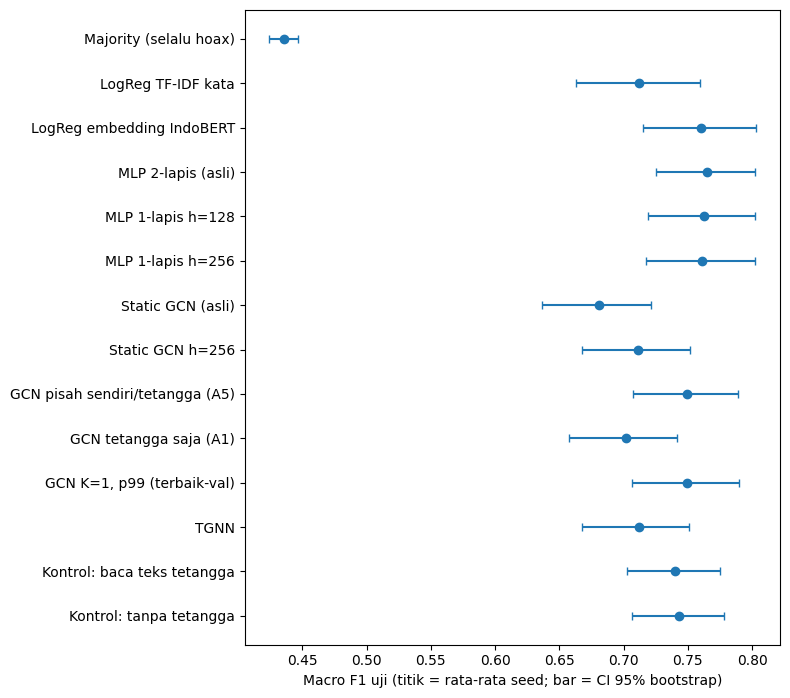

In [57]:
BOOT_B = 2000
seeds_ = list(CFG.SEEDS_MULTIRUN)
true_test = y_all[idx_test].cpu().numpy()

def _preds_from_all(key):
    for s in seeds_:
        assert np.array_equal(all_predictions[key][s][0], true_test)
    return [all_predictions[key][s][1] for s in seeds_]

def _preds_from_variant(tag):
    r = variant_results[tag]
    return [r["preds"][s][1] for s in r["seeds"]]

REG = {
    "Majority (selalu hoax)": ([baseline_preds["Majority (selalu hoax)"]], 0),
    "LogReg TF-IDF kata": ([baseline_preds["LogReg TF-IDF kata"]], baseline_info["LogReg TF-IDF kata"]["n_param"]),
    "LogReg embedding IndoBERT": ([baseline_preds["LogReg embedding IndoBERT"]], baseline_info["LogReg embedding IndoBERT"]["n_param"]),
    "MLP 2-lapis (asli)": (_preds_from_all("MLP"), params_tbl["MLP 2-lapis (asli, Section 11)"]),
    "MLP 1-lapis h=128": (_preds_from_variant("cap_mlp1_h128"), variant_results["cap_mlp1_h128"]["n_params"]),
    "MLP 1-lapis h=256": (_preds_from_variant("cap_mlp1_h256"), variant_results["cap_mlp1_h256"]["n_params"]),
    "Static GCN (asli)": (_preds_from_all("StaticGCN"), params_tbl["Static GCN (asli)"]),
    "Static GCN h=256": (_preds_from_variant("cap_gcn_h256"), variant_results["cap_gcn_h256"]["n_params"]),
    "GCN pisah sendiri/tetangga (A5)": (_preds_from_variant("abl_A5"), variant_results["abl_A5"]["n_params"]),
    "GCN tetangga saja (A1)": (_preds_from_variant("abl_A1"), variant_results["abl_A1"]["n_params"]),
}
if "gcn_best_val" in variant_results:
    r_ = variant_results["gcn_best_val"]
    REG[r_["label"]] = (_preds_from_variant("gcn_best_val"), r_["n_params"])

if "mem_preds" in globals():   # TGNN dan dua kontrolnya (Section 15B)
    for _nm in mem_preds:
        _m0 = mem_models[(_nm, seeds_[0])][0]
        REG[_nm] = ([mem_preds[_nm][s][1] for s in seeds_], sum(p.numel() for p in _m0.parameters()))

rng_b = np.random.default_rng(CFG.SEED)
BOOT_IDX = rng_b.integers(0, len(true_test), size=(BOOT_B, len(true_test)))
yt_b = true_test[BOOT_IDX]

def _f1_class(yt, yp, c):
    tp = ((yt == c) & (yp == c)).sum(1); fp = ((yt != c) & (yp == c)).sum(1); fn = ((yt == c) & (yp != c)).sum(1)
    den = 2 * tp + fp + fn
    return np.where(den == 0, 0.0, 2 * tp / np.maximum(den, 1))

def boot_metrics(pred_list):
    acc, f1m, f1v = [], [], []
    for p in pred_list:
        yp = np.asarray(p)[BOOT_IDX]
        acc.append((yt_b == yp).mean(1))
        f_v, f_h = _f1_class(yt_b, yp, 0), _f1_class(yt_b, yp, 1)
        f1m.append((f_v + f_h) / 2); f1v.append(f_v)
    return dict(accuracy=np.mean(acc, 0), f1_macro=np.mean(f1m, 0), valid_f1=np.mean(f1v, 0))

def point_metrics(pred_list):
    out = dict(accuracy=[], f1_macro=[], valid_f1=[])
    for p in pred_list:
        pc = per_class_metrics_one_seed(true_test, p)
        m = evaluate_predictions(true_test, p)
        out["accuracy"].append(m["accuracy"]); out["f1_macro"].append(m["f1_macro"]); out["valid_f1"].append(pc["valid_f1"])
    return {k: float(np.mean(v)) for k, v in out.items()}

boot_store, ci_rows = {}, []
for name, (plist, npar) in REG.items():
    bm = boot_metrics(plist); pm = point_metrics(plist)
    boot_store[name] = bm
    row = dict(model=name, n_param=npar)
    for m in ["accuracy", "f1_macro", "valid_f1"]:
        lo, hi = np.percentile(bm[m], [2.5, 97.5])
        row[m] = f"{pm[m]:.4f} [{lo:.4f}, {hi:.4f}]"
    ci_rows.append(row)
final_ci_df = pd.DataFrame(ci_rows)
print("=== TABEL HASIL BARU: rata-rata seed [CI 95% bootstrap uji] ===")
print(final_ci_df.to_string(index=False))
final_ci_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "final_results_with_ci.csv"), index=False)

# ---- Selisih berpasangan ----
PAIRS = [("MLP 2-lapis (asli)", "TGNN"), ("MLP 2-lapis (asli)", "Static GCN (asli)"),
         ("TGNN", "Static GCN (asli)"), ("MLP 1-lapis h=256", "TGNN"),
         ("MLP 1-lapis h=128", "Static GCN (asli)"), ("Static GCN h=256", "TGNN"),
         ("LogReg embedding IndoBERT", "TGNN"), ("LogReg embedding IndoBERT", "Static GCN (asli)"),
         ("GCN pisah sendiri/tetangga (A5)", "Static GCN (asli)"),
         ("TGNN", "Kontrol: baca teks tetangga"), ("TGNN", "Kontrol: tanpa tetangga"),
         ("Kontrol: baca teks tetangga", "Kontrol: tanpa tetangga")]
pair_rows = []
for a_, b_ in PAIRS:
    if a_ not in boot_store or b_ not in boot_store: continue
    for m in ["f1_macro", "valid_f1", "accuracy"]:
        d = boot_store[a_][m] - boot_store[b_][m]
        lo, hi = np.percentile(d, [2.5, 97.5])
        pair_rows.append(dict(A=a_, B=b_, metrik=m, selisih_A_minus_B=round(float(d.mean()), 4),
                              ci_low=round(float(lo), 4), ci_high=round(float(hi), 4), CI_tidak_memuat_0=bool(lo > 0 or hi < 0)))
paired_df = pd.DataFrame(pair_rows)
print("\n=== Selisih berpasangan (A - B), bootstrap ===")
print(paired_df[paired_df.metrik == "f1_macro"].to_string(index=False))
paired_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "paired_differences_bootstrap.csv"), index=False)

# ---- Plot macro F1 + CI ----
names_ = list(REG.keys())
pt = [point_metrics(REG[n][0])["f1_macro"] for n in names_]
lo_ = [np.percentile(boot_store[n]["f1_macro"], 2.5) for n in names_]; hi_ = [np.percentile(boot_store[n]["f1_macro"], 97.5) for n in names_]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(names_) + 1.2))
ypos = np.arange(len(names_))
ax.errorbar(pt, ypos, xerr=[np.array(pt) - np.array(lo_), np.array(hi_) - np.array(pt)], fmt="o", capsize=3)
ax.set_yticks(ypos); ax.set_yticklabels(names_); ax.invert_yaxis()
ax.set_xlabel("Macro F1 uji (titik = rata-rata seed; bar = CI 95% bootstrap)")
plt.tight_layout(); plt.savefig(os.path.join(CFG.ARTIFACT_DIR, "final_f1_ci.png"), dpi=150, bbox_inches="tight"); plt.show()

## Section 30B — Selisih Berpasangan Tambahan dan Koreksi untuk Banyak Perbandingan

**[TAMBAHAN — Revisi v2]** Section 30 melaporkan CI 95% untuk setiap selisih berpasangan secara terpisah. Karena sekarang ada banyak perbandingan sekaligus, satu selisih bisa tampak "signifikan" hanya karena kebetulan (misalnya TGNN vs kontrol tanpa tetangga, yang CI-nya nyaris menyentuh nol). Section ini menambahkan dua hal:

1. **Pasangan yang belum diuji**: MLP terhadap kontrol tanpa tetangga, kontrol baca-teks, varian GCN terbaik (pisah fitur sendiri/tetangga, dan K=1/p99), dan GCN berkapasitas sama.
2. **CI 99% sebagai pelonggaran sederhana untuk banyak perbandingan.** Selisih yang CI 95%-nya tidak memuat 0 tetapi CI 99%-nya memuat 0 dibaca sebagai bukti lemah dan tidak boleh dijadikan klaim utama.

Hanya macro F1 yang dilaporkan di sini. Semua perhitungan memakai indeks bootstrap yang sama dengan Section 30 (`BOOT_IDX`), jadi selisihnya berpasangan.

In [58]:
_gcn_best = next((n for n in boot_store if n.startswith("GCN K=") and "terbaik-val" in n), None)
EXTRA_PAIRS = [
    ("MLP 2-lapis (asli)", "Kontrol: tanpa tetangga"),
    ("MLP 2-lapis (asli)", "Kontrol: baca teks tetangga"),
    ("MLP 2-lapis (asli)", "GCN pisah sendiri/tetangga (A5)"),
    ("MLP 2-lapis (asli)", "Static GCN h=256"),
    ("GCN pisah sendiri/tetangga (A5)", "TGNN"),
]
if _gcn_best:
    EXTRA_PAIRS.append(("MLP 2-lapis (asli)", _gcn_best))
ALL_PAIRS = list(PAIRS) + [p for p in EXTRA_PAIRS if p not in PAIRS]

rows_ = []
for a_, b_ in ALL_PAIRS:
    if a_ not in boot_store or b_ not in boot_store:
        continue
    d = boot_store[a_]["f1_macro"] - boot_store[b_]["f1_macro"]
    lo95, hi95 = np.percentile(d, [2.5, 97.5]); lo99, hi99 = np.percentile(d, [0.5, 99.5])
    rows_.append(dict(A=a_, B=b_, selisih=round(float(d.mean()), 4),
                      ci95_low=round(float(lo95), 4), ci95_high=round(float(hi95), 4),
                      ci99_low=round(float(lo99), 4), ci99_high=round(float(hi99), 4),
                      beda_di_95=bool(lo95 > 0 or hi95 < 0), beda_di_99=bool(lo99 > 0 or hi99 < 0)))
paired_extra_df = pd.DataFrame(rows_)
paired_extra_df["bukti"] = np.where(paired_extra_df["beda_di_99"], "kuat (CI99 tidak memuat 0)",
                             np.where(paired_extra_df["beda_di_95"], "lemah (hanya CI95)", "tidak terbedakan"))
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
print(f"Jumlah perbandingan: {len(paired_extra_df)} (semakin banyak perbandingan, semakin besar peluang selisih 'signifikan' secara kebetulan)\n")
print(paired_extra_df[["A", "B", "selisih", "ci95_low", "ci95_high", "ci99_low", "ci99_high", "bukti"]].to_string(index=False))
paired_extra_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "paired_differences_ci95_ci99.csv"), index=False)

Jumlah perbandingan: 18 (semakin banyak perbandingan, semakin besar peluang selisih 'signifikan' secara kebetulan)

                              A                               B  selisih  ci95_low  ci95_high  ci99_low  ci99_high                      bukti
             MLP 2-lapis (asli)                            TGNN   0.0534    0.0195     0.0894    0.0083     0.0985 kuat (CI99 tidak memuat 0)
             MLP 2-lapis (asli)               Static GCN (asli)   0.0842    0.0460     0.1218    0.0333     0.1332 kuat (CI99 tidak memuat 0)
                           TGNN               Static GCN (asli)   0.0308    0.0062     0.0559   -0.0003     0.0631         lemah (hanya CI95)
              MLP 1-lapis h=256                            TGNN   0.0493    0.0121     0.0877    0.0011     0.0988 kuat (CI99 tidak memuat 0)
              MLP 1-lapis h=128               Static GCN (asli)   0.0815    0.0429     0.1203    0.0304     0.1295 kuat (CI99 tidak memuat 0)
               Static GCN h=256 

## Section 30C — Protokol Berhenti Alternatif (Patience Lebih Besar) untuk Semua Model

**[TAMBAHAN — Revisi v2]** Pada Section 21 terlihat bahwa nilai macro F1 uji model graf berubah cukup besar ketika patience diperbesar, sementara macro F1 validasi hampir tidak berubah. Artinya kriteria berhenti berbasis macro F1 validasi (hanya 136 tweet kelas valid) cukup berisik, dan selisih antar model bisa ikut bergeser bila protokol berhenti diganti. Section ini menjawab pertanyaan itu secara langsung: semua model yang menjadi inti kesimpulan dilatih ulang dengan **patience 30 dan maksimum 300 epoch** (selain itu protokolnya sama: 5 seed, split, loss berbobot, K = 4), lalu dibandingkan dengan protokol awal.

Model yang dilatih ulang: MLP 2-lapis, Static GCN, TGNN, dan dua kontrolnya.

Penting untuk penafsiran: **kedua protokol dilaporkan berdampingan, dan tidak ada yang dipilih berdasarkan data uji.** Kesimpulan yang aman adalah yang berlaku di kedua protokol. Bila arah dan ukuran selisihnya berubah antar protokol, tulis itu sebagai keterbatasan.

Sel ini membutuhkan `cfg_override` (Section 21) dan bootstrap Section 30 sudah dijalankan.

In [59]:
RUN_ALT_STOP = True
ALT_PATIENCE, ALT_EPOCHS = 30, 300
alt_dir = os.path.join(CFG.ARTIFACT_DIR, "alt_stop"); os.makedirs(alt_dir, exist_ok=True)
alt_metrics, alt_preds, alt_val, alt_epochs = {}, {}, {}, {}

def _store_alt(name, met, pred, hist):
    alt_metrics.setdefault(name, []).append(met); alt_preds.setdefault(name, []).append(np.asarray(pred))
    alt_val.setdefault(name, []).append(float(hist["val_f1_macro"].max())); alt_epochs.setdefault(name, []).append(len(hist))

if RUN_ALT_STOP:
    with cfg_override(ARTIFACT_DIR=alt_dir, PATIENCE=ALT_PATIENCE, EPOCHS=ALT_EPOCHS):
        for seed in CFG.SEEDS_MULTIRUN:
            m_, h_ = train_mlp(seed);        met_, _, p_ = eval_mlp_test(m_); _store_alt("MLP 2-lapis (asli)", met_, p_, h_)
            m_, h_ = train_static_gcn(seed); met_, _, p_ = eval_gcn_test(m_); _store_alt("Static GCN (asli)", met_, p_, h_)
            for nm_, (mode_, dec_) in MEM_VARIANTS.items():
                m_, h_ = train_mem(seed, mode_, dec_); met_, _, p_ = eval_mem_test(m_); _store_alt(nm_, met_, p_, h_)
            print(f"seed {seed} selesai")

    default_f1 = {"MLP 2-lapis (asli)": all_test_metrics["MLP"], "Static GCN (asli)": all_test_metrics["StaticGCN"], **mem_metrics}
    def _ms(v): v = np.asarray(v, float); return f"{v.mean():.4f} ± {v.std(ddof=1):.4f}"
    cmp_rows, alt_boot = [], {}
    for nm_ in alt_metrics:
        bm_ = boot_metrics(alt_preds[nm_]); alt_boot[nm_] = bm_
        lo_, hi_ = np.percentile(bm_["f1_macro"], [2.5, 97.5])
        cmp_rows.append(dict(model=nm_,
                             f1_protokol_awal=_ms([m["f1_macro"] for m in default_f1[nm_]]),
                             f1_protokol_alt=_ms([m["f1_macro"] for m in alt_metrics[nm_]]),
                             ci95_alt=f"[{lo_:.4f}, {hi_:.4f}]",
                             val_f1_alt=_ms(alt_val[nm_]), epoch_rata2_alt=round(float(np.mean(alt_epochs[nm_])), 1)))
    alt_compare_df = pd.DataFrame(cmp_rows)
    print("\n=== Protokol awal (patience 10) vs alternatif (patience 30) ===")
    print(alt_compare_df.to_string(index=False))
    alt_compare_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "alt_stop_comparison.csv"), index=False)

    ALT_PAIRS = [("MLP 2-lapis (asli)", "TGNN"), ("MLP 2-lapis (asli)", "Kontrol: baca teks tetangga"),
                 ("MLP 2-lapis (asli)", "Kontrol: tanpa tetangga"), ("MLP 2-lapis (asli)", "Static GCN (asli)"),
                 ("TGNN", "Kontrol: baca teks tetangga"), ("Kontrol: baca teks tetangga", "Kontrol: tanpa tetangga"),
                 ("TGNN", "Kontrol: tanpa tetangga")]
    ap_rows = []
    for a_, b_ in ALT_PAIRS:
        d = alt_boot[a_]["f1_macro"] - alt_boot[b_]["f1_macro"]
        lo95, hi95 = np.percentile(d, [2.5, 97.5]); lo99, hi99 = np.percentile(d, [0.5, 99.5])
        ap_rows.append(dict(A=a_, B=b_, selisih=round(float(d.mean()), 4), ci95_low=round(float(lo95), 4), ci95_high=round(float(hi95), 4),
                            ci99_low=round(float(lo99), 4), ci99_high=round(float(hi99), 4),
                            bukti=("kuat (CI99 tidak memuat 0)" if (lo99 > 0 or hi99 < 0) else "lemah (hanya CI95)" if (lo95 > 0 or hi95 < 0) else "tidak terbedakan")))
    alt_paired_df = pd.DataFrame(ap_rows)
    print("\n=== Selisih berpasangan pada protokol alternatif (macro F1) ===")
    print(alt_paired_df.to_string(index=False))
    alt_paired_df.to_csv(os.path.join(CFG.ARTIFACT_DIR, "alt_stop_paired.csv"), index=False)
else:
    alt_compare_df = alt_paired_df = None
    print("RUN_ALT_STOP=False, bagian ini dilewati.")

[MLP seed=42] early stop di epoch 92, best val f1_macro=0.7060
[GCN seed=42] early stop di epoch 56, best val f1_macro=0.6508
seed 42 selesai
[MLP seed=123] early stop di epoch 66, best val f1_macro=0.7055
[GCN seed=123] early stop di epoch 30, best val f1_macro=0.6558
seed 123 selesai
[MLP seed=2024] early stop di epoch 65, best val f1_macro=0.7103
[GCN seed=2024] early stop di epoch 37, best val f1_macro=0.6569
seed 2024 selesai
[MLP seed=7] early stop di epoch 65, best val f1_macro=0.7068
[GCN seed=7] early stop di epoch 38, best val f1_macro=0.6497
seed 7 selesai
[MLP seed=999] early stop di epoch 46, best val f1_macro=0.6999
[GCN seed=999] early stop di epoch 53, best val f1_macro=0.6541
seed 999 selesai

=== Protokol awal (patience 10) vs alternatif (patience 30) ===
                      model f1_protokol_awal f1_protokol_alt         ci95_alt      val_f1_alt  epoch_rata2_alt
         MLP 2-lapis (asli)  0.7653 ± 0.0135 0.7570 ± 0.0051 [0.7165, 0.7959] 0.7057 ± 0.0038            

## Section 31 — Posisi Kontribusi: Ringkasan Temuan yang Mendukung Keputusan

**[TAMBAHAN — Revisi Langkah 7]** Keputusan posisi kontribusi tetap ada pada penulis. Rekomendasi kerja yang konsisten dengan arah Reviewer 2 adalah memposisikan penelitian sebagai **evaluasi empiris dengan temuan negatif** (graf kemiripan dan komponen temporal tidak mengungguli baseline tanpa graf pada setting ini), lalu menyesuaikan klaim novelty. Section ini tidak memutuskan atas nama penulis, tetapi menurunkan dari hasil yang sudah dihitung di Section 20–30 pernyataan apa saja yang boleh dan tidak boleh ditulis di naskah.

Setiap baris di bawah dibentuk secara kondisional dari angka hasil eksekusi. Bila sebuah section belum dijalankan, baris yang bersangkutan ditandai `[belum dijalankan]` dan tidak berisi kesimpulan apa pun. Hasil dicetak dan disimpan ke `contribution_position_summary.txt` agar bisa ditempel ke catatan revisi.

In [60]:
def _g(name):
    return globals().get(name, None)

lines = []
def add(tag, text): lines.append(f"[{tag}] {text}")

# --- Langkah 1: bukti struktural (Section 20.1) ---
_adj = _g("adjacency_rows_identical")
if _adj is None:
    add("L1", "[belum dijalankan] Section 20.1.")
else:
    add("L1", f"Bukti struktural kausalitas: baris adjacency node baru identik dengan graf penuh dan tidak ada edge ke masa depan di semua snapshot -> {_adj}.")

# --- Langkah 2: early stopping ---
lc = _g("lr_check_summary_df")
if lc is None:
    add("L2", "[belum dijalankan] Section 21.")
else:
    msgs = []
    for nm in lc.index.get_level_values(0).unique():
        sub = lc.loc[nm]; base = sub.loc["baseline(1e-3,p10)", "val_f1_mean"]; gain = sub["val_f1_mean"].max() - base
        msgs.append(f"{nm}: gain val F1 {gain:+.4f}")
    add("L2", "Pemeriksaan lr/patience -> " + "; ".join(msgs) + ". Gain < 0.01 berarti penghentian dini wajar (tidak ada masalah pelatihan); gain >= 0.01 berarti tuliskan konfigurasi yang diperbaiki.")

# --- Langkah 3: struktur graf ---
gs = _g("graph_structure_summary"); nc = _g("neighbor_comp_df")
if gs is None:
    add("L3", "[belum dijalankan] Section 22.")
else:
    add("L3", f"Homophily terkoreksi: adjusted={gs['adjusted_homophily_full']:.3f} (graf penuh), {gs['adjusted_homophily_to_test']:.3f} (edge menuju uji); "
              f"class-insensitive={gs['ci_homophily_full']:.3f}. Oracle mayoritas-label-tetangga macro F1={gs['oracle_f1_macro']:.3f}. "
              f"Node uji terisolasi {gs['isolated_test_pct']:.1f}%. " + ("Adjusted mendekati 0: homophily mentah hanyalah efek proporsi kelas." if gs['adjusted_homophily_full'] < 0.1 else "Ada homophily di atas acak tetapi lemah (adjusted jauh di bawah homophily mentah); jangan menulis graf 'sangat homofilik'."))

# --- Langkah 4: edge lintas kelas ---
an = _g("cross_edge_annotation_summary")
if an is None:
    add("L4", "[belum diisi manual] Section 23: kesimpulan konseptual hanya boleh ditulis setelah anotasi manual selesai.")
else:
    add("L4", f"Telaah manual: topik sama pada {an['topik_sama_pct']:.0%} sampel; tweet valid berisi bantahan pada {an['bantahan_pct']:.0%}.")

# --- Langkah 6: sensitivitas, kapasitas, baseline ---
sb = _g("sens_best")
if sb is None:
    add("L6a", "[belum dijalankan] Section 26.")
else:
    add("L6a", f"Konfigurasi terbaik-val K={sb['K']}, {sb['threshold']} (val F1 {sb['val_f1_mean']:.4f}) vs default {sb['default_val_f1_mean']:.4f}; "
               f"selisih {sb['diff']:+.4f} -> {'dalam derau antar seed, K/threshold bukan penentu utama' if sb['within_noise'] else 'melebihi derau seed: laporkan sensitivitas K sebagai temuan'}.")

pdf_ = _g("paired_df")
if pdf_ is None:
    add("L6b", "[belum dijalankan] Section 30.")
else:
    def pair(a, b, m="f1_macro"):
        r = pdf_[(pdf_.A == a) & (pdf_.B == b) & (pdf_.metrik == m)]
        return None if r.empty else r.iloc[0]
    for a, b, desc in [("MLP 2-lapis (asli)", "TGNN", "MLP vs TGNN"), ("MLP 2-lapis (asli)", "Static GCN (asli)", "MLP vs Static GCN"),
                       ("TGNN", "Static GCN (asli)", "TGNN vs Static GCN"), ("MLP 1-lapis h=256", "TGNN", "MLP 1-lapis h=256 vs TGNN (kapasitas ~sama)")]:
        r = pair(a, b)
        if r is None: continue
        arah = ("A lebih tinggi" if r.ci_low > 0 else "B lebih tinggi" if r.ci_high < 0 else "tidak dapat dibedakan")
        add("L6b", f"{desc}: selisih macro F1 (A-B) {r.selisih_A_minus_B:+.4f} CI [{r.ci_low:+.4f}, {r.ci_high:+.4f}] -> {arah}.")

# --- Langkah 7: rekomendasi posisi (memperhitungkan TGNN, Section 15B) ---
if pdf_ is not None:
    r1, r2 = pair("MLP 2-lapis (asli)", "TGNN"), pair("MLP 2-lapis (asli)", "Static GCN (asli)")
    r_mem = pair("TGNN", "Kontrol: baca teks tetangga")
    r_gr = pair("Kontrol: baca teks tetangga", "Kontrol: tanpa tetangga")
    r_mlp_mem = pair("MLP 2-lapis (asli)", "TGNN")
    mlp_wins = all((r is not None) and (r.ci_low > 0) for r in [r1, r2])
    helps_mem = (r_mem is not None) and (r_mem.ci_low > 0)
    helps_graph = (r_gr is not None) and (r_gr.ci_low > 0)
    if helps_mem or helps_graph:
        add("L7", "Ada indikasi memori atau graf membantu (lihat L8b) -> tinjau ulang Section 30/30B/30C sebelum menentukan posisi; klaim hanya boleh seluas yang didukung CI.")
    elif mlp_wins:
        add("L7", "REKOMENDASI POSISI: tidak ada bukti graf maupun memori temporal membantu (efek graf dan efek memori tidak positif; MLP lebih tinggi dari model graf). "
                  "Posisikan sebagai evaluasi empiris: 'kami mengevaluasi apakah graf kemiripan dan memori temporal meningkatkan deteksi hoaks'. "
                  "Hindari kata 'mengusulkan' dan klaim bahwa model memanfaatkan dinamika waktu. Batasi klaim pada rancangan yang diuji (satu mekanisme memori; varian decay waktu belum dijalankan). "
                  "Jelaskan di response to reviewer bahwa TGNN versi memori aktif dibuat setelah versi awal terbukti memorinya tidak aktif.")
    elif all(r is not None and not (r.ci_high < 0) for r in [r1, r2]):
        add("L7", "REKOMENDASI POSISI: tidak ada bukti graf mengungguli MLP -> tetap posisikan sebagai evaluasi empiris; klaim 'graf/temporal meningkatkan' tidak boleh ditulis.")
    else:
        add("L7", "Ada bukti graf mengungguli MLP pada sebagian metrik -> tinjau ulang Section 30 sebelum menentukan posisi.")

# --- Langkah 8: efek memori aktif (Section 15B) ---
ms_ = _g("mem_sanity_df")
if ms_ is None:
    add("L8a", "[belum dijalankan] Section 20.5.")
else:
    add("L8a", f"TGNN: selisih logit maks akibat derau pada state lama {ms_.max_abs_dlogit_noise.max():.2f}, prediksi sama {ms_.pred_sama.min():.0%} sampai {ms_.pred_sama.max():.0%} -> "
               f"{'memori DIPAKAI' if ms_.max_abs_dlogit_noise.max() > 1e-3 else 'memori belum berpengaruh, periksa kembali'}.")
if pdf_ is not None and "TGNN" in set(pdf_.A):
    for a_n, b_n, desc in [("TGNN", "Kontrol: baca teks tetangga", "TGNN vs kontrol baca teks (efek MEMORI)"),
                           ("Kontrol: baca teks tetangga", "Kontrol: tanpa tetangga", "kontrol baca teks vs tanpa tetangga (efek GRAF)"),
                           ("MLP 2-lapis (asli)", "TGNN", "MLP vs TGNN")]:
        r = pair(a_n, b_n)
        if r is None: continue
        arah = ("A lebih tinggi" if r.ci_low > 0 else "B lebih tinggi" if r.ci_high < 0 else "tidak dapat dibedakan")
        add("L8b", f"{desc}: selisih macro F1 (A-B) {r.selisih_A_minus_B:+.4f} CI [{r.ci_low:+.4f}, {r.ci_high:+.4f}] -> {arah}. "
                   "Tulis hanya yang searah dengan baris ini; bila 'tidak dapat dibedakan', jangan klaim manfaat.")

# --- L9: ketahanan terhadap banyak perbandingan dan protokol berhenti (Section 30B, 30C) ---
_pe = _g("paired_extra_df")
if _pe is None:
    add("L9a", "[belum dijalankan] Section 30B.")
else:
    kuat = _pe[_pe["bukti"].str.startswith("kuat")]; lemah = _pe[_pe["bukti"].str.startswith("lemah")]
    add("L9a", f"Dari {len(_pe)} perbandingan: {len(kuat)} berbeda kuat (CI99 tidak memuat 0), {len(lemah)} lemah (hanya CI95). "
               "Klaim utama hanya boleh bersandar pada yang kuat; yang lemah ditulis sebagai kecenderungan.")
_ap = _g("alt_paired_df")
if _ap is None:
    add("L9b", "[belum dijalankan] Section 30C.")
else:
    for _, r in _ap.iterrows():
        add("L9b", f"Protokol patience 30: {r.A} - {r.B} = {r.selisih:+.4f} CI95 [{r.ci95_low:+.4f}, {r.ci95_high:+.4f}] -> {r.bukti}.")
    add("L9b", "Bandingkan dengan L6b/L8b (patience 10): kesimpulan yang dapat dipertahankan hanya yang arahnya sama di kedua protokol.")

for l in lines: print(l, "\n")
with open(os.path.join(CFG.ARTIFACT_DIR, "contribution_position_summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n\n".join(lines))

[L1] Bukti struktural kausalitas: baris adjacency node baru identik dengan graf penuh dan tidak ada edge ke masa depan di semua snapshot -> True. 

[L2] Pemeriksaan lr/patience -> MLP: gain val F1 +0.0029; StaticGCN: gain val F1 +0.0017; TGNN: gain val F1 +0.0138. Gain < 0.01 berarti penghentian dini wajar (tidak ada masalah pelatihan); gain >= 0.01 berarti tuliskan konfigurasi yang diperbaiki. 

[L3] Homophily terkoreksi: adjusted=0.220 (graf penuh), 0.289 (edge menuju uji); class-insensitive=0.220. Oracle mayoritas-label-tetangga macro F1=0.631. Node uji terisolasi 1.3%. Ada homophily di atas acak tetapi lemah (adjusted jauh di bawah homophily mentah); jangan menulis graf 'sangat homofilik'. 

[L4] Telaah manual: topik sama pada 26% sampel; tweet valid berisi bantahan pada 28%. 

[L6a] Konfigurasi terbaik-val K=1, p99 (val F1 0.6882) vs default 0.6542; selisih +0.0340 -> melebihi derau seed: laporkan sensitivitas K sebagai temuan. 

[L6b] MLP vs TGNN: selisih macro F1 (A-B) +0.0534 C

## Section 32 — Peta Perubahan Naskah (Urutan Penulisan Ulang)

**[TAMBAHAN — Revisi Langkah 8]** Naskah tidak dapat ditulis ulang dari dalam notebook, tetapi urutan pengerjaan dan sumber bukti tiap bagian dapat dipetakan agar setiap perubahan naskah menunjuk ke angka yang bisa ditelusuri. Urutan yang disarankan: Metode → Hasil → Pembahasan → Limitation → Abstrak → Pendahuluan dan Kesimpulan. Bagian yang bergantung pada hasil (kolom `bergantung_pada`) ditulis setelah Section terkait selesai dijalankan dan dibaca.

Sel di bawah menyimpan peta ini sebagai `manuscript_change_map.csv`. Kolom `status` diisi penulis selama proses revisi.

In [61]:
manuscript_map = pd.DataFrame([
    dict(urutan=1, bagian="Metode: snapshot", perubahan="Tuliskan alokasi 8/2/2 equal-count beserta durasi kalender tiap snapshot dan alasan jujur pemilihannya.", bukti="Section 8, 24; decision_log.csv", bergantung_pada="Isian penulis Section 24", status=""),
    dict(urutan=1, bagian="Metode: threshold dan K", perubahan="Tuliskan K=4 dan threshold p95 (train saja), fakta bahwa threshold hanya memangkas sekitar 6% slot, dan rujuk analisis sensitivitas.", bukti="Section 24, 26; sensitivity_K_threshold_val.csv", bergantung_pada="Section 26", status=""),
    dict(urutan=2, bagian="Hasil: Tabel baru", perubahan="Ganti tabel perbandingan dengan tabel mean±std antar seed + CI bootstrap, tambah baseline mayoritas/LogReg dan model kapasitas sama.", bukti="Section 28-30; final_results_with_ci.csv, capacity_matched.csv, baseline_simple.csv", bergantung_pada="Section 30", status=""),
    dict(urutan=2, bagian="Hasil: ablasi dan sensitivitas", perubahan="Tambah tabel sensitivitas K/threshold (validasi) dan ablasi self-loop/pemisahan fitur.", bukti="Section 26-27", bergantung_pada="Section 26-27", status=""),
    dict(urutan=3, bagian="Pembahasan: homophily", perubahan="Ganti klaim homophily 0.76 dengan angka terkoreksi (adjusted/class-insensitive) dan homophily per kelas; bahas heterofili kelas valid dan komposisi tetangga uji vs base rate.", bukti="Section 10, 22; homophily_corrected.csv, neighbor_composition.csv", bergantung_pada="Section 22", status=""),
    dict(urutan=3, bagian="Pembahasan: kualitas edge", perubahan="Laporkan hasil telaah manual edge lintas kelas (apakah valid = bantahan topik sama).", bukti="Section 23; cross_class_edge_sample.csv", bergantung_pada="Anotasi manual Section 23", status=""),
    dict(urutan=3, bagian="Pembahasan: pemangkasan", perubahan="Pangkas bagian yang meluber: klaim yang tidak didukung Section 20-30 dibuang atau diturunkan menjadi dugaan.", bukti="Section 31; contribution_position_summary.txt", bergantung_pada="Section 31", status=""),
    dict(urutan=4, bagian="Limitation", perubahan="Tambahkan: uji kecil (523 tweet, 119 valid), bootstrap asumsi iid, pergeseran distribusi 2010-2021, riwayat pemilihan K/threshold, near-duplicate sisa, satu dataset.", bukti="Section 21, 24, 30", bergantung_pada="Section 21, 24, 30", status=""),
    dict(urutan=5, bagian="Abstrak", perubahan="Tulis ulang sesuai posisi kontribusi akhir dan angka tabel baru.", bukti="Section 31", bergantung_pada="Keputusan posisi", status=""),
    dict(urutan=6, bagian="Pendahuluan dan Kesimpulan", perubahan="Sesuaikan rumusan masalah, novelty, dan kesimpulan dengan posisi akhir; jangan mengklaim peningkatan yang tidak didukung CI.", bukti="Section 31", bergantung_pada="Keputusan posisi", status=""),
    dict(urutan=1, bagian="Metode: TGNN", perubahan="Tambahkan varian memori aktif: catatan (state) tiap node dibaca oleh node baru, teks sendiri sebagai input GRU, kontrol baca-teks dan tanpa-tetangga, protokol sama dengan TGNN.", bukti="Section 15B; comparison_with_tgnn_mem.csv", bergantung_pada="Section 15B", status=""),
    dict(urutan=2, bagian="Hasil: efek memori dan efek graf", perubahan="Laporkan TGNN vs kontrol baca-teks (efek memori) dan kontrol baca-teks vs tanpa-tetangga (efek graf), dengan CI berpasangan.", bukti="Section 17B, 30; paired_differences_bootstrap.csv", bergantung_pada="Section 30", status=""),
    dict(urutan=3, bagian="Pembahasan: komponen temporal", perubahan="Jelaskan bahwa memori pada TGNN aktif (terbukti lewat uji derau) dan tafsirkan efek memori dan graf sesuai CI.", bukti="Section 20.5, 31", bergantung_pada="Section 20.5, 31", status=""),
    dict(urutan=0, bagian="Judul dan rumusan masalah", perubahan="Ganti 'mengusulkan model' menjadi 'mengevaluasi apakah graf kemiripan dan memori temporal membantu'; hapus klaim model memanfaatkan dinamika waktu. Konsultasikan dengan dosen pembimbing sebelum mengubah judul.", bukti="Section 20, 30, 31", bergantung_pada="Persetujuan pembimbing", status=""),
    dict(urutan=1, bagian="Metode: pengungkapan TGNN", perubahan="Nyatakan TGNN dengan memori aktif dirancang post-hoc setelah versi awal terbukti memorinya tidak aktif (dijelaskan di response to reviewer, bukan sebagai model pembanding), satu mekanisme memori, varian decay waktu belum diuji.", bukti="Section 15B, 20.5", bergantung_pada="Section 15B", status=""),
    dict(urutan=2, bagian="Hasil: ketahanan protokol dan banyak perbandingan", perubahan="Laporkan hasil patience 10 dan 30 berdampingan, serta CI99 untuk pasangan utama; klaim hanya yang konsisten di keduanya.", bukti="Section 30B, 30C; paired_differences_ci95_ci99.csv, alt_stop_comparison.csv", bergantung_pada="Section 30B, 30C", status=""),
])
manuscript_map.to_csv(os.path.join(CFG.ARTIFACT_DIR, "manuscript_change_map.csv"), index=False)
pd.set_option("display.max_colwidth", 120)
print(manuscript_map[["urutan", "bagian", "bukti", "bergantung_pada"]].to_string(index=False))

 urutan                                            bagian                                                                               bukti           bergantung_pada
      1                                  Metode: snapshot                                                     Section 8, 24; decision_log.csv  Isian penulis Section 24
      1                           Metode: threshold dan K                                     Section 24, 26; sensitivity_K_threshold_val.csv                Section 26
      2                                 Hasil: Tabel baru Section 28-30; final_results_with_ci.csv, capacity_matched.csv, baseline_simple.csv                Section 30
      2                    Hasil: ablasi dan sensitivitas                                                                       Section 26-27             Section 26-27
      3                             Pembahasan: homophily                   Section 10, 22; homophily_corrected.csv, neighbor_composition.csv                Sec

## Section 33 — Kerangka Tabel Respons untuk Reviewer

**[TAMBAHAN — Revisi Langkah 9]** Tanggapan kepada reviewer harus memetakan tiap komentar ke perubahan nyata di naskah beserta buktinya. Teks komentar reviewer tidak ada di notebook ini, sehingga kolom `komentar_reviewer` sengaja dikosongkan dan harus ditempel dari surat reviewer. Kolom `bukti_notebook` sudah terisi menurut tema yang dikerjakan pada Section 20–31 dan dapat disesuaikan.

Aturan pengisian: setiap baris wajib menunjuk lokasi perubahan (bagian/halaman/kalimat) dan satu bukti yang bisa diperiksa (tabel, file CSV, atau nomor section). Komentar yang tidak diterima harus dijawab dengan alasan berbasis data, bukan diabaikan. Hasil disimpan sebagai `reviewer_response_table.csv`.

In [62]:
# Komentar reviewer disalin dari email editor (R1 = 7 poin, R2 = 8 poin). Kolom `tindakan` dan `lokasi_naskah` adalah usulan; sesuaikan bila perlu.
reviewer_response = pd.DataFrame([
    dict(no='R1-1', komentar_reviewer='TGNN requires a more precise mathematical specification (how node states are initialized, updated, and preserved between snapshots).', tindakan='Tambah persamaan formal (GCN lalu GRU, state awal nol, state ditulis tiap snapshot). Jelaskan di response to reviewer bahwa versi awal TGNN (GCN lalu GRU, node baru dinilai dengan prev_h = 0) terbukti memorinya tidak aktif lewat uji sanity (selisih logit maks 0, prediksi identik), sehingga versi tersebut dihapus dari naskah dan diganti TGNN dengan memori aktif.', lokasi_naskah='Metode 2.4', bukti_notebook='Section 15B, 20.5 (uji versi awal ada di notebook revision-v7-fix)'),
    dict(no='R1-2', komentar_reviewer='The Static GCN vs TGNN comparison does not isolate temporal modeling as the only experimental difference.', tindakan='Perbandingan diisolasi dengan kontrol berarsitektur sama: TGNN vs kontrol baca-teks (efek memori) dan kontrol baca-teks vs tanpa tetangga (efek graf). Model berkapasitas sama dan jumlah parameter dilaporkan.', lokasi_naskah='Metode 2.4, Hasil', bukti_notebook='Section 15B, 17B, 28, 30, 30B'),
    dict(no='R1-3', komentar_reviewer='The fixed similarity threshold (0.572, 95th percentile) combined with top-K = 4 requires stronger justification.', tindakan='Laporkan riwayat keputusan dengan jujur, fakta bahwa threshold hanya memangkas sekitar 6% slot Top-K, dan analisis sensitivitas K dan threshold pada validasi.', lokasi_naskah='Metode 2.3, Keterbatasan', bukti_notebook='Section 24, 26; decision_log.csv, sensitivity_K_threshold_val.csv'),
    dict(no='R1-4', komentar_reviewer='Edges are causal, yet Static GCN is described as transductive with the full graph available at testing.', tindakan='Ganti istilah: Static GCN bersifat induktif pada graf yang bertambah (latih pada adjacency train, validasi pada train+val, uji pada graf penuh). Buktikan bahwa baris adjacency node baru identik dengan graf penuh sehingga tidak ada informasi masa depan.', lokasi_naskah='Metode 2.4', bukti_notebook='Section 14, 20.1'),
    dict(no='R1-5', komentar_reviewer='Overall edge homophily (0.7638 vs random 0.6851) may largely reflect the dominance of the hoax class.', tindakan='Akui dan tunjukkan: 83,26% sisi berasal dari kelas hoax. Laporkan homophily terkoreksi (0,2197) dan komposisi tetangga dibanding base rate.', lokasi_naskah='Pembahasan (homophily)', bukti_notebook='Section 10, 22; homophily_corrected.csv, neighbor_composition.csv'),
    dict(no='R1-6', komentar_reviewer='Class-wise homophily must be connected to the aggregation direction (all incident edges vs a directed graph).', tindakan='Hitung komposisi tetangga masuk (in-edge) per kelas node target, sesuai arah agregasi, beserta base rate, pada graf penuh dan pada edge menuju node uji.', lokasi_naskah='Metode 2.5, Pembahasan', bukti_notebook='Section 22.3; neighbor_composition.csv'),
    dict(no='R1-7', komentar_reviewer='No complete replication package (implementation, graph construction, snapshot assignments, evaluation code).', tindakan='Unggah kode notebook ke repositori publik dan cantumkan tautannya di Data Availability. Notebook menyimpan semua artefak (graf, pembagian snapshot, hasil) dan versi perangkat lunak dicatat.', lokasi_naskah='Data Availability', bukti_notebook='Seluruh notebook; daftar artefak di bawah. [PENULIS: unggah ke GitHub dan isi tautan]'),
    dict(no='R2-1', komentar_reviewer='The contribution should be positioned as an empirical evaluation rather than a demonstrated improvement.', tindakan="Ubah bingkai di Abstrak, Pendahuluan, dan Kesimpulan menjadi evaluasi empiris. Hindari kata 'mengusulkan' dan klaim pemanfaatan dinamika waktu. Judul tetap.", lokasi_naskah='Abstrak, Pendahuluan, Kesimpulan', bukti_notebook='Section 31 (L7)'),
    dict(no='R2-2', komentar_reviewer='The negative finding is relevant, but the main contribution (limits of semantic graph aggregation) should be explained more clearly.', tindakan='Susun pembahasan di sekitar temuan: graf dan memori tidak memberi peningkatan yang dapat dibedakan dari nol pada arsitektur yang sama di dua protokol berhenti, ditambah analisis penyebab (homophily lemah kelas valid, edge lintas kelas).', lokasi_naskah='Pembahasan, Kesimpulan', bukti_notebook='Section 15B, 22, 23, 26, 27, 30, 30B, 30C'),
    dict(no='R2-3', komentar_reviewer='The novelty of the semantic similarity graph requires stronger justification.', tindakan='Tempatkan graf kemiripan sebagai hipotesis yang diuji, bukan klaim kebaruan. Dukung dengan telaah kewajaran edge (sampel manual) dan sensitivitas K/threshold.', lokasi_naskah='Pendahuluan, Pembahasan', bukti_notebook='Section 23, 26'),
    dict(no='R2-4', komentar_reviewer='The snapshot segmentation rule (equal durations, equal numbers of tweets, or other) is not explained.', tindakan='Nyatakan aturan: equal-count dengan alokasi 8/2/2 dan batas yang tidak melintasi split, lengkap dengan durasi kalender tiap snapshot.', lokasi_naskah='Metode 2.3', bukti_notebook='Section 8, 24.1'),
    dict(no='R2-5', komentar_reviewer='No analysis of whether hoax/valid proportions change over time between training and testing subsets.', tindakan='Laporkan proporsi valid per split (17,5% / 26,1% / 22,8%) dan per snapshot, serta pergeseran periode 2010-2021.', lokasi_naskah='Data (3.1), Keterbatasan', bukti_notebook='Section 4, 22; snapshot_class_proportion.csv'),
    dict(no='R2-6', komentar_reviewer='Additional structural diagnostics: distribution of incoming neighbors, isolated nodes, cross-class connections, node degrees per class.', tindakan='Tambah distribusi in-degree, node terisolasi, komposisi tetangga masuk per kelas, dan telaah edge lintas kelas.', lokasi_naskah='Hasil / Pembahasan (struktur graf)', bukti_notebook='Section 10, 22, 23; graph_structure_summary.csv, graph_degree_distribution.png'),
    dict(no='R2-7', komentar_reviewer='Confusion matrices (seed 42) should be reconciled with five-seed averages in Tables 3 and 4.', tindakan='Tampilkan confusion matrix dan metrik per kelas untuk kelima seed, serta tabel rata-rata beserta simpangan baku dan CI bootstrap.', lokasi_naskah='Hasil (Tabel 3, 4, Gambar 7)', bukti_notebook='Section 17, 17B, 18, 30; per_class_results_5seeds.csv, final_results_with_ci.csv'),
    dict(no='R2-8', komentar_reviewer='The original annotation procedure, label verification, and potential annotation errors are not discussed.', tindakan="Jelaskan bahwa label mengikuti domain sumber (README korpus), tweet berlabel '?' dibuang, dan tambahkan telaah manual edge serta fakta bahwa banyak topik memuat dua label. Tulis sebagai keterbatasan.", lokasi_naskah='Data (3.1), Keterbatasan', bukti_notebook='Section 23 (dan pemeriksaan topik pada data berlabel)'),
    dict(no='EXTRA', komentar_reviewer='(Tambahan penulis) Kekokohan hasil terhadap protokol berhenti dan banyak perbandingan.', tindakan='Laporkan dua protokol berdampingan (patience 10 dan 30) dan CI 99% sebagai pelonggaran untuk banyak perbandingan; tidak ada yang dipilih berdasar data uji.', lokasi_naskah='Hasil, Keterbatasan', bukti_notebook='Section 30B, 30C; paired_differences_ci95_ci99.csv, alt_stop_comparison.csv'),
])
print(reviewer_response[["no", "lokasi_naskah", "bukti_notebook"]].to_string(index=False))
reviewer_response.to_csv(os.path.join(CFG.ARTIFACT_DIR, "reviewer_response_table.csv"), index=False)
print("\nTersimpan: reviewer_response_table.csv.")

# Daftar semua artefak yang dihasilkan notebook ini
print("\n=== Artefak di", CFG.ARTIFACT_DIR, "===")
for fn in sorted(os.listdir(CFG.ARTIFACT_DIR)):
    p = os.path.join(CFG.ARTIFACT_DIR, fn)
    if os.path.isfile(p) and not fn.endswith(".pt") and not fn.endswith(".npy"):
        print(" -", fn)

   no                      lokasi_naskah                                                                        bukti_notebook
 R1-1                         Metode 2.4                    Section 15B, 20.5 (uji versi awal ada di notebook revision-v7-fix)
 R1-2                  Metode 2.4, Hasil                                                         Section 15B, 17B, 28, 30, 30B
 R1-3           Metode 2.3, Keterbatasan                     Section 24, 26; decision_log.csv, sensitivity_K_threshold_val.csv
 R1-4                         Metode 2.4                                                                      Section 14, 20.1
 R1-5             Pembahasan (homophily)                     Section 10, 22; homophily_corrected.csv, neighbor_composition.csv
 R1-6             Metode 2.5, Pembahasan                                                Section 22.3; neighbor_composition.csv
 R1-7                  Data Availability Seluruh notebook; daftar artefak di bawah. [PENULIS: unggah ke GitHub 

## Section 34 — Paket Replikasi: Penetapan Node, Graf, dan Konfigurasi

**[TAMBAHAN — Revisi v5, menjawab komentar Reviewer 1 poin 7]** Reviewer meminta paket replikasi yang memuat implementasi, skrip pembangunan graf, penetapan snapshot, dan kode evaluasi. Kode ada di notebook ini. Section ini menyimpan dua data turunan yang belum tersimpan sebagai berkas, yaitu (1) tabel node dengan label, pembagian data, dan nomor snapshot, serta (2) daftar edge beserta nilai kemiripannya, ditambah konfigurasi dan versi pustaka. Teks tweet tidak ikut disimpan karena sudah tersedia di korpus publik IDNHoaxCorpus.

Berkas disimpan di `artifacts/replication/` dan dapat diunggah ke repositori bersama notebook ini.

In [63]:
import json, importlib.metadata as _md
REPL_DIR = os.path.join(CFG.ARTIFACT_DIR, "replication"); os.makedirs(REPL_DIR, exist_ok=True)

_nd = df_split.sort_values("node_id").reset_index(drop=True)
_wt = pd.to_datetime(_nd["waktu_posting"], utc=True)        # pastikan bertipe datetime (UTC)

nodes_df = pd.DataFrame(dict(
    node_id=_nd["node_id"].values,
    waktu_posting=_wt.dt.strftime("%Y-%m-%d %H:%M:%S.%f%z").values,   # format seragam untuk semua baris
    label=np.asarray(labels).astype(int),
    split=np.asarray(split_arr_all),
    snapshot=np.asarray(snap_of)))
nodes_df.to_csv(os.path.join(REPL_DIR, "nodes_split_snapshot.csv"), index=False)

_s, _d = edge_index_full_tgnn
edges_df = pd.DataFrame(dict(
    src_older=np.asarray(_s), dst_newer=np.asarray(_d),
    similarity=[round(float(sim_matrix_full[int(a), int(b)]), 6) for a, b in zip(_s, _d)]))
edges_df.to_csv(os.path.join(REPL_DIR, "edges_topk_threshold.csv"), index=False)

cfg_dump = {k: getattr(CFG, k) for k in dir(CFG)
            if k.isupper() and isinstance(getattr(CFG, k), (int, float, str, bool, list, tuple, type(None)))}
json.dump(cfg_dump, open(os.path.join(REPL_DIR, "config.json"), "w"), indent=2, default=str)

_pk = ["torch", "transformers", "numpy", "pandas", "scikit-learn", "matplotlib"]
with open(os.path.join(REPL_DIR, "versions.txt"), "w") as f:
    for p in _pk:
        try: f.write(f"{p}=={_md.version(p)}\n")
        except Exception: f.write(f"{p}==(tidak terdeteksi)\n")

_tt = _wt.values                                            # waktu asli, bukan hasil baca ulang teks
print(f"nodes_split_snapshot.csv: {len(nodes_df)} node | snapshot unik: {sorted(nodes_df['snapshot'].unique())}")
print(nodes_df.groupby(["split", "snapshot"]).size().unstack(0).fillna(0).astype(int).to_string())
print(f"\nedges_topk_threshold.csv: {len(edges_df)} edge | semua src tidak lebih baru dari dst (cek waktu): "
      f"{bool((_tt[edges_df.src_older.values] <= _tt[edges_df.dst_newer.values]).all())}")
print("\nIsi folder replication:", sorted(os.listdir(REPL_DIR)))

nodes_split_snapshot.csv: 3479 node | snapshot unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]
split     test  train  val
snapshot                  
0            0    305    0
1            0    305    0
2            0    305    0
3            0    304    0
4            0    304    0
5            0    304    0
6            0    304    0
7            0    304    0
8            0      0  261
9            0      0  260
10         262      0    0
11         261      0    0

edges_topk_threshold.csv: 13114 edge | semua src tidak lebih baru dari dst (cek waktu): True

Isi folder replication: ['config.json', 'edges_topk_threshold.csv', 'nodes_split_snapshot.csv', 'versions.txt']


## Section 35 — Angka untuk Tabel 3 dan Tabel 4 naskah (baris/kolom TGNN)

Hanya merangkum hasil Section 15B. Tidak ada pelatihan baru.

In [64]:
from sklearn.metrics import precision_recall_fscore_support
_NAME = "TGNN"
_fmt = lambda x: f"{np.mean(x):.4f} ± {np.std(x, ddof=1):.4f}"

_m = pd.DataFrame(mem_metrics[_NAME])
print("=== Tabel 3 (baris TGNN): Accuracy | F1 Macro | F1 Weighted | ROC-AUC ===")
print(" | ".join(_fmt(_m[c]) for c in ["accuracy", "f1_macro", "f1_weighted", "roc_auc"]))

_pc = {k: [] for k in ["P_valid", "P_hoax", "R_valid", "R_hoax", "F_valid", "F_hoax"]}
for sd in CFG.SEEDS_MULTIRUN:
    t_, p_ = mem_preds[_NAME][sd]
    P, R, F, _ = precision_recall_fscore_support(t_, p_, labels=[0, 1], zero_division=0)
    for k, v in zip(_pc, [P[0], P[1], R[0], R[1], F[0], F[1]]): _pc[k].append(v)
print("\n=== Tabel 4 (kolom TGNN): Precision | Recall | F1, kelas Valid lalu Hoax ===")
for lab, kv, kh in [("Precision", "P_valid", "P_hoax"), ("Recall", "R_valid", "R_hoax"), ("F1", "F_valid", "F_hoax")]:
    print(f"{lab:9s} Valid {_fmt(_pc[kv])} | Hoax {_fmt(_pc[kh])}")

=== Tabel 3 (baris TGNN): Accuracy | F1 Macro | F1 Weighted | ROC-AUC ===
0.8061 ± 0.0084 | 0.7117 ± 0.0193 | 0.8016 ± 0.0110 | 0.8217 ± 0.0075

=== Tabel 4 (kolom TGNN): Precision | Recall | F1, kelas Valid lalu Hoax ===
Precision Valid 0.5831 ± 0.0158 | Hoax 0.8623 ± 0.0122
Recall    Valid 0.5160 ± 0.0523 | Hoax 0.8916 ± 0.0073
F1        Valid 0.5467 ± 0.0348 | Hoax 0.8766 ± 0.0044
